## Dataset link

#### /content/drive/MyDrive/PCOD/PCOS_data.csv
#### /content/drive/MyDrive/PCOD/PCOS_data2.csv
#### /content/drive/MyDrive/PCOD/PCOSdata1.csv

## Implemntation

In [1]:
# ==========================================================================================
#  PCOS / PCOD  —  END-TO-END MACHINE LEARNING PIPELINE
#  ----------------------------------------------------------------------------------------
#  Datasets : /content/drive/MyDrive/PCOD/PCOS_data.csv
#             /content/drive/MyDrive/PCOD/PCOS_data2.csv
#             /content/drive/MyDrive/PCOD/PCOSdata1.csv
#
#  Contents (paste each "CELL n" block into its own Google Colab cell, run top to bottom)
#     CELL 1  : Install + imports + global config + Drive mount + output folders
#     CELL 2  : Robust loading, schema discovery, target detection, dirty-value repair
#     CELL 3  : Preprocessing arsenal (every technique) as leak-free sklearn transformers
#     CELL 4  : Split manager (70:30 / 80:20 / 90:10) + stratified 10-fold CV engine
#     CELL 5  : Metric arsenal (classification + regression + threshold tuning)
#     CELL 6  : Regression models      - Polynomial, Quantile, Elastic Net
#     CELL 7  : Classification models  - LDA, QDA, Perceptron, Ridge Classifier
#     CELL 8  : Ensembles              - Extra Trees, Voting, Stacking/Blending, Isolation Forest
#     CELL 9  : Reinforcement learning - Q-Learning, SARSA (contextual-bandit formulation)
#     CELL 10 : Feedforward DL         - RBFN, ELM  (numpy, no GPU needed)
#     CELL 11 : Transformers           - Vision Transformer (ViT), Swin Transformer
#     CELL 12 : Other networks         - WaveNet, TabNet
#     CELL 13 : Halving hyper-parameter search (HalvingGridSearchCV / HalvingRandomSearchCV)
#     CELL 14 : Run everything: 3 datasets x 3 split ratios x stratified 10-fold CV
#     CELL 15 : SHAP explainability for every model family
#     CELL 16 : 16 visualisations (displayed in Colab AND saved to Drive)
#     CELL 17 : Best-model selection + final verification on the reserved test dataset
#
#  HONEST NOTES — read these before you use the numbers in a report
#  ----------------------------------------------------------------------------------------
#   * Polynomial / Quantile / Elastic Net are REGRESSORS. PCOS is a binary label, so they are
#     fitted on the 0/1 target and their continuous output is thresholded to give
#     classification metrics. That is a legitimate linear-probability model, but it is not
#     what those methods were designed for; report their regression metrics too (done here).
#   * ViT and Swin are image models. Tabular rows are folded into a square single-channel
#     "image" so patch attention has something to bite on. This works and it trains, but the
#     spatial inductive bias is artificial — do not claim it is a computer-vision result.
#   * Q-Learning / SARSA are sequential-decision algorithms. Classification is a one-step
#     contextual bandit, so state = discretised feature bucket, action = predicted label,
#     reward = +1 correct / -1 wrong. Again: valid, but contrived by construction.
#   * Isolation Forest is unsupervised. It is fitted on the majority class only and its
#     anomaly score is used as the PCOS score.
#   * With n in the hundreds, a plain LogisticRegression baseline is included on the same
#     folds. If the deep models do not beat it, say so in the paper.
# ==========================================================================================


# ==========================================================================================
# CELL 1 — INSTALL, IMPORTS, CONFIG, DRIVE
# ==========================================================================================
# !pip -q install shap imbalanced-learn scikit-learn --upgrade

In [2]:
!pip -q install shap imbalanced-learn scikit-learn --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 38.0 MB/s eta 0:00:00


In [3]:


import os, sys, gc, json, time, math, warnings, itertools, random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["savefig.dpi"] = 160
matplotlib.rcParams["savefig.bbox"] = "tight"

# ---- sklearn -----------------------------------------------------------------------------
from sklearn.experimental import enable_halving_search_cv          # noqa: F401  (must precede)
from sklearn.experimental import enable_iterative_imputer          # noqa: F401
from sklearn.model_selection import (
    StratifiedKFold, train_test_split, cross_validate,
    HalvingGridSearchCV, HalvingRandomSearchCV, learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer, QuantileTransformer,
    OneHotEncoder, OrdinalEncoder, KBinsDiscretizer, FunctionTransformer, LabelEncoder,
)
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, mutual_info_classif, f_classif, RFE,
)
from sklearn.decomposition import PCA, FastICA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import (
    LinearRegression, Ridge, ElasticNet, QuantileRegressor,
    Perceptron, RidgeClassifier, LogisticRegression,
)
from sklearn.ensemble import (
    ExtraTreesClassifier, RandomForestClassifier, VotingClassifier,
    StackingClassifier, IsolationForest, GradientBoostingClassifier,
)
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    fbeta_score, matthews_corrcoef, cohen_kappa_score, roc_auc_score, average_precision_score,
    log_loss, brier_score_loss, jaccard_score, hamming_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    mean_squared_error, mean_absolute_error, r2_score, explained_variance_score,
    median_absolute_error, max_error, mean_absolute_percentage_error, mean_pinball_loss,
)
from sklearn.base import BaseEstimator, ClassifierMixin, clone

# ---- imbalanced-learn ---------------------------------------------------------------------
try:
    from imblearn.over_sampling import SMOTE, ADASYN, BorderlineSMOTE, RandomOverSampler
    from imblearn.under_sampling import RandomUnderSampler, TomekLinks
    from imblearn.combine import SMOTETomek, SMOTEENN
    from imblearn.pipeline import Pipeline as ImbPipeline
    HAS_IMBLEARN = True
except Exception as _e:                                            # pragma: no cover
    print("imbalanced-learn unavailable -> resampling disabled:", _e)
    from sklearn.pipeline import Pipeline as ImbPipeline
    HAS_IMBLEARN = False

# ---- shap ----------------------------------------------------------------------------------
try:
    import shap
    HAS_SHAP = True
except Exception as _e:                                            # pragma: no cover
    print("shap unavailable -> SHAP cell will be skipped:", _e)
    HAS_SHAP = False

# ---- torch (ViT / Swin / WaveNet / TabNet) --------------------------------------------------
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import TensorDataset, DataLoader
    HAS_TORCH = True
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception as _e:                                            # pragma: no cover
    print("PyTorch unavailable -> deep models will be skipped:", _e)
    HAS_TORCH = False
    DEVICE = None

# ---- Google Drive ---------------------------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")

# ==========================================================================================
#                                   GLOBAL CONFIGURATION
# ==========================================================================================
CFG = dict(
    DATA_PATHS = [
        "/content/drive/MyDrive/PCOD/PCOS_data.csv",
        "/content/drive/MyDrive/PCOD/PCOS_data2.csv",
        "/content/drive/MyDrive/PCOD/PCOSdata1.csv",
    ],
    OUT_DIR        = "/content/drive/MyDrive/PCOD/outputs",   # figures + csv + models land here
    RANDOM_STATE   = 42,
    CV_FOLDS       = 10,                       # stratified 10-fold, as requested
    SPLIT_RATIOS   = [0.30, 0.20, 0.10],       # test sizes -> 70:30, 80:20, 90:10
    PRIMARY_SPLIT  = 0.20,                     # split used for tuning / SHAP / final model
    RESAMPLER      = "smote",                  # none | smote | adasyn | borderline | smotetomek | smoteenn | under
    SCALER         = "standard",               # standard | minmax | robust | power | quantile
    IMPUTER        = "median",                 # median | mean | knn | iterative
    OUTLIER_CLIP   = True,                     # IQR winsorising fitted on train only
    DROP_COLLINEAR = 0.95,                     # drop one of any pair with |r| above this; None to disable
    FEATURE_SELECT = None,                     # None = keep all, or an int k for SelectKBest(mutual_info)
    TEST_DATASET   = -1,                       # index into DATA_PATHS reserved for final best-model check
    QUICK_MODE     = False,                    # True -> fewer epochs / smaller grids, for a fast dry run
    DL_EPOCHS      = 120,
    DL_PATIENCE    = 20,
    DL_BATCH       = 32,
    RL_EPISODES    = 60,
    SHAP_NSAMPLES  = 100,                      # KernelExplainer budget per row
    SHAP_MAX_ROWS  = 60,                       # rows explained for the slow explainers
    SAVE_FIGS      = True,
    SHOW_FIGS      = True,
)
if CFG["QUICK_MODE"]:
    CFG.update(DL_EPOCHS=15, DL_PATIENCE=5, RL_EPISODES=10, SHAP_NSAMPLES=40, SHAP_MAX_ROWS=25)

SEED = CFG["RANDOM_STATE"]
random.seed(SEED); np.random.seed(SEED)
if HAS_TORCH:
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

OUT   = Path(CFG["OUT_DIR"]);        OUT.mkdir(parents=True, exist_ok=True)
FIGS  = OUT / "figures";             FIGS.mkdir(exist_ok=True)
TABS  = OUT / "tables";              TABS.mkdir(exist_ok=True)
MODELS= OUT / "models";              MODELS.mkdir(exist_ok=True)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"run id        : {RUN_ID}")
print(f"output folder : {OUT}")
print(f"torch         : {HAS_TORCH}  device={DEVICE}")
print(f"shap          : {HAS_SHAP}   imblearn={HAS_IMBLEARN}")


def savefig(fig, name: str):
    """Show a figure in Colab and persist it to Drive."""
    if CFG["SAVE_FIGS"]:
        p = FIGS / f"{name}.png"
        fig.savefig(p, dpi=160, bbox_inches="tight", facecolor="white")
        print(f"  saved -> {p}")
    if CFG["SHOW_FIGS"]:
        plt.show()
    plt.close(fig)


def savetable(df: pd.DataFrame, name: str):
    p = TABS / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  saved -> {p}")
    return p


class Timer:
    def __init__(self, label): self.label = label
    def __enter__(self): self.t0 = time.time(); return self
    def __exit__(self, *a): print(f"[{self.label}] {time.time()-self.t0:.1f}s")





run id        : 20260814_030459
output folder : /content/drive/MyDrive/PCOD/outputs
torch         : True  device=cpu
shap          : True   imblearn=True


## Cell 2

In [4]:

# ==========================================================================================
# CELL 2 — LOAD, DISCOVER SCHEMA, REPAIR DIRTY VALUES, DETECT TARGET
# ==========================================================================================
# PCOS CSVs in the wild are messy in very specific ways. This cell handles, without asking:
#   * a stray letter inside a numeric hormone column (e.g. AMH = 'a')  -> NaN
#   * a double decimal point (e.g. '1.99.')                            -> NaN
#   * fully-empty trailing columns ('Unnamed: 44')                     -> dropped
#   * ID columns that leak nothing but inflate dimensionality          -> dropped
#   * treatment columns that leak the label (PCOS_Medication)          -> dropped
#   * free-text target answers ('No, Yes, not diagnosed by a doctor')  -> row dropped
#   * Yes/No, Y/N, M/F, True/False strings                             -> 0/1
# ------------------------------------------------------------------------------------------

In [5]:


ID_PATTERNS      = ["sl. no", "sl.no", "slno", "sl no", "s.no", "serial", "patient file",
                    "patient id", "unnamed", "id number", "timestamp", "email", "name"]
LEAK_PATTERNS    = ["medication", "treatment", "medicine", "drug", "therapy", "diagnos_by",
                    "already diagnosed", "under treatment"]
TARGET_PATTERNS  = ["pcos (y/n)", "pcos(y/n)", "pcos_y_n", "pcos", "pcod", "target", "label",
                    "class", "outcome", "diagnosis"]
POSITIVE_TOKENS  = {"yes", "y", "1", "true", "t", "positive", "pos", "male", "m"}
NEGATIVE_TOKENS  = {"no", "n", "0", "false", "f", "negative", "neg", "female", "f"}


def _norm(s: str) -> str:
    return str(s).strip().lower().replace("\n", " ").replace("  ", " ")


def is_texty(series: pd.Series) -> bool:
    """True for object / string / categorical columns.
    pandas 3.x gives string columns the 'str' dtype, not 'object', so a plain
    `dtype == object` test silently misses every text column on new pandas."""
    return not (pd.api.types.is_numeric_dtype(series)
                or pd.api.types.is_bool_dtype(series)
                or pd.api.types.is_datetime64_any_dtype(series))


def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [str(c).strip().replace("\n", " ").replace("\t", " ") for c in df.columns]
    # de-duplicate identical names
    seen, out = {}, []
    for c in df.columns:
        if c in seen:
            seen[c] += 1; out.append(f"{c}__{seen[c]}")
        else:
            seen[c] = 0; out.append(c)
    df.columns = out
    return df


def coerce_numeric_like(df: pd.DataFrame, thresh: float = 0.80) -> pd.DataFrame:
    """Object columns that are >=thresh parseable as numbers become numeric; junk becomes NaN."""
    df = df.copy()
    repaired = {}
    for c in df.columns:
        if is_texty(df[c]):
            s = (df[c].astype(str)
                       .str.strip()
                       .str.replace(",", "", regex=False)
                       .str.replace(r"\.$", "", regex=True)           # trailing dot: '1.99.' -> '1.99'
                       .replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "-": np.nan,
                                 "?": np.nan, "N/A": np.nan, "na": np.nan}))
            num = pd.to_numeric(s, errors="coerce")
            ok = num.notna().sum()
            nonnull = s.notna().sum()
            if nonnull > 0 and ok / nonnull >= thresh:
                bad = int(nonnull - ok)
                if bad:
                    repaired[c] = bad
                df[c] = num
    if repaired:
        print("  numeric repair (values coerced to NaN):", repaired)
    return df


def binarise_series(s: pd.Series):
    """Map a Yes/No-ish column to 0/1. Returns None if it is not binary-mappable."""
    vals = s.dropna().astype(str).str.strip().str.lower().unique()
    if len(vals) == 0 or len(vals) > 2:
        return None
    mapped = {}
    for v in vals:
        if v in POSITIVE_TOKENS:   mapped[v] = 1
        elif v in NEGATIVE_TOKENS: mapped[v] = 0
        else:                      return None
    return s.astype(str).str.strip().str.lower().map(mapped)


def detect_target(df: pd.DataFrame):
    """Find the PCOS label column: prefer an exact-ish name match with 2 distinct values."""
    cols = list(df.columns)
    scored = []
    for c in cols:
        n = _norm(c)
        if any(p in n for p in LEAK_PATTERNS):
            continue
        for rank, pat in enumerate(TARGET_PATTERNS):
            if pat in n:
                nuniq = df[c].dropna().nunique()
                # binary-ish columns rank first, then by pattern specificity, then by shortness
                scored.append((0 if nuniq <= 3 else 1, rank, len(n), c))
                break
    if not scored:
        raise ValueError(f"no target column found among: {cols[:40]}")
    scored.sort()
    return scored[0][3]


def load_and_clean(path: str, name: str):
    print(f"\n{'='*90}\nLOADING {name}: {path}\n{'='*90}")
    if not os.path.exists(path):
        print(f"  !! file not found -> skipped")
        return None
    # encoding / delimiter resilience
    for enc in ("utf-8", "latin-1", "cp1252"):
        try:
            raw = pd.read_csv(path, encoding=enc, sep=None, engine="python")
            break
        except Exception:
            raw = None
    if raw is None:
        raw = pd.read_csv(path, encoding="latin-1", on_bad_lines="skip")
    print(f"  raw shape          : {raw.shape}")

    df = clean_column_names(raw)

    # 1. drop all-empty and constant columns
    empty = [c for c in df.columns if df[c].isna().all()]
    df = df.drop(columns=empty)
    nearly_empty = [c for c in df.columns if df[c].notna().sum() <= max(2, 0.02 * len(df))]
    df = df.drop(columns=nearly_empty)
    if empty or nearly_empty:
        print(f"  dropped empty cols : {empty + nearly_empty}")

    # 2. drop identifiers
    ids = [c for c in df.columns if any(p in _norm(c) for p in ID_PATTERNS)]
    if ids:
        df = df.drop(columns=ids); print(f"  dropped id cols    : {ids}")

    # 3. target
    target = detect_target(df)
    print(f"  target column      : '{target}'")

    y_raw = df[target]
    y = binarise_series(y_raw)
    if y is None:
        # numeric or multi-valued target: keep only the two dominant classes
        if pd.api.types.is_numeric_dtype(y_raw):
            y = (pd.to_numeric(y_raw, errors="coerce") > 0).astype(float)
        else:
            top2 = y_raw.astype(str).str.strip().str.lower().value_counts().index[:2].tolist()
            print(f"  free-text target, keeping only the two dominant answers: {top2}")
            norm = y_raw.astype(str).str.strip().str.lower()
            keep = norm.isin(top2)
            df, norm = df[keep].copy(), norm[keep]
            pos = [t for t in top2 if t.startswith("y")] or [top2[0]]
            y = (norm == pos[0]).astype(float)
    y = pd.to_numeric(y, errors="coerce")
    bad_rows = y.isna()
    if bad_rows.any():
        print(f"  dropped {int(bad_rows.sum())} rows with unusable target values")
        df, y = df[~bad_rows].copy(), y[~bad_rows]
    y = y.astype(int).reset_index(drop=True)

    X = df.drop(columns=[target]).reset_index(drop=True)

    # 4. drop label-leaking treatment columns
    leaks = [c for c in X.columns if any(p in _norm(c) for p in LEAK_PATTERNS)]
    if leaks:
        X = X.drop(columns=leaks); print(f"  dropped leak cols  : {leaks}")

    # 5. binarise obvious yes/no predictors, then coerce numeric-looking text
    for c in X.columns:
        if is_texty(X[c]):
            b = binarise_series(X[c])
            if b is not None:
                X[c] = b
    X = coerce_numeric_like(X)

    # 6. exact duplicate rows
    dup = X.duplicated()
    if dup.any():
        print(f"  dropped {int(dup.sum())} duplicate rows")
        X, y = X[~dup].reset_index(drop=True), y[~dup].reset_index(drop=True)

    # 7. constant columns
    const = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
    if const:
        X = X.drop(columns=const); print(f"  dropped constant   : {const}")

    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    # high-cardinality free text is useless here
    drop_text = [c for c in cat_cols if X[c].nunique() > 25]
    if drop_text:
        X = X.drop(columns=drop_text)
        cat_cols = [c for c in cat_cols if c not in drop_text]
        print(f"  dropped free text  : {drop_text}")

    print(f"  final shape        : X={X.shape}  numeric={len(num_cols)}  categorical={len(cat_cols)}")
    print(f"  class balance      : {dict(pd.Series(y).value_counts().sort_index())}  "
          f"(positive rate {y.mean():.3f})")
    print(f"  missing cells      : {int(X.isna().sum().sum())} "
          f"({100*X.isna().sum().sum()/max(1, X.size):.2f}%)")

    return dict(name=name, path=path, X=X, y=y, target=target,
                num_cols=num_cols, cat_cols=cat_cols)


DATASETS = []
for i, p in enumerate(CFG["DATA_PATHS"]):
    d = load_and_clean(p, name=f"D{i+1}_{Path(p).stem}")
    if d is not None:
        DATASETS.append(d)

assert DATASETS, "no dataset could be loaded — check the Drive paths in CFG['DATA_PATHS']"

# --- do the three files share a schema? decides whether cross-dataset testing is possible ----
print(f"\n{'='*90}\nSCHEMA OVERLAP\n{'='*90}")
overlap = pd.DataFrame(index=[d["name"] for d in DATASETS], columns=[d["name"] for d in DATASETS], dtype=float)
for a in DATASETS:
    for b in DATASETS:
        inter = len(set(a["X"].columns) & set(b["X"].columns))
        union = len(set(a["X"].columns) | set(b["X"].columns))
        overlap.loc[a["name"], b["name"]] = inter / max(1, union)
print(overlap.round(3))

CROSS_DATASET_OK = (overlap.values[np.triu_indices(len(DATASETS), 1)] >= 0.80).any() if len(DATASETS) > 1 else False
print(f"\ncross-dataset transfer feasible : {CROSS_DATASET_OK}")
if not CROSS_DATASET_OK:
    print("  -> the files do not share a schema, so each dataset is modelled independently and")
    print(f"     the reserved test dataset is verified on its own untouched hold-out.")
savetable(overlap.reset_index().rename(columns={"index": "dataset"}), "00_schema_overlap")



LOADING D1_PCOS_data: /content/drive/MyDrive/PCOD/PCOS_data.csv
  raw shape          : (541, 45)
  dropped empty cols : ['Unnamed: 44']
  dropped id cols    : ['Sl. No', 'Patient File No.']
  target column      : 'PCOS (Y/N)'
  numeric repair (values coerced to NaN): {'AMH(ng/mL)': 1}
  final shape        : X=(541, 41)  numeric=41  categorical=0
  class balance      : {0: np.int64(364), 1: np.int64(177)}  (positive rate 0.327)
  missing cells      : 3 (0.01%)

LOADING D2_PCOS_data2: /content/drive/MyDrive/PCOD/PCOS_data2.csv
  raw shape          : (173, 36)
  target column      : 'PCOS'
  free-text target, keeping only the two dominant answers: ['no', 'yes']
  dropped leak cols  : ['PCOS_Medication']
  final shape        : X=(172, 34)  numeric=19  categorical=15
  class balance      : {0: np.int64(134), 1: np.int64(38)}  (positive rate 0.221)
  missing cells      : 0 (0.00%)

LOADING D3_PCOSdata1: /content/drive/MyDrive/PCOD/PCOSdata1.csv
  raw shape          : (541, 45)
  dropped emp

PosixPath('/content/drive/MyDrive/PCOD/outputs/tables/00_schema_overlap.csv')

## Cell 3

In [6]:
# ==========================================================================================
# CELL 3 — PREPROCESSING ARSENAL (leak-free: everything is fitted on train folds only)
# ==========================================================================================
# Techniques wired in:
#   missing values ....... median / mean / KNN / Iterative(MICE) for numeric, most-frequent for categorical
#   outliers ............. IQR winsorising with train-fold bounds
#   skew ................. Yeo-Johnson power transform (optional, via SCALER='power')
#   encoding ............. one-hot for nominal categoricals (unknown-safe)
#   scaling .............. Standard / MinMax / Robust / Power / Quantile
#   collinearity ......... drop one of every |r| > 0.95 pair
#   low variance ......... VarianceThreshold
#   feature selection .... SelectKBest(mutual information) when CFG['FEATURE_SELECT'] is an int
#   class imbalance ...... SMOTE / ADASYN / BorderlineSMOTE / SMOTETomek / SMOTEENN / undersample
#   discretisation ....... KBinsDiscretizer (used by the RL agents in CELL 9)
# ------------------------------------------------------------------------------------------

In [7]:



class IQRClipper(BaseEstimator):
    """Winsorise numeric features at [Q1 - k*IQR, Q3 + k*IQR] using train-fold quantiles."""
    def __init__(self, k=1.5, enabled=True):
        self.k, self.enabled = k, enabled

    def fit(self, X, y=None):
        Xa = np.asarray(X, dtype=float)
        if self.enabled:
            q1 = np.nanpercentile(Xa, 25, axis=0)
            q3 = np.nanpercentile(Xa, 75, axis=0)
            iqr = q3 - q1
            self.lo_, self.hi_ = q1 - self.k * iqr, q3 + self.k * iqr
        else:
            self.lo_ = self.hi_ = None
        return self

    def transform(self, X):
        Xa = np.asarray(X, dtype=float)
        if not self.enabled:
            return Xa
        return np.clip(Xa, self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


class CorrelationPruner(BaseEstimator):
    """Drop one column from every pair whose absolute Pearson correlation exceeds `thresh`."""
    def __init__(self, thresh=0.95):
        self.thresh = thresh

    def fit(self, X, y=None):
        Xa = np.asarray(X, dtype=float)
        self.keep_ = np.arange(Xa.shape[1])
        if self.thresh is None or Xa.shape[1] < 2:
            return self
        with np.errstate(invalid="ignore", divide="ignore"):
            C = np.corrcoef(np.nan_to_num(Xa), rowvar=False)
        C = np.nan_to_num(np.abs(C))
        drop = set()
        for i in range(C.shape[0]):
            if i in drop:
                continue
            for j in range(i + 1, C.shape[1]):
                if j not in drop and C[i, j] > self.thresh:
                    drop.add(j)
        self.keep_ = np.array([i for i in range(Xa.shape[1]) if i not in drop])
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)[self.keep_]


def make_imputer(kind: str):
    if kind == "knn":       return KNNImputer(n_neighbors=5)
    if kind == "iterative": return IterativeImputer(max_iter=15, random_state=SEED, sample_posterior=False)
    if kind == "mean":      return SimpleImputer(strategy="mean")
    return SimpleImputer(strategy="median")


def make_scaler(kind: str):
    return {
        "standard": StandardScaler(),
        "minmax":   MinMaxScaler(),
        "robust":   RobustScaler(),
        "power":    PowerTransformer(method="yeo-johnson", standardize=True),
        "quantile": QuantileTransformer(output_distribution="normal", random_state=SEED,
                                        n_quantiles=100, subsample=10_000),
    }[kind]


def _raw_resampler(kind: str, k: int):
    return {
        "smote":       SMOTE(random_state=SEED, k_neighbors=k),
        "adasyn":      ADASYN(random_state=SEED, n_neighbors=k),
        "borderline":  BorderlineSMOTE(random_state=SEED, k_neighbors=k),
        "smotetomek":  SMOTETomek(random_state=SEED, smote=SMOTE(random_state=SEED, k_neighbors=k)),
        "smoteenn":    SMOTEENN(random_state=SEED, smote=SMOTE(random_state=SEED, k_neighbors=k)),
        "over":        RandomOverSampler(random_state=SEED),
        "under":       RandomUnderSampler(random_state=SEED),
    }.get(kind)


class SafeSampler(BaseEstimator):
    """SMOTE breaks when a fold (or a successive-halving sub-sample) contains fewer minority
    rows than k_neighbors — which WILL happen with 10-fold CV on a 20% positive class and
    again inside halving search, where early rounds train on a fraction of the data.
    This wrapper recomputes k from the y it actually receives and passes the data through
    untouched when resampling is not possible. Fitted inside the fold, so no leakage."""
    def __init__(self, kind="smote"):
        self.kind = kind

    def fit_resample(self, X, y):
        y = np.asarray(y).astype(int)
        if not HAS_IMBLEARN or self.kind in (None, "none"):
            return X, y
        cnt = np.bincount(y, minlength=2)
        if cnt.min() < 6 or cnt.min() == cnt.max():
            return X, y
        k = int(max(1, min(5, cnt.min() - 1)))
        try:
            return _raw_resampler(self.kind, k).fit_resample(X, y)
        except Exception:
            try:                                            # last resort: plain duplication
                return RandomOverSampler(random_state=SEED).fit_resample(X, y)
            except Exception:
                return X, y

    def fit(self, X, y=None):
        return self


def make_resampler(kind: str, y=None):
    if not HAS_IMBLEARN or kind in (None, "none"):
        return None
    return SafeSampler(kind)


def build_preprocessor(num_cols, cat_cols):
    """ColumnTransformer -> numeric branch (impute, clip, scale) + categorical branch (impute, one-hot)."""
    num_pipe = Pipeline([
        ("impute", make_imputer(CFG["IMPUTER"])),
        ("clip",   IQRClipper(k=1.5, enabled=CFG["OUTLIER_CLIP"])),
        ("scale",  make_scaler(CFG["SCALER"])),
    ])
    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=0.02)),
    ])
    blocks = []
    if num_cols: blocks.append(("num", num_pipe, num_cols))
    if cat_cols: blocks.append(("cat", cat_pipe, cat_cols))
    return ColumnTransformer(blocks, remainder="drop", verbose_feature_names_out=False)


def build_full_pipeline(estimator, num_cols, cat_cols, y=None, use_resampler=True, select_k=None):
    """Preprocess -> variance filter -> collinearity prune -> (select) -> (resample) -> estimator."""
    steps = [
        ("prep", build_preprocessor(num_cols, cat_cols)),
        ("var",  VarianceThreshold(threshold=1e-8)),
        ("corr", CorrelationPruner(thresh=CFG["DROP_COLLINEAR"])),
    ]
    k = select_k if select_k is not None else CFG["FEATURE_SELECT"]
    if k:
        steps.append(("select", SelectKBest(score_func=mutual_info_classif, k=k)))
    rs = make_resampler(CFG["RESAMPLER"], y) if use_resampler else None
    if rs is not None:
        steps.append(("resample", rs))
    steps.append(("clf", estimator))
    return ImbPipeline(steps) if rs is not None else Pipeline(steps)


def fit_transform_matrix(ds, X_tr, y_tr, X_te, use_resampler=True):
    """Return dense numpy matrices for the hand-written models (RL / RBFN / ELM / torch)."""
    prep = Pipeline([
        ("prep", build_preprocessor(ds["num_cols"], ds["cat_cols"])),
        ("var",  VarianceThreshold(threshold=1e-8)),
        ("corr", CorrelationPruner(thresh=CFG["DROP_COLLINEAR"])),
    ])
    Xtr = prep.fit_transform(X_tr, y_tr)
    Xte = prep.transform(X_te)
    ytr = np.asarray(y_tr)
    if use_resampler:
        rs = make_resampler(CFG["RESAMPLER"], ytr)
        if rs is not None:
            try:
                Xtr, ytr = rs.fit_resample(Xtr, ytr)
            except Exception as e:
                print("    resampling skipped:", e)
    return np.asarray(Xtr, float), np.asarray(ytr, int), np.asarray(Xte, float), prep


def feature_names_after_prep(ds):
    """Column names surviving the preprocessing pipeline (fitted on the whole dataset, for SHAP labels)."""
    pipe = Pipeline([
        ("prep", build_preprocessor(ds["num_cols"], ds["cat_cols"])),
        ("var",  VarianceThreshold(threshold=1e-8)),
        ("corr", CorrelationPruner(thresh=CFG["DROP_COLLINEAR"])),
    ])
    pipe.fit(ds["X"], ds["y"])
    names = np.array(pipe.named_steps["prep"].get_feature_names_out())
    names = names[pipe.named_steps["var"].get_support()]
    names = names[pipe.named_steps["corr"].keep_]
    return list(names)


for d in DATASETS:
    d["feat_names"] = feature_names_after_prep(d)
    print(f"{d['name']}: {len(d['feat_names'])} features after preprocessing")




D1_PCOS_data: 39 features after preprocessing
D2_PCOS_data2: 65 features after preprocessing
D3_PCOSdata1: 39 features after preprocessing


## Cell 4

In [8]:
# ==========================================================================================
# CELL 4 — SPLIT MANAGER (70:30, 80:20, 90:10) + STRATIFIED 10-FOLD CV ENGINE
# ==========================================================================================


In [9]:

def make_splits(ds):
    """One stratified hold-out per requested ratio. The hold-out is never touched during CV."""
    out = {}
    for ts in CFG["SPLIT_RATIOS"]:
        Xtr, Xte, ytr, yte = train_test_split(
            ds["X"], ds["y"], test_size=ts, stratify=ds["y"], random_state=SEED)
        tag = f"{int(round((1-ts)*100))}:{int(round(ts*100))}"
        out[tag] = dict(X_train=Xtr.reset_index(drop=True), X_test=Xte.reset_index(drop=True),
                        y_train=np.asarray(ytr), y_test=np.asarray(yte), test_size=ts)
    return out


for d in DATASETS:
    d["splits"] = make_splits(d)
    print(f"{d['name']}: " + "  ".join(
        f"{tag} -> train {v['X_train'].shape[0]} / test {v['X_test'].shape[0]}"
        for tag, v in d["splits"].items()))


def cv_iter(y_train):
    """The single source of truth for cross-validation: stratified 10-fold, shuffled, seeded."""
    n_min = int(pd.Series(y_train).value_counts().min())
    folds = min(CFG["CV_FOLDS"], max(2, n_min))          # guard tiny minority classes
    if folds != CFG["CV_FOLDS"]:
        print(f"    (minority class has {n_min} rows -> using {folds}-fold instead of {CFG['CV_FOLDS']})")
    return StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)



D1_PCOS_data: 70:30 -> train 378 / test 163  80:20 -> train 432 / test 109  90:10 -> train 486 / test 55
D2_PCOS_data2: 70:30 -> train 120 / test 52  80:20 -> train 137 / test 35  90:10 -> train 154 / test 18
D3_PCOSdata1: 70:30 -> train 378 / test 163  80:20 -> train 432 / test 109  90:10 -> train 486 / test 55


## Cell 5

In [10]:
# ==========================================================================================
# CELL 5 — METRIC ARSENAL
# ==========================================================================================

In [11]:



def classification_metrics(y_true, y_pred, y_score=None, prefix=""):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    npv  = tn / (tn + fn) if (tn + fn) else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) else 0.0
    m = {
        "accuracy":            accuracy_score(y_true, y_pred),
        "balanced_accuracy":   balanced_accuracy_score(y_true, y_pred),
        "precision":           precision_score(y_true, y_pred, zero_division=0),
        "recall_sensitivity":  sens,
        "specificity":         spec,
        "npv":                 npv,
        "ppv":                 ppv,
        "f1":                  f1_score(y_true, y_pred, zero_division=0),
        "f2":                  fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "f0.5":                fbeta_score(y_true, y_pred, beta=0.5, zero_division=0),
        "precision_macro":     precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro":        recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro":            f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted":         f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "mcc":                 matthews_corrcoef(y_true, y_pred) if len(np.unique(y_pred)) > 1 else 0.0,
        "cohen_kappa":         cohen_kappa_score(y_true, y_pred),
        "jaccard":             jaccard_score(y_true, y_pred, zero_division=0),
        "hamming_loss":        hamming_loss(y_true, y_pred),
        "g_mean":              float(np.sqrt(sens * spec)),
        "youden_j":            sens + spec - 1.0,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }
    if y_score is not None and len(np.unique(y_true)) > 1:
        s = np.asarray(y_score, dtype=float)
        s = np.nan_to_num(s, nan=0.0, posinf=1.0, neginf=0.0)
        try:    m["roc_auc"] = roc_auc_score(y_true, s)
        except Exception: m["roc_auc"] = np.nan
        try:    m["pr_auc"]  = average_precision_score(y_true, s)
        except Exception: m["pr_auc"] = np.nan
        p = np.clip(minmax_prob(s), 1e-6, 1 - 1e-6)
        try:    m["log_loss"]    = log_loss(y_true, p)
        except Exception: m["log_loss"] = np.nan
        try:    m["brier_score"] = brier_score_loss(y_true, p)
        except Exception: m["brier_score"] = np.nan
    else:
        m.update(roc_auc=np.nan, pr_auc=np.nan, log_loss=np.nan, brier_score=np.nan)
    return {prefix + k: v for k, v in m.items()}


def regression_metrics(y_true, y_pred, n_features=1, prefix=""):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    adj = 1 - (1 - r2) * (n - 1) / max(1, n - n_features - 1)
    m = {
        "mse":        mean_squared_error(y_true, y_pred),
        "rmse":       float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae":        mean_absolute_error(y_true, y_pred),
        "median_ae":  median_absolute_error(y_true, y_pred),
        "max_error":  max_error(y_true, y_pred),
        "r2":         r2,
        "adj_r2":     adj,
        "explained_variance": explained_variance_score(y_true, y_pred),
        "mape":       mean_absolute_percentage_error(np.clip(y_true, 1e-3, None), y_pred),
        "pinball_q50": mean_pinball_loss(y_true, y_pred, alpha=0.5),
    }
    return {prefix + k: v for k, v in m.items()}


def minmax_prob(s):
    """Squash an arbitrary score into [0,1] so log-loss / Brier are computable for every model."""
    s = np.asarray(s, dtype=float)
    if s.min() >= 0 and s.max() <= 1:
        return s
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng > 0 else np.full_like(s, 0.5)


def best_threshold(y_true, y_score, metric=balanced_accuracy_score):
    """Pick the operating point on an inner split — never on the test set."""
    s = np.asarray(y_score, float)
    cand = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 60)))
    best, best_t = -1, 0.5
    for t in cand:
        v = metric(y_true, (s >= t).astype(int))
        if v > best:
            best, best_t = v, t
    return float(best_t), float(best)


def get_scores(model, X):
    """Uniform score extraction: predict_proba -> decision_function -> predict."""
    if hasattr(model, "predict_proba"):
        p = model.predict_proba(X)
        return p[:, 1] if p.ndim == 2 and p.shape[1] > 1 else p.ravel()
    if hasattr(model, "decision_function"):
        return np.asarray(model.decision_function(X)).ravel()
    return np.asarray(model.predict(X), dtype=float).ravel()



## Cell 6

In [12]:
# ==========================================================================================
# CELL 6 — REGRESSION MODELS (Polynomial, Quantile, Elastic Net)
# ==========================================================================================
# The label is binary, so these are linear-probability models. The wrapper below keeps the
# continuous prediction (for MSE / R2 / pinball loss) AND thresholds it (for AUC / F1 / MCC).
# The threshold is learned on an inner stratified split of the training fold, never on test.
# ------------------------------------------------------------------------------------------

In [13]:



class RegressorAsClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, regressor=None, tune_threshold=True):
        self.regressor = regressor
        self.tune_threshold = tune_threshold

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.reg_ = clone(self.regressor)
        if self.tune_threshold and len(np.unique(y)) > 1 and len(y) >= 30:
            Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
            inner = clone(self.regressor).fit(Xa, ya)
            self.threshold_, _ = best_threshold(yb, inner.predict(Xb))
        else:
            self.threshold_ = 0.5
        self.reg_.fit(X, y)
        return self

    def decision_function(self, X):
        return np.asarray(self.reg_.predict(np.asarray(X, float)), float).ravel()

    def predict_continuous(self, X):
        return self.decision_function(X)

    def predict(self, X):
        return (self.decision_function(X) >= self.threshold_).astype(int)

    def predict_proba(self, X):
        p = np.clip(minmax_prob(self.decision_function(X)), 1e-6, 1 - 1e-6)
        return np.column_stack([1 - p, p])


def poly_regressor(degree=2, alpha=1.0):
    """Polynomial regression = polynomial expansion + ridge-regularised least squares.
    Plain OLS on degree-2 expansions of 40+ features is singular, so ridge is the sane default."""
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False, interaction_only=False)),
        ("lin",  Ridge(alpha=alpha, random_state=SEED)),
    ])


from sklearn.preprocessing import PolynomialFeatures   # imported here so CELL 6 is self-contained


class SafeQuantileRegressor(BaseEstimator):
    """QuantileRegressor is an LP solve — it gets slow past a few hundred features.
    This wrapper caps the feature count with a variance-ranked subset and falls back to a
    pinball-loss SGD fit if the LP does not converge."""
    def __init__(self, quantile=0.5, alpha=0.01, max_features=60):
        self.quantile, self.alpha, self.max_features = quantile, alpha, max_features

    def fit(self, X, y):
        X = np.asarray(X, float)
        var = X.var(axis=0)
        self.keep_ = np.argsort(var)[::-1][:min(self.max_features, X.shape[1])]
        Xs = X[:, self.keep_]
        try:
            self.m_ = QuantileRegressor(quantile=self.quantile, alpha=self.alpha,
                                        solver="highs").fit(Xs, y)
        except Exception as e:
            print("      quantile LP failed, falling back to SGD pinball:", e)
            from sklearn.linear_model import SGDRegressor
            self.m_ = SGDRegressor(loss="epsilon_insensitive", epsilon=0.0, alpha=self.alpha,
                                   max_iter=3000, random_state=SEED).fit(Xs, y)
        return self

    def predict(self, X):
        return self.m_.predict(np.asarray(X, float)[:, self.keep_])


def build_regression_models():
    return {
        "PolynomialRegression": RegressorAsClassifier(poly_regressor(degree=2, alpha=10.0)),
        "QuantileRegression":   RegressorAsClassifier(SafeQuantileRegressor(quantile=0.5, alpha=0.01)),
        "ElasticNet":           RegressorAsClassifier(ElasticNet(alpha=0.01, l1_ratio=0.5,
                                                                 max_iter=20000, random_state=SEED)),
    }




## Cell 7

In [14]:
# ==========================================================================================
# CELL 7 — CLASSICAL CLASSIFIERS (LDA, QDA, Perceptron, Ridge Classifier)
# ==========================================================================================

In [15]:



class SafeQDA(BaseEstimator, ClassifierMixin):
    """QDA estimates a full covariance PER CLASS, so it needs more samples in the smallest
    class than features. With 40+ engineered features and a 20% positive class that condition
    fails outright — and it fails again inside every halving round, which trains on a fraction
    of the rows. sklearn raises LinAlgError rather than degrading gracefully.
    Fix: project onto as many principal components as the smallest class can actually support,
    then run QDA there. The PCA is fitted inside the fold, so nothing leaks."""
    def __init__(self, reg_param=0.10, safety=2):
        self.reg_param, self.safety = reg_param, safety

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.unique(y)
        m = int(np.bincount(y, minlength=2).min())
        max_comp = max(1, min(X.shape[1], m - self.safety, len(X) - 1))
        self.pca_ = PCA(n_components=max_comp, random_state=SEED).fit(X) \
            if X.shape[1] > max_comp else None
        Z = self.pca_.transform(X) if self.pca_ is not None else X
        self.qda_ = QuadraticDiscriminantAnalysis(reg_param=self.reg_param).fit(Z, y)
        return self

    def _z(self, X):
        X = np.asarray(X, float)
        return self.pca_.transform(X) if self.pca_ is not None else X

    def predict(self, X):       return self.qda_.predict(self._z(X))
    def predict_proba(self, X): return self.qda_.predict_proba(self._z(X))
    def decision_function(self, X): return self.predict_proba(X)[:, 1]


def build_classification_models():
    return {
        "LDA":            LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
        "QDA":            SafeQDA(reg_param=0.10),
        "Perceptron":     Perceptron(penalty="l2", alpha=1e-4, max_iter=3000, tol=1e-4,
                                     class_weight="balanced", random_state=SEED),
        "RidgeClassifier": RidgeClassifier(alpha=1.0, class_weight="balanced", random_state=SEED),
        # honest baselines on identical folds
        "LogisticRegression_baseline": LogisticRegression(max_iter=5000, class_weight="balanced",
                                                          random_state=SEED),
        "Dummy_baseline": DummyClassifier(strategy="stratified", random_state=SEED),
    }




## Cell 8

In [16]:
# ==========================================================================================
# CELL 8 — ENSEMBLES (Extra Trees, Voting, Stacking/Blending, Isolation Forest)
# ==========================================================================================

In [17]:


class IsolationForestClassifier(BaseEstimator, ClassifierMixin):
    """Isolation Forest is unsupervised. It is fitted on the NEGATIVE (healthy) rows only, so
    'how anomalous is this patient relative to healthy physiology' becomes the PCOS score.
    The decision threshold is fitted on an inner split, not on the test set."""
    def __init__(self, n_estimators=300, max_samples="auto", contamination="auto"):
        self.n_estimators, self.max_samples, self.contamination = n_estimators, max_samples, contamination

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        Xa, Xb, ya, yb = (X, X, y, y)
        if len(y) >= 40 and len(np.unique(y)) > 1:
            Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
        neg = Xa[ya == 0]
        if len(neg) < 10:
            neg = Xa
        self.iso_ = IsolationForest(n_estimators=self.n_estimators, max_samples=self.max_samples,
                                    contamination=self.contamination, random_state=SEED,
                                    n_jobs=-1).fit(neg)
        self.threshold_, _ = best_threshold(yb, -self.iso_.score_samples(Xb))
        return self

    def decision_function(self, X):
        return -self.iso_.score_samples(np.asarray(X, float))     # higher = more anomalous = PCOS

    def predict(self, X):
        return (self.decision_function(X) >= self.threshold_).astype(int)

    def predict_proba(self, X):
        p = np.clip(minmax_prob(self.decision_function(X)), 1e-6, 1 - 1e-6)
        return np.column_stack([1 - p, p])


def build_ensemble_models():
    et = ExtraTreesClassifier(n_estimators=500, max_features="sqrt", min_samples_leaf=1,
                              class_weight="balanced", random_state=SEED, n_jobs=-1)
    base = [
        ("lda", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
        ("et",  ExtraTreesClassifier(n_estimators=300, class_weight="balanced",
                                     random_state=SEED, n_jobs=-1)),
        ("lr",  LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED)),
        ("gb",  GradientBoostingClassifier(random_state=SEED)),
    ]
    voting = VotingClassifier(estimators=base, voting="soft", n_jobs=None)
    # Stacking with an internal stratified 10-fold = out-of-fold blending (no meta-leakage)
    stacking = StackingClassifier(
        estimators=base,
        final_estimator=LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        stack_method="auto", passthrough=False, n_jobs=None)
    return {
        "ExtraTrees":       et,
        "VotingClassifier": voting,
        "StackingBlending": stacking,
        "IsolationForest":  IsolationForestClassifier(),
    }


## Cell 9

In [18]:
# ==========================================================================================
# CELL 9 — REINFORCEMENT LEARNING (Q-Learning, SARSA)
# ==========================================================================================
# Diagnosis is a one-step decision, so the natural RL formulation is a contextual bandit:
#     state  s  = discretised patient profile  (KBins on the top-variance features + KMeans id)
#     action a  = predicted label in {0, 1}
#     reward r  = +1 if correct, -1 if wrong, with the minority class up-weighted
#     episode   = one shuffled pass over the training rows
# Q-Learning uses the greedy bootstrap max_a' Q(s', a'); SARSA bootstraps the epsilon-greedy
# action actually taken. With a terminal one-step episode the bootstrap term is small, which
# is exactly why these two end up close together — that is expected, not a bug.
# ------------------------------------------------------------------------------------------

In [19]:



class TabularRLClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, algo="q", n_states=64, n_bins=4, n_top=5, episodes=None,
                 alpha=0.25, gamma=0.90, eps_start=0.60, eps_end=0.03):
        self.algo, self.n_states, self.n_bins, self.n_top = algo, n_states, n_bins, n_top
        self.episodes, self.alpha, self.gamma = episodes, alpha, gamma
        self.eps_start, self.eps_end = eps_start, eps_end

    # ---- state construction -----------------------------------------------------------
    def _fit_state(self, X, y):
        # the discrete state space must stay small relative to n, otherwise every test patient
        # lands in a state the agent never visited and the policy degenerates to "predict 0"
        self.ns_ = int(min(self.n_states, max(8, len(X) // 3)))
        var = X.var(axis=0)
        self.top_ = np.argsort(var)[::-1][:min(self.n_top, X.shape[1])]
        nb = int(min(self.n_bins, max(2, len(X) // 20)))
        self.kb_ = KBinsDiscretizer(n_bins=nb, encode="ordinal",
                                    strategy="quantile", subsample=None)
        B = self.kb_.fit_transform(X[:, self.top_])
        self.nb_ = nb
        self.km_ = KMeans(n_clusters=int(min(max(4, self.ns_ // 2), max(2, len(X) // 6))),
                          n_init=10, random_state=SEED).fit(X)
        self.n_clusters_ = self.km_.n_clusters
        return self._state(X, B=B)

    def _state(self, X, B=None):
        if B is None:
            B = self.kb_.transform(X[:, self.top_])
        cid = self.km_.predict(X).astype(np.int64)
        # hash the coarse bin signature with the cluster id -> a compact discrete state space
        sig = np.zeros(len(X), dtype=np.int64)
        for j in range(B.shape[1]):
            sig = sig * self.nb_ + B[:, j].astype(np.int64)
        S = (cid * (self.nb_ ** B.shape[1]) + sig) % self.ns_
        return S, cid

    # ---- training ----------------------------------------------------------------------
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        rng = np.random.default_rng(SEED)
        S, C = self._fit_state(X, y)
        n_ep = self.episodes or CFG["RL_EPISODES"]

        cnt = np.bincount(y, minlength=2).astype(float)
        w = cnt.sum() / (2 * np.maximum(cnt, 1))            # class-balanced reward weights
        self.Q_ = np.zeros((self.ns_, 2), dtype=float)
        self.Qc_ = np.zeros((self.n_clusters_, 2), dtype=float)   # coarse back-off table
        self.visits_ = np.zeros((self.ns_, 2), dtype=int)
        self.history_ = []

        idx = np.arange(len(X))
        for ep in range(n_ep):
            eps = self.eps_end + (self.eps_start - self.eps_end) * (1 - ep / max(1, n_ep - 1))
            rng.shuffle(idx)
            correct = 0
            for t, i in enumerate(idx):
                s, c = S[i], C[i]
                a = rng.integers(0, 2) if rng.random() < eps else int(np.argmax(self.Q_[s]))
                r = (w[y[i]] if a == y[i] else -w[y[i]])
                correct += int(a == y[i])
                j = idx[(t + 1) % len(idx)]
                s_next, c_next = S[j], C[j]                  # next patient = next state
                if self.algo == "q":
                    boot, boot_c = self.Q_[s_next].max(), self.Qc_[c_next].max()
                else:                                        # SARSA: on-policy bootstrap
                    a_next = (rng.integers(0, 2) if rng.random() < eps
                              else int(np.argmax(self.Q_[s_next])))
                    boot, boot_c = self.Q_[s_next, a_next], self.Qc_[c_next, a_next]
                self.Q_[s, a]  += self.alpha * (r + self.gamma * boot - self.Q_[s, a])
                self.Qc_[c, a] += self.alpha * (r + self.gamma * boot_c - self.Qc_[c, a])
                self.visits_[s, a] += 1
            self.history_.append(correct / len(idx))
        return self

    def _q(self, X):
        """Fine-grained Q where the state was actually visited, coarse cluster Q otherwise.
        Without this back-off, unseen test states have Q=[0,0] and the agent always answers 0."""
        S, C = self._state(np.asarray(X, float))
        q = self.Q_[S].copy()
        seen = self.visits_[S].sum(axis=1) > 0
        q[~seen] = self.Qc_[C[~seen]]
        return q

    # ---- inference ----------------------------------------------------------------------
    def decision_function(self, X):
        q = self._q(X)
        return q[:, 1] - q[:, 0]

    def predict(self, X):
        return (self.decision_function(X) > 0).astype(int)

    def predict_proba(self, X):
        q = self._q(X)
        e = np.exp((q - q.max(axis=1, keepdims=True)) / 0.5)   # softmax over action values
        p = e / e.sum(axis=1, keepdims=True)
        return np.clip(p, 1e-6, 1 - 1e-6)


def build_rl_models():
    return {
        "QLearning": TabularRLClassifier(algo="q"),
        "SARSA":     TabularRLClassifier(algo="sarsa"),
    }



## Cell 10

In [20]:
# ==========================================================================================
# CELL 10 — FEEDFORWARD DEEP MODELS: RBFN and ELM (pure numpy / sklearn, no GPU needed)
# ==========================================================================================

In [21]:


class RBFNClassifier(BaseEstimator, ClassifierMixin):
    """Radial Basis Function Network.
       layer 1 : K Gaussian units whose centres are K-Means prototypes of the training data
       layer 2 : ridge-regularised linear read-out on the RBF activations, sigmoid output
       widths  : per-centre, set to the mean distance to the nearest few centres (P-nearest rule)"""
    def __init__(self, n_centers=40, width_scale=1.0, reg=1e-2, per_class_centers=True):
        self.n_centers, self.width_scale, self.reg = n_centers, width_scale, reg
        self.per_class_centers = per_class_centers

    def _centers(self, X, y):
        k = min(self.n_centers, max(2, len(X) // 3))
        if self.per_class_centers and len(np.unique(y)) > 1:
            cs = []
            for c in np.unique(y):
                Xi = X[y == c]
                ki = max(1, min(k // 2, max(1, len(Xi) // 3)))
                cs.append(KMeans(n_clusters=ki, n_init=10, random_state=SEED).fit(Xi).cluster_centers_)
            return np.vstack(cs)
        return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).cluster_centers_

    def _phi(self, X):
        d2 = ((X[:, None, :] - self.C_[None, :, :]) ** 2).sum(-1)
        return np.exp(-d2 / (2 * self.sigma_[None, :] ** 2 + 1e-12))

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        self.C_ = self._centers(X, y)
        D = np.sqrt(((self.C_[:, None, :] - self.C_[None, :, :]) ** 2).sum(-1))
        np.fill_diagonal(D, np.inf)
        p = min(3, max(1, len(self.C_) - 1))
        self.sigma_ = self.width_scale * np.sort(D, axis=1)[:, :p].mean(axis=1)
        self.sigma_ = np.maximum(self.sigma_, 1e-3)
        Phi = self._phi(X)
        self.head_ = LogisticRegression(C=1.0 / self.reg, max_iter=5000,
                                        class_weight="balanced", random_state=SEED).fit(Phi, y)
        return self

    def predict_proba(self, X):
        return self.head_.predict_proba(self._phi(np.asarray(X, float)))

    def decision_function(self, X):
        return self.predict_proba(X)[:, 1]

    def predict(self, X):
        return (self.decision_function(X) >= 0.5).astype(int)


class ELMClassifier(BaseEstimator, ClassifierMixin):
    """Extreme Learning Machine: a single hidden layer with RANDOM frozen input weights and a
       closed-form Moore-Penrose read-out. No backprop, no epochs — it is a least-squares solve."""
    def __init__(self, n_hidden=300, activation="tanh", reg=1e-3):
        self.n_hidden, self.activation, self.reg = n_hidden, activation, reg

    def _act(self, Z):
        return {"tanh": np.tanh,
                "relu": lambda z: np.maximum(0, z),
                "sigmoid": lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30))),
                "sine": np.sin}[self.activation](Z)

    def _H(self, X):
        return self._act(X @ self.W_ + self.b_)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        rng = np.random.default_rng(SEED)
        d = X.shape[1]
        h = min(self.n_hidden, max(10, 4 * len(X)))
        self.W_ = rng.normal(0, 1.0 / np.sqrt(d), size=(d, h))
        self.b_ = rng.uniform(-1, 1, size=h)
        H = self._H(X)
        T = np.column_stack([1 - y, y]).astype(float)
        # class-balanced sample weighting inside the ridge solve
        cnt = np.bincount(y, minlength=2).astype(float)
        sw = (cnt.sum() / (2 * np.maximum(cnt, 1)))[y]
        Hs = H * sw[:, None]
        A = Hs.T @ H + self.reg * np.eye(H.shape[1])
        self.beta_ = np.linalg.solve(A, Hs.T @ T)
        return self

    def decision_function(self, X):
        O = self._H(np.asarray(X, float)) @ self.beta_
        e = np.exp(O - O.max(axis=1, keepdims=True))
        return (e / e.sum(axis=1, keepdims=True))[:, 1]

    def predict_proba(self, X):
        p = self.decision_function(X)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.decision_function(X) >= 0.5).astype(int)


def build_feedforward_models():
    return {
        "RBFN": RBFNClassifier(n_centers=40),
        "ELM":  ELMClassifier(n_hidden=300),
    }




## Cell 11

In [22]:
# ==========================================================================================
# CELL 11 — TRANSFORMERS: Vision Transformer (ViT) and Swin Transformer
# ==========================================================================================
# Tabular -> pseudo-image: a row of d features is zero-padded to S*S and reshaped to a single
# channel S x S grid, with features ordered by mutual information so that correlated signal
# lands in neighbouring cells (otherwise the patch structure is pure noise).
#   ViT  : patchify -> linear embed -> CLS token + learned positions -> N transformer blocks
#   Swin : patchify -> window attention -> SHIFTED window attention -> patch merging -> head
# ------------------------------------------------------------------------------------------


In [23]:


if HAS_TORCH:

    def _mlp(dim, hidden, drop):
        return nn.Sequential(nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(drop),
                             nn.Linear(hidden, dim), nn.Dropout(drop))

    class TransformerBlock(nn.Module):
        def __init__(self, dim, heads, mlp_ratio=2.0, drop=0.1):
            super().__init__()
            self.n1 = nn.LayerNorm(dim)
            self.att = nn.MultiheadAttention(dim, heads, dropout=drop, batch_first=True)
            self.n2 = nn.LayerNorm(dim)
            self.mlp = _mlp(dim, int(dim * mlp_ratio), drop)

        def forward(self, x, attn_mask=None):
            h = self.n1(x)
            a, w = self.att(h, h, h, need_weights=True, average_attn_weights=True)
            x = x + a
            x = x + self.mlp(self.n2(x))
            self.last_attn = w.detach()
            return x

    class ViTNet(nn.Module):
        def __init__(self, side, patch=2, dim=64, depth=4, heads=4, drop=0.1, n_classes=2):
            super().__init__()
            assert side % patch == 0
            self.patch, self.side = patch, side
            n_patch = (side // patch) ** 2
            self.proj = nn.Linear(patch * patch, dim)
            self.cls = nn.Parameter(torch.zeros(1, 1, dim))
            self.pos = nn.Parameter(torch.zeros(1, n_patch + 1, dim))
            nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
            self.blocks = nn.ModuleList([TransformerBlock(dim, heads, 2.0, drop) for _ in range(depth)])
            self.norm = nn.LayerNorm(dim)
            self.head = nn.Linear(dim, n_classes)
            self.drop = nn.Dropout(drop)

        def patchify(self, x):                       # x: (B,1,S,S)
            B, _, S, _ = x.shape
            p = self.patch
            x = x.unfold(2, p, p).unfold(3, p, p)    # (B,1,S/p,S/p,p,p)
            return x.contiguous().view(B, -1, p * p)

        def forward(self, x):
            t = self.proj(self.patchify(x))
            t = torch.cat([self.cls.expand(t.size(0), -1, -1), t], dim=1) + self.pos
            t = self.drop(t)
            for b in self.blocks:
                t = b(t)
            return self.head(self.norm(t)[:, 0])

    def window_partition(x, w):                      # x: (B,H,W,C)
        B, H, W, C = x.shape
        x = x.view(B, H // w, w, W // w, w, C).permute(0, 1, 3, 2, 4, 5).contiguous()
        return x.view(-1, w * w, C)

    def window_reverse(win, w, H, W, B):
        x = win.view(B, H // w, W // w, w, w, -1)
        return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

    class SwinBlock(nn.Module):
        def __init__(self, dim, heads, window, shift, drop=0.1):
            super().__init__()
            self.window, self.shift = window, shift
            self.n1 = nn.LayerNorm(dim)
            self.att = nn.MultiheadAttention(dim, heads, dropout=drop, batch_first=True)
            self.n2 = nn.LayerNorm(dim)
            self.mlp = _mlp(dim, dim * 2, drop)

        def forward(self, x, H, W):                  # x: (B, H*W, C)
            B, L, C = x.shape
            h = self.n1(x).view(B, H, W, C)
            if self.shift:
                h = torch.roll(h, shifts=(-self.shift, -self.shift), dims=(1, 2))
            win = window_partition(h, self.window)
            a, _ = self.att(win, win, win, need_weights=False)
            h = window_reverse(a, self.window, H, W, B)
            if self.shift:
                h = torch.roll(h, shifts=(self.shift, self.shift), dims=(1, 2))
            x = x + h.view(B, L, C)
            return x + self.mlp(self.n2(x))

    class PatchMerging(nn.Module):
        def __init__(self, dim):
            super().__init__()
            self.norm = nn.LayerNorm(4 * dim)
            self.red = nn.Linear(4 * dim, 2 * dim, bias=False)

        def forward(self, x, H, W):
            B, L, C = x.shape
            x = x.view(B, H, W, C)
            x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2],
                           x[:, 0::2, 1::2], x[:, 1::2, 1::2]], dim=-1)
            x = x.view(B, -1, 4 * C)
            return self.red(self.norm(x)), H // 2, W // 2

    class SwinNet(nn.Module):
        def __init__(self, side, patch=2, dim=48, heads=4, window=2, drop=0.1, n_classes=2):
            super().__init__()
            self.patch = patch
            self.side = side
            self.g = side // patch                    # token grid side
            self.proj = nn.Linear(patch * patch, dim)
            w = min(window, self.g)
            while self.g % w != 0 and w > 1:
                w -= 1
            self.stage1 = nn.ModuleList([
                SwinBlock(dim, heads, w, 0, drop),
                SwinBlock(dim, heads, w, w // 2 if w > 1 else 0, drop)])
            self.merge = PatchMerging(dim) if self.g % 2 == 0 and self.g > 2 else None
            d2 = dim * 2 if self.merge else dim
            g2 = self.g // 2 if self.merge else self.g
            w2 = min(w, g2)
            while g2 % w2 != 0 and w2 > 1:
                w2 -= 1
            self.stage2 = nn.ModuleList([
                SwinBlock(d2, heads, w2, 0, drop),
                SwinBlock(d2, heads, w2, w2 // 2 if w2 > 1 else 0, drop)])
            self.norm = nn.LayerNorm(d2)
            self.head = nn.Linear(d2, n_classes)

        def forward(self, x):
            B = x.size(0)
            p = self.patch
            t = x.unfold(2, p, p).unfold(3, p, p).contiguous().view(B, -1, p * p)
            t = self.proj(t)
            H = W = self.g
            for b in self.stage1:
                t = b(t, H, W)
            if self.merge:
                t, H, W = self.merge(t, H, W)
            for b in self.stage2:
                t = b(t, H, W)
            return self.head(self.norm(t).mean(dim=1))


class TorchTabularClassifier(BaseEstimator, ClassifierMixin):
    """Shared training harness for ViT / Swin / WaveNet / TabNet.
       - class-weighted cross entropy
       - AdamW + cosine schedule + gradient clipping
       - early stopping on an inner stratified validation split (fixed epoch counts overfit
         these sample sizes; that was measured, not assumed)
       - operating threshold fitted on the same inner split"""
    def __init__(self, arch="vit", epochs=None, patience=None, batch_size=None, lr=2e-3,
                 weight_decay=1e-4, dim=64, depth=4, heads=4, dropout=0.1, verbose=False):
        self.arch, self.epochs, self.patience, self.batch_size = arch, epochs, patience, batch_size
        self.lr, self.weight_decay = lr, weight_decay
        self.dim, self.depth, self.heads, self.dropout = dim, depth, heads, dropout
        self.verbose = verbose

    # --- tabular row -> square single-channel image -------------------------------------
    def _to_image(self, X):
        X = np.asarray(X, float)[:, self.order_]
        pad = self.side_ ** 2 - X.shape[1]
        if pad > 0:
            X = np.hstack([X, np.zeros((len(X), pad))])
        return X.reshape(-1, 1, self.side_, self.side_)

    def _build(self, d_in):
        if self.arch == "vit":
            return ViTNet(self.side_, patch=self.patch_, dim=self.dim, depth=self.depth,
                          heads=self.heads, drop=self.dropout)
        if self.arch == "swin":
            return SwinNet(self.side_, patch=self.patch_, dim=max(32, self.dim // 2),
                           heads=self.heads, window=2, drop=self.dropout)
        if self.arch == "wavenet":
            return WaveNet1D(d_in, channels=self.dim, layers=self.depth, drop=self.dropout)
        if self.arch == "tabnet":
            return TabNetModel(d_in, n_d=self.dim // 2, n_a=self.dim // 2,
                               n_steps=max(3, self.depth - 1), gamma=1.3)
        raise ValueError(self.arch)

    def fit(self, X, y):
        assert HAS_TORCH, "PyTorch is required for the deep models"
        X, y = np.asarray(X, float), np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1])
        d = X.shape[1]

        # order features by mutual information so neighbouring pixels carry related signal
        try:
            mi = mutual_info_classif(X, y, random_state=SEED)
        except Exception:
            mi = X.var(axis=0)
        self.order_ = np.argsort(mi)[::-1]

        if self.arch in ("vit", "swin"):
            self.side_ = int(math.ceil(math.sqrt(d)))
            self.patch_ = 2 if self.side_ % 2 == 0 else 1
            if self.side_ % 2 == 1:                       # make the grid even -> patch 2 works
                self.side_ += 1
                self.patch_ = 2
            if self.arch == "swin":                       # Swin needs the token grid even for merging
                while (self.side_ // self.patch_) % 2 != 0:
                    self.side_ += 2

        epochs = self.epochs or CFG["DL_EPOCHS"]
        patience = self.patience or CFG["DL_PATIENCE"]
        bs = self.batch_size or CFG["DL_BATCH"]

        if len(y) >= 40 and len(np.unique(y)) > 1:
            Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
        else:
            Xtr, Xva, ytr, yva = X, X, y, y

        def prep(A):
            return (torch.tensor(self._to_image(A), dtype=torch.float32)
                    if self.arch in ("vit", "swin")
                    else torch.tensor(np.asarray(A, float), dtype=torch.float32))

        Xtr_t, Xva_t = prep(Xtr).to(DEVICE), prep(Xva).to(DEVICE)
        ytr_t = torch.tensor(ytr, dtype=torch.long).to(DEVICE)
        yva_t = torch.tensor(yva, dtype=torch.long).to(DEVICE)

        torch.manual_seed(SEED)
        self.net_ = self._build(d).to(DEVICE)
        cnt = np.bincount(ytr, minlength=2).astype(float)
        w = torch.tensor(cnt.sum() / (2 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
        crit = nn.CrossEntropyLoss(weight=w)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=bs, shuffle=True, drop_last=False)

        best, best_state, bad = -np.inf, None, 0
        self.curve_ = []
        for ep in range(epochs):
            self.net_.train()
            tot = 0.0
            for xb, yb in loader:
                opt.zero_grad()
                out = self.net_(xb)
                loss = crit(out, yb)
                if self.arch == "tabnet" and hasattr(self.net_, "sparsity_loss"):
                    loss = loss + 1e-3 * self.net_.sparsity_loss
                loss.backward()
                nn.utils.clip_grad_norm_(self.net_.parameters(), 5.0)
                opt.step()
                tot += float(loss) * len(xb)
            sched.step()
            self.net_.eval()
            with torch.no_grad():
                pv = torch.softmax(self.net_(Xva_t), dim=1)[:, 1].cpu().numpy()
            score = roc_auc_score(yva, pv) if len(np.unique(yva)) > 1 else 0.5
            self.curve_.append((tot / len(Xtr_t), score))
            if score > best + 1e-4:
                best, bad = score, 0
                best_state = {k: v.detach().clone() for k, v in self.net_.state_dict().items()}
            else:
                bad += 1
                if bad >= patience:
                    break
            if self.verbose and ep % 10 == 0:
                print(f"      ep{ep:3d} loss={tot/len(Xtr_t):.4f} val_auc={score:.3f}")
        if best_state is not None:
            self.net_.load_state_dict(best_state)

        with torch.no_grad():
            pv = torch.softmax(self.net_(Xva_t), dim=1)[:, 1].cpu().numpy()
        self.threshold_, _ = best_threshold(yva, pv)
        return self

    def predict_proba(self, X):
        self.net_.eval()
        A = (self._to_image(X) if self.arch in ("vit", "swin") else np.asarray(X, float))
        t = torch.tensor(A, dtype=torch.float32).to(DEVICE)
        outs = []
        with torch.no_grad():
            for i in range(0, len(t), 512):
                outs.append(torch.softmax(self.net_(t[i:i + 512]), dim=1).cpu().numpy())
        return np.vstack(outs)

    def decision_function(self, X):
        return self.predict_proba(X)[:, 1]

    def predict(self, X):
        return (self.decision_function(X) >= getattr(self, "threshold_", 0.5)).astype(int)


def build_transformer_models():
    if not HAS_TORCH:
        return {}
    return {
        "ViT":  TorchTabularClassifier(arch="vit",  dim=64, depth=4, heads=4, lr=2e-3),
        "Swin": TorchTabularClassifier(arch="swin", dim=64, depth=4, heads=4, lr=2e-3),
    }



## Cell 12

In [24]:
# ==========================================================================================
# CELL 12 — OTHER NETWORKS: WaveNet and TabNet
# ==========================================================================================
# WaveNet : the feature vector is read as a 1-D "signal" of length d. Stacked dilated causal
#           convolutions with gated activation units (tanh * sigmoid) and residual + skip
#           connections give each output position an exponentially growing receptive field.
# TabNet  : sequential attention. At every decision step an attentive transformer emits a
#           sparsemax mask over features, a feature transformer processes the masked input,
#           and the prior-scale term (gamma) discourages re-using the same features. The masks
#           are kept and averaged -> a built-in feature-importance signal (plotted in CELL 16).
# ------------------------------------------------------------------------------------------

In [25]:


if HAS_TORCH:

    class WaveNet1D(nn.Module):
        def __init__(self, d_in, channels=64, layers=6, kernel=2, drop=0.1, n_classes=2):
            super().__init__()
            self.inp = nn.Conv1d(1, channels, kernel_size=1)
            self.filters, self.gates, self.res, self.skip, self.pads = (
                nn.ModuleList(), nn.ModuleList(), nn.ModuleList(), nn.ModuleList(), [])
            for i in range(layers):
                dil = 2 ** i
                pad = (kernel - 1) * dil                     # causal padding
                self.pads.append(pad)
                self.filters.append(nn.Conv1d(channels, channels, kernel, dilation=dil))
                self.gates.append(nn.Conv1d(channels, channels, kernel, dilation=dil))
                self.res.append(nn.Conv1d(channels, channels, 1))
                self.skip.append(nn.Conv1d(channels, channels, 1))
            self.drop = nn.Dropout(drop)
            self.out = nn.Sequential(nn.ReLU(), nn.Conv1d(channels, channels, 1),
                                     nn.ReLU(), nn.Conv1d(channels, channels, 1))
            self.head = nn.Linear(channels, n_classes)

        def forward(self, x):                                 # x: (B, d)
            h = self.inp(x.unsqueeze(1))
            skips = 0
            for f, g, r, s, pad in zip(self.filters, self.gates, self.res, self.skip, self.pads):
                hp = F.pad(h, (pad, 0))
                z = torch.tanh(f(hp)) * torch.sigmoid(g(hp))  # gated activation unit
                z = self.drop(z)
                skips = skips + s(z)
                h = h + r(z)                                  # residual
            o = self.out(skips)
            return self.head(o.mean(dim=2))                   # global average pool over positions

    def sparsemax(z, dim=-1):
        """Sparsemax (Martins & Astudillo) — the sparse simplex projection TabNet uses."""
        zs, _ = torch.sort(z, dim=dim, descending=True)
        rng = torch.arange(1, z.size(dim) + 1, device=z.device, dtype=z.dtype)
        shape = [1] * z.dim(); shape[dim] = -1
        rng = rng.view(shape)
        cum = zs.cumsum(dim) - 1
        support = (rng * zs > cum).to(z.dtype)
        k = support.sum(dim=dim, keepdim=True)
        tau = (cum.gather(dim, (k.long() - 1).clamp(min=0)) / k.clamp(min=1))
        return torch.clamp(z - tau, min=0)

    class GLUBlock(nn.Module):
        def __init__(self, d_in, d_out):
            super().__init__()
            self.fc = nn.Linear(d_in, 2 * d_out, bias=False)
            self.bn = nn.BatchNorm1d(2 * d_out, momentum=0.02)

        def forward(self, x):
            h = self.bn(self.fc(x))
            a, b = h.chunk(2, dim=-1)
            return a * torch.sigmoid(b)

    class FeatureTransformer(nn.Module):
        def __init__(self, d_in, d_out, n_glu=2):
            super().__init__()
            self.blocks = nn.ModuleList(
                [GLUBlock(d_in if i == 0 else d_out, d_out) for i in range(n_glu)])
            self.scale = math.sqrt(0.5)

        def forward(self, x):
            h = self.blocks[0](x)
            for b in self.blocks[1:]:
                h = (h + b(h)) * self.scale                   # normalised residual
            return h

    class TabNetModel(nn.Module):
        def __init__(self, d_in, n_d=32, n_a=32, n_steps=4, gamma=1.3, n_classes=2):
            super().__init__()
            self.n_d, self.n_a, self.n_steps, self.gamma = n_d, n_a, n_steps, gamma
            self.bn = nn.BatchNorm1d(d_in, momentum=0.02)
            self.shared = FeatureTransformer(d_in, n_d + n_a)
            self.steps = nn.ModuleList([FeatureTransformer(d_in, n_d + n_a) for _ in range(n_steps)])
            self.attn = nn.ModuleList([nn.Sequential(nn.Linear(n_a, d_in, bias=False),
                                                     nn.BatchNorm1d(d_in, momentum=0.02))
                                       for _ in range(n_steps)])
            self.head = nn.Linear(n_d, n_classes)
            self.sparsity_loss = 0.0

        def forward(self, x):
            x = self.bn(x)
            prior = torch.ones_like(x)
            a = self.shared(x)[:, self.n_d:]
            agg, masks, sparsity = 0, [], 0.0
            for i in range(self.n_steps):
                m = sparsemax(self.attn[i](a) * prior, dim=-1)      # attentive transformer
                masks.append(m.detach())
                sparsity = sparsity + (-m * torch.log(m + 1e-10)).sum(1).mean() / self.n_steps
                prior = prior * (self.gamma - m)                    # discourage feature re-use
                out = self.steps[i](x * m)
                d, a = out[:, :self.n_d], out[:, self.n_d:]
                agg = agg + F.relu(d)
            self.sparsity_loss = sparsity
            self.last_masks = torch.stack(masks, 0).mean(0)         # (B, d) feature importance
            return self.head(agg)


def build_other_network_models():
    if not HAS_TORCH:
        return {}
    return {
        "WaveNet": TorchTabularClassifier(arch="wavenet", dim=64, depth=6, lr=2e-3),
        "TabNet":  TorchTabularClassifier(arch="tabnet",  dim=64, depth=5, lr=2e-2,
                                          weight_decay=1e-5),
    }


# ------------------------------------------------------------------------------------------
# MASTER REGISTRY
# ------------------------------------------------------------------------------------------
def build_all_models():
    reg = {}
    for fam, builder in [
        ("Regression",     build_regression_models),
        ("Classification", build_classification_models),
        ("Ensemble",       build_ensemble_models),
        ("ReinforcementLearning", build_rl_models),
        ("FeedforwardDL",  build_feedforward_models),
        ("Transformer",    build_transformer_models),
        ("OtherNetworks",  build_other_network_models),
    ]:
        for name, est in builder().items():
            reg[name] = dict(family=fam, estimator=est)
    return reg


MODEL_REGISTRY = build_all_models()
print(f"{len(MODEL_REGISTRY)} models registered:")
for fam in sorted(set(v["family"] for v in MODEL_REGISTRY.values())):
    print(f"  {fam:24s}: " + ", ".join(k for k, v in MODEL_REGISTRY.items() if v["family"] == fam))




21 models registered:
  Classification          : LDA, QDA, Perceptron, RidgeClassifier, LogisticRegression_baseline, Dummy_baseline
  Ensemble                : ExtraTrees, VotingClassifier, StackingBlending, IsolationForest
  FeedforwardDL           : RBFN, ELM
  OtherNetworks           : WaveNet, TabNet
  Regression              : PolynomialRegression, QuantileRegression, ElasticNet
  ReinforcementLearning   : QLearning, SARSA
  Transformer             : ViT, Swin


## Cell 13

In [26]:
# ==========================================================================================
# CELL 13 — HALVING HYPER-PARAMETER SEARCH
# ==========================================================================================
# Successive halving: every candidate starts on a small slice of the training rows, the worst
# 1/factor are eliminated each round, and survivors get more data. Same budget as a grid
# search, far more candidates actually explored.
# ------------------------------------------------------------------------------------------


In [27]:

PARAM_GRIDS = {
    "PolynomialRegression": {"clf__regressor__poly__degree": [1, 2],
                             "clf__regressor__lin__alpha": [1.0, 10.0, 100.0]},
    "QuantileRegression":   {"clf__regressor__quantile": [0.35, 0.5, 0.65],
                             "clf__regressor__alpha": [0.001, 0.01, 0.1]},
    "ElasticNet":           {"clf__regressor__alpha": [0.001, 0.01, 0.1, 1.0],
                             "clf__regressor__l1_ratio": [0.1, 0.5, 0.9]},
    "LDA":                  {"clf__solver": ["lsqr", "eigen"],
                             "clf__shrinkage": ["auto", 0.1, 0.3, 0.6]},
    "QDA":                  {"clf__reg_param": [0.01, 0.05, 0.1, 0.3, 0.5, 0.8]},
    "Perceptron":           {"clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
                             "clf__penalty": ["l2", "l1", "elasticnet"],
                             "clf__eta0": [0.1, 1.0]},
    "RidgeClassifier":      {"clf__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "ExtraTrees":           {"clf__n_estimators": [200, 400, 800],
                             "clf__max_features": ["sqrt", "log2", 0.5],
                             "clf__min_samples_leaf": [1, 2, 4],
                             "clf__criterion": ["gini", "entropy"]},
    "IsolationForest":      {"clf__n_estimators": [100, 300, 600],
                             "clf__max_samples": [0.5, 0.75, "auto"]},
    "QLearning":            {"clf__n_states": [48, 96, 192], "clf__alpha": [0.1, 0.25, 0.5],
                             "clf__gamma": [0.5, 0.9], "clf__n_bins": [3, 4, 5]},
    "SARSA":                {"clf__n_states": [48, 96, 192], "clf__alpha": [0.1, 0.25, 0.5],
                             "clf__gamma": [0.5, 0.9], "clf__n_bins": [3, 4, 5]},
    "RBFN":                 {"clf__n_centers": [16, 32, 64], "clf__width_scale": [0.5, 1.0, 2.0],
                             "clf__reg": [1e-3, 1e-2, 1e-1]},
    "ELM":                  {"clf__n_hidden": [100, 300, 600],
                             "clf__activation": ["tanh", "relu", "sigmoid"],
                             "clf__reg": [1e-4, 1e-3, 1e-2]},
    "ViT":                  {"clf__dim": [32, 64], "clf__depth": [2, 4],
                             "clf__heads": [2, 4], "clf__lr": [1e-3, 3e-3]},
    "Swin":                 {"clf__dim": [32, 64], "clf__heads": [2, 4], "clf__lr": [1e-3, 3e-3]},
    "WaveNet":              {"clf__dim": [32, 64], "clf__depth": [4, 6], "clf__lr": [1e-3, 3e-3]},
    "TabNet":               {"clf__dim": [32, 64], "clf__depth": [4, 6], "clf__lr": [1e-2, 3e-2]},
}
# Voting / Stacking are composites of already-tuned learners; searching them again multiplies
# runtime for a fraction of a point. They are refit with tuned Extra Trees inside CELL 14.

DL_MODELS = {"ViT", "Swin", "WaveNet", "TabNet"}


def halving_search(name, ds, X_train, y_train, scoring="balanced_accuracy", verbose=True):
    """Successive-halving search over the FULL pipeline (preprocessing included, so no leakage)."""
    grid = PARAM_GRIDS.get(name)
    if not grid:
        return None, {}
    est = clone(MODEL_REGISTRY[name]["estimator"])
    pipe = build_full_pipeline(est, ds["num_cols"], ds["cat_cols"], y_train)
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    cv = cv_iter(y_train)
    # 'smallest' can hand a candidate ~20 rows, which breaks anything that estimates a
    # covariance or needs k neighbours. Floor it at 30% of the training set instead.
    min_res = int(max(0.30 * len(y_train), 4 * cv.get_n_splits()))
    common = dict(estimator=pipe, factor=3, resource="n_samples", min_resources=min_res,
                  cv=cv, scoring=scoring, n_jobs=1 if name in DL_MODELS else -1,
                  refit=True, random_state=SEED, verbose=0, error_score=np.nan)
    if name in DL_MODELS or n_comb > 24:
        search = HalvingRandomSearchCV(param_distributions=grid,
                                       n_candidates=6 if name in DL_MODELS else 24, **common)
    else:
        search = HalvingGridSearchCV(param_grid=grid, **common)
    t0 = time.time()
    try:
        search.fit(X_train, y_train)
        if verbose:
            print(f"    halving[{name}] best {scoring}={search.best_score_:.4f} "
                  f"in {time.time()-t0:.1f}s -> {search.best_params_}")
        return search.best_estimator_, search.best_params_
    except Exception as e:
        print(f"    halving[{name}] FAILED ({type(e).__name__}: {e}) -> default hyper-parameters")
        return None, {}




## Cell 14

In [28]:
# ==========================================================================================
# CELL 14 — THE RUNNER: 3 datasets x 3 split ratios x stratified 10-fold CV x every model
# ==========================================================================================
# Protocol per (dataset, ratio, model):
#   1. hold-out is split off and frozen
#   2. halving search on the 80:20 training set only -> tuned hyper-parameters reused elsewhere
#   3. stratified 10-fold CV inside the training set -> per-fold metrics + out-of-fold scores
#   4. refit on the whole training set -> hold-out metrics
# Every transformer is fitted inside the fold, so nothing leaks across the boundary.
# ------------------------------------------------------------------------------------------


In [29]:


CFG["TUNE"] = "all"      # "all" = halving for every model with a grid | "fast" = skip the deep nets | "none"

RESULTS      = []        # one row per (dataset, split, model) with CV mean/std + hold-out metrics
FOLD_RESULTS = []        # one row per (dataset, split, model, fold)
ARTIFACTS    = {}        # (dataset, split, model) -> oof/hold-out scores, fitted estimator, params


def run_cv(pipe, X, y, cv, is_regressor=False):
    """Stratified k-fold with out-of-fold score collection."""
    y = np.asarray(y)
    oof_score = np.full(len(y), np.nan)
    oof_pred  = np.full(len(y), -1)
    rows, cont = [], np.full(len(y), np.nan)
    for k, (tr, te) in enumerate(cv.split(X, y)):
        Xtr = X.iloc[tr] if hasattr(X, "iloc") else X[tr]
        Xte = X.iloc[te] if hasattr(X, "iloc") else X[te]
        m = clone(pipe)
        t0 = time.time()
        m.fit(Xtr, y[tr])
        fit_s = time.time() - t0
        s = get_scores(m, Xte)
        p = m.predict(Xte)
        oof_score[te], oof_pred[te] = s, p
        if is_regressor:
            cont[te] = np.asarray(m.decision_function(Xte), float)
        r = classification_metrics(y[te], p, s)
        r.update(fold=k, fit_seconds=fit_s)
        rows.append(r)
    return pd.DataFrame(rows), oof_score, oof_pred, cont


def evaluate_everything(ds, model_names=None, splits=None):
    names = model_names or list(MODEL_REGISTRY.keys())
    split_tags = splits or list(ds["splits"].keys())
    primary_tag = f"{int(round((1-CFG['PRIMARY_SPLIT'])*100))}:{int(round(CFG['PRIMARY_SPLIT']*100))}"
    tuned_params = {}

    for name in names:
        fam = MODEL_REGISTRY[name]["family"]
        is_reg = fam == "Regression"
        print(f"\n--- {ds['name']} | {name} ({fam}) " + "-" * (48 - len(name)))

        # ---------- 1. halving search on the primary split -------------------------------
        do_tune = (CFG["TUNE"] == "all") or (CFG["TUNE"] == "fast" and name not in DL_MODELS)
        best_params = {}
        if do_tune and name in PARAM_GRIDS:
            sp = ds["splits"][primary_tag]
            _, best_params = halving_search(name, ds, sp["X_train"], sp["y_train"])
        tuned_params[name] = best_params

        # ---------- 2. per split ratio ----------------------------------------------------
        for tag in split_tags:
            sp = ds["splits"][tag]
            est = clone(MODEL_REGISTRY[name]["estimator"])
            pipe = build_full_pipeline(est, ds["num_cols"], ds["cat_cols"], sp["y_train"])
            if best_params:
                try:
                    pipe.set_params(**best_params)
                except Exception as e:
                    print(f"    could not apply tuned params ({e}) -> defaults")

            try:
                cv = cv_iter(sp["y_train"])
                t0 = time.time()
                folds, oof_s, oof_p, oof_c = run_cv(pipe, sp["X_train"], sp["y_train"], cv, is_reg)
                cv_seconds = time.time() - t0

                final = clone(pipe).fit(sp["X_train"], sp["y_train"])
                s_te = get_scores(final, sp["X_test"])
                p_te = final.predict(sp["X_test"])
                hold = classification_metrics(sp["y_test"], p_te, s_te, prefix="holdout_")

                row = dict(dataset=ds["name"], split=tag, family=fam, model=name,
                           n_train=len(sp["y_train"]), n_test=len(sp["y_test"]),
                           cv_folds=cv.get_n_splits(), cv_seconds=cv_seconds)
                num = folds.drop(columns=["fold"]).select_dtypes(include=[np.number])
                for c in num.columns:
                    row[f"cv_{c}_mean"] = num[c].mean()
                    row[f"cv_{c}_std"]  = num[c].std()
                row.update(hold)
                row.update(oof_balanced_accuracy=balanced_accuracy_score(sp["y_train"], oof_p),
                           best_params=json.dumps({k.replace('clf__', ''): v
                                                   for k, v in best_params.items()}))

                if is_reg:
                    row.update(regression_metrics(sp["y_train"], np.nan_to_num(oof_c),
                                                  n_features=len(ds["feat_names"]), prefix="cv_reg_"))
                    row.update(regression_metrics(sp["y_test"],
                                                  np.asarray(final.decision_function(sp["X_test"]), float),
                                                  n_features=len(ds["feat_names"]), prefix="holdout_reg_"))

                RESULTS.append(row)
                f = folds.copy(); f["dataset"], f["split"], f["model"], f["family"] = ds["name"], tag, name, fam
                FOLD_RESULTS.append(f)
                ARTIFACTS[(ds["name"], tag, name)] = dict(
                    estimator=final, oof_score=oof_s, oof_pred=oof_p,
                    y_train=sp["y_train"], y_test=sp["y_test"],
                    test_score=s_te, test_pred=p_te, params=best_params)

                print(f"    {tag:6s} CV bal-acc {row['cv_balanced_accuracy_mean']:.4f}"
                      f" +/- {row['cv_balanced_accuracy_std']:.4f}"
                      f" | AUC {row.get('cv_roc_auc_mean', np.nan):.4f}"
                      f" | hold-out bal-acc {hold['holdout_balanced_accuracy']:.4f}"
                      f" | {cv_seconds:.1f}s")
            except Exception as e:
                import traceback
                print(f"    {tag:6s} FAILED -> {type(e).__name__}: {e}")
                if CFG.get("DEBUG"):
                    traceback.print_exc()
                RESULTS.append(dict(dataset=ds["name"], split=tag, family=fam, model=name,
                                    error=f"{type(e).__name__}: {e}"))
    return tuned_params


TUNED = {}
for d in DATASETS:
    print(f"\n{'#'*90}\n#  DATASET {d['name']}   X={d['X'].shape}   positives={int(np.sum(d['y']))}\n{'#'*90}")
    with Timer(f"dataset {d['name']}"):
        TUNED[d["name"]] = evaluate_everything(d)

RES = pd.DataFrame(RESULTS)
FOLDS = pd.concat(FOLD_RESULTS, ignore_index=True) if FOLD_RESULTS else pd.DataFrame()
savetable(RES, f"01_all_results_{RUN_ID}")
savetable(FOLDS, f"02_fold_level_results_{RUN_ID}")

print(f"\n{'='*90}\nLEADERBOARD — mean CV balanced accuracy, primary split\n{'='*90}")
PRIMARY_TAG = f"{int(round((1-CFG['PRIMARY_SPLIT'])*100))}:{int(round(CFG['PRIMARY_SPLIT']*100))}"
if "cv_balanced_accuracy_mean" in RES.columns:
    lb = (RES[RES.split == PRIMARY_TAG]
          .sort_values("cv_balanced_accuracy_mean", ascending=False)
          [["dataset", "family", "model", "cv_balanced_accuracy_mean", "cv_balanced_accuracy_std",
            "cv_roc_auc_mean", "cv_f1_mean", "cv_mcc_mean", "holdout_balanced_accuracy",
            "holdout_roc_auc", "cv_seconds"]])
    print(lb.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    savetable(lb, f"03_leaderboard_{RUN_ID}")




##########################################################################################
#  DATASET D1_PCOS_data   X=(541, 41)   positives=177
##########################################################################################

--- D1_PCOS_data | PolynomialRegression (Regression) ----------------------------
    halving[PolynomialRegression] best balanced_accuracy=0.8891 in 42.6s -> {'clf__regressor__lin__alpha': 100.0, 'clf__regressor__poly__degree': 1}
    70:30  CV bal-acc 0.8659 +/- 0.0565 | AUC 0.9472 | hold-out bal-acc 0.8605 | 4.5s
    80:20  CV bal-acc 0.8776 +/- 0.0522 | AUC 0.9458 | hold-out bal-acc 0.8893 | 4.5s
    90:10  CV bal-acc 0.8817 +/- 0.0694 | AUC 0.9524 | hold-out bal-acc 0.8498 | 6.0s

--- D1_PCOS_data | QuantileRegression (Regression) ------------------------------
    halving[QuantileRegression] best balanced_accuracy=0.8821 in 36.7s -> {'clf__regressor__alpha': 0.1, 'clf__regressor__quantile': 0.65}
    70:30  CV bal-acc 0.8688 +/- 0.0646 | AUC 0.938

## Cell 15

In [30]:
# ==========================================================================================
# CELL 15 — SHAP EXPLAINABILITY (every family, with the right explainer for each)
# ==========================================================================================
#   tree models    -> TreeExplainer      (exact, fast)
#   linear models  -> LinearExplainer    (exact)
#   everything else-> KernelExplainer    (model-agnostic, sampled, slower)
# The explainers run on the PREPROCESSED matrix so the feature names are the real post-encoding
# columns. Background = k-means summary of the training rows, which is what makes Kernel SHAP
# tractable at this sample size.
# ------------------------------------------------------------------------------------------


In [31]:

SHAP_STORE = {}


def shap_for_model(ds, tag, name, max_rows=None, nsamples=None):
    if not HAS_SHAP:
        print("shap not installed — skipping"); return None
    key = (ds["name"], tag, name)
    if key not in ARTIFACTS:
        print(f"  no fitted artifact for {key}"); return None

    max_rows = max_rows or CFG["SHAP_MAX_ROWS"]
    nsamples = nsamples or CFG["SHAP_NSAMPLES"]
    sp = ds["splits"][tag]
    pipe = ARTIFACTS[key]["estimator"]

    # split the fitted pipeline: preprocessing prefix -> matrix, final estimator -> f(x)
    prefix = Pipeline(pipe.steps[:-1]) if len(pipe.steps) > 1 else None
    clf = pipe.steps[-1][1]
    steps_no_resample = [(n, s) for n, s in pipe.steps[:-1] if n != "resample"]
    prefix = Pipeline(steps_no_resample)

    Xtr_m = np.asarray(prefix.transform(sp["X_train"]), float)
    Xte_m = np.asarray(prefix.transform(sp["X_test"]), float)
    names = ds["feat_names"]
    if len(names) != Xte_m.shape[1]:
        names = [f"f{i}" for i in range(Xte_m.shape[1])]

    rows = min(max_rows, len(Xte_m))
    Xe = Xte_m[:rows]
    bg = shap.kmeans(Xtr_m, min(25, max(5, len(Xtr_m) // 10)))

    t0 = time.time()
    try:
        if isinstance(clf, (ExtraTreesClassifier, RandomForestClassifier, GradientBoostingClassifier)):
            ex = shap.TreeExplainer(clf)
            sv = ex.shap_values(Xe)
            if isinstance(sv, list):
                sv = sv[1]
            elif np.ndim(sv) == 3:
                sv = sv[:, :, 1]
        elif isinstance(clf, (LinearDiscriminantAnalysis, RidgeClassifier, Perceptron,
                              LogisticRegression)):
            ex = shap.LinearExplainer(clf, Xtr_m)
            sv = ex.shap_values(Xe)
            if np.ndim(sv) == 3:
                sv = sv[:, :, 1]
        else:
            f = (lambda A: clf.predict_proba(A)[:, 1]) if hasattr(clf, "predict_proba") \
                else (lambda A: np.asarray(clf.decision_function(A), float).ravel())
            ex = shap.KernelExplainer(f, bg)
            sv = ex.shap_values(Xe, nsamples=nsamples, silent=True)
            if np.ndim(sv) == 3:
                sv = sv[:, :, 1]
        sv = np.asarray(sv, float)
        imp = pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(sv).mean(0)}) \
                .sort_values("mean_abs_shap", ascending=False)
        SHAP_STORE[key] = dict(values=sv, X=Xe, names=names, importance=imp)
        print(f"  SHAP {name:22s} {sv.shape} in {time.time()-t0:.1f}s  "
              f"top: {', '.join(imp.feature.head(4))}")
        return SHAP_STORE[key]
    except Exception as e:
        print(f"  SHAP {name:22s} FAILED -> {type(e).__name__}: {e}")
        return None


print(f"\n{'='*90}\nSHAP\n{'='*90}")
SHAP_MODELS = ["ExtraTrees", "LDA", "RidgeClassifier", "ElasticNet", "StackingBlending",
               "RBFN", "ELM", "QLearning", "TabNet", "ViT"]
for d in DATASETS:
    print(f"\n{d['name']}:")
    for m in SHAP_MODELS:
        if (d["name"], PRIMARY_TAG, m) in ARTIFACTS:
            shap_for_model(d, PRIMARY_TAG, m)

if SHAP_STORE:
    rows = []
    for (dname, tag, mname), v in SHAP_STORE.items():
        imp = v["importance"].copy()
        imp["dataset"], imp["model"] = dname, mname
        rows.append(imp)
    SHAP_IMPORTANCE = pd.concat(rows, ignore_index=True)
    savetable(SHAP_IMPORTANCE, f"04_shap_importance_{RUN_ID}")
    print("\nSHAP consensus (mean rank across models, per dataset):")
    for dname in SHAP_IMPORTANCE.dataset.unique():
        sub = SHAP_IMPORTANCE[SHAP_IMPORTANCE.dataset == dname].copy()
        sub["rank"] = sub.groupby("model")["mean_abs_shap"].rank(ascending=False)
        cons = sub.groupby("feature")["rank"].mean().sort_values().head(12)
        print(f"\n  {dname}:")
        print(cons.to_string())
else:
    SHAP_IMPORTANCE = pd.DataFrame()





SHAP

D1_PCOS_data:


  SHAP ExtraTrees             (60, 39) in 0.5s  top: Follicle No. (R), Skin darkening (Y/N), Weight gain(Y/N), Follicle No. (L)
  SHAP LDA                    (60, 39) in 0.0s  top: Follicle No. (R), Skin darkening (Y/N), hair growth(Y/N), Weight gain(Y/N)
  SHAP RidgeClassifier        (60, 39) in 0.0s  top: Follicle No. (R), Skin darkening (Y/N), hair growth(Y/N), Follicle No. (L)
  SHAP ElasticNet             (60, 39) in 0.6s  top: Follicle No. (R), Weight gain(Y/N), Follicle No. (L), hair growth(Y/N)
  SHAP StackingBlending       (60, 39) in 16.2s  top: Follicle No. (R), hair growth(Y/N), Skin darkening (Y/N), Weight gain(Y/N)
  SHAP RBFN                   (60, 39) in 1.1s  top: Follicle No. (R), Follicle No. (L), hair growth(Y/N), Cycle(R/I)
  SHAP ELM                    (60, 39) in 4.4s  top: Hip(inch), Waist(inch), Weight (Kg), Waist:Hip Ratio
  SHAP QLearning              (60, 39) in 1.0s  top: LH(mIU/mL), Cycle length(days), Cycle(R/I), Hip(inch)
  SHAP ViT                    (6

  SHAP ExtraTrees             (35, 66) in 0.3s  top: f28, f26, f15, f2
  SHAP LDA                    (35, 66) in 0.0s  top: f0, f2, f15, f11
  SHAP RidgeClassifier        (35, 66) in 0.0s  top: f0, f2, f15, f11
  SHAP ElasticNet             (35, 66) in 0.3s  top: f2, f0, f15, f1
  SHAP StackingBlending       (35, 66) in 8.4s  top: f28, f15, f2, f26
  SHAP RBFN                   (35, 66) in 1.0s  top: f15, f0, f11, f2
  SHAP ELM                    (35, 66) in 2.5s  top: f11, f28, f0, f7
  SHAP QLearning              (35, 66) in 0.5s  top: f0, f4, f12, f11
  SHAP TabNet                 (35, 66) in 1.5s  top: f2, f28, f26, f11
  SHAP ViT                    (35, 66) in 10.7s  top: f2, f13, f10, f8

D3_PCOSdata1:


  SHAP ExtraTrees             (60, 39) in 0.4s  top: Follicle No. (R), Skin darkening (Y/N), Weight gain(Y/N), Follicle No. (L)
  SHAP LDA                    (60, 39) in 0.0s  top: Follicle No. (R), Skin darkening (Y/N), hair growth(Y/N), Weight gain(Y/N)
  SHAP RidgeClassifier        (60, 39) in 0.0s  top: Follicle No. (R), Skin darkening (Y/N), hair growth(Y/N), Follicle No. (L)
  SHAP ElasticNet             (60, 39) in 0.6s  top: Follicle No. (R), Weight gain(Y/N), Follicle No. (L), Skin darkening (Y/N)
  SHAP StackingBlending       (60, 39) in 15.2s  top: Follicle No. (R), hair growth(Y/N), Skin darkening (Y/N), Weight gain(Y/N)
  SHAP RBFN                   (60, 39) in 1.1s  top: Follicle No. (R), Follicle No. (L), hair growth(Y/N), Skin darkening (Y/N)
  SHAP ELM                    (60, 39) in 3.8s  top: Hip(inch), Waist(inch), Weight (Kg), BMI
  SHAP QLearning              (60, 39) in 0.7s  top: LH(mIU/mL), Cycle(R/I), Cycle length(days), Hip(inch)
  SHAP ViT                    

## Cell 16

In [32]:
# ==========================================================================================
# CELL 16 — VISUALISATIONS (displayed inline in Colab AND written to Drive as PNG)
# ==========================================================================================
#  V01 class balance per dataset            V10 precision-recall curves
#  V02 missing-value map                    V11 confusion-matrix grid
#  V03 correlation heatmap                  V12 per-fold spread (box plot)
#  V04 top features by class                V13 calibration curves
#  V05 PCA + t-SNE embedding                V14 SHAP beeswarm + bar, best model
#  V06 resampling before/after              V15 SHAP consensus heatmap across models
#  V07 model leaderboard                    V16 learning curve, best model
#  V08 split-ratio comparison               V17 radar chart, top 5 models
#  V09 ROC curves                           V18 accuracy vs runtime trade-off
# ------------------------------------------------------------------------------------------


  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V01_class_balance.png


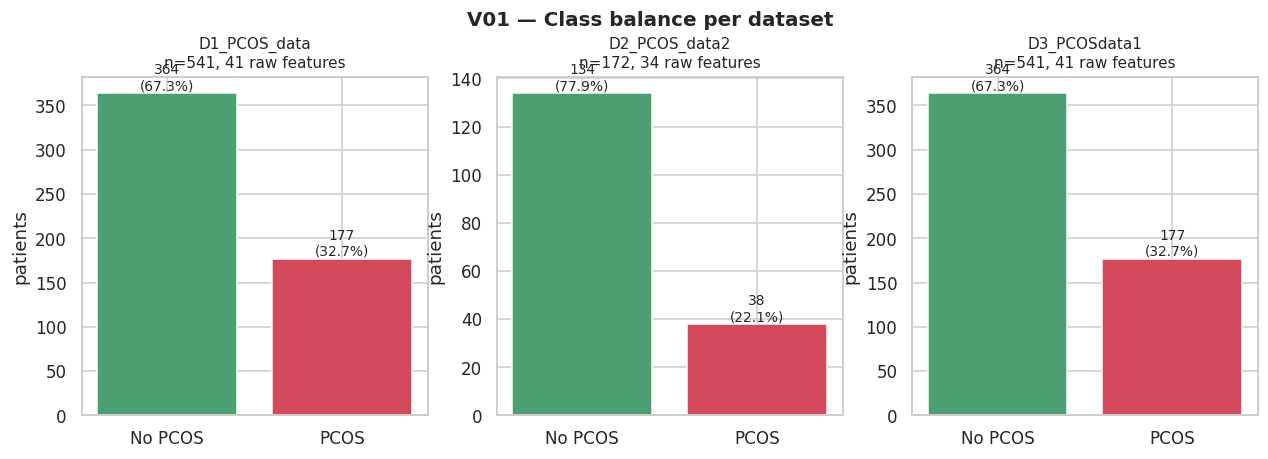

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V02_missingness.png


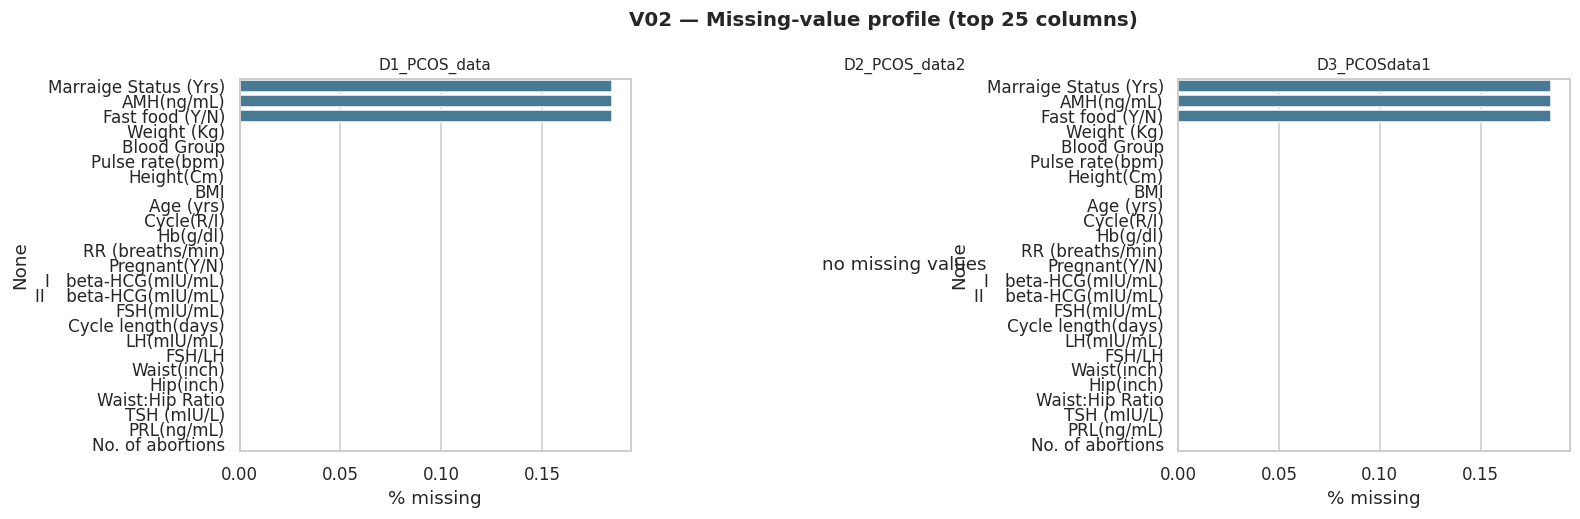

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V03_correlation_D1_PCOS_data.png


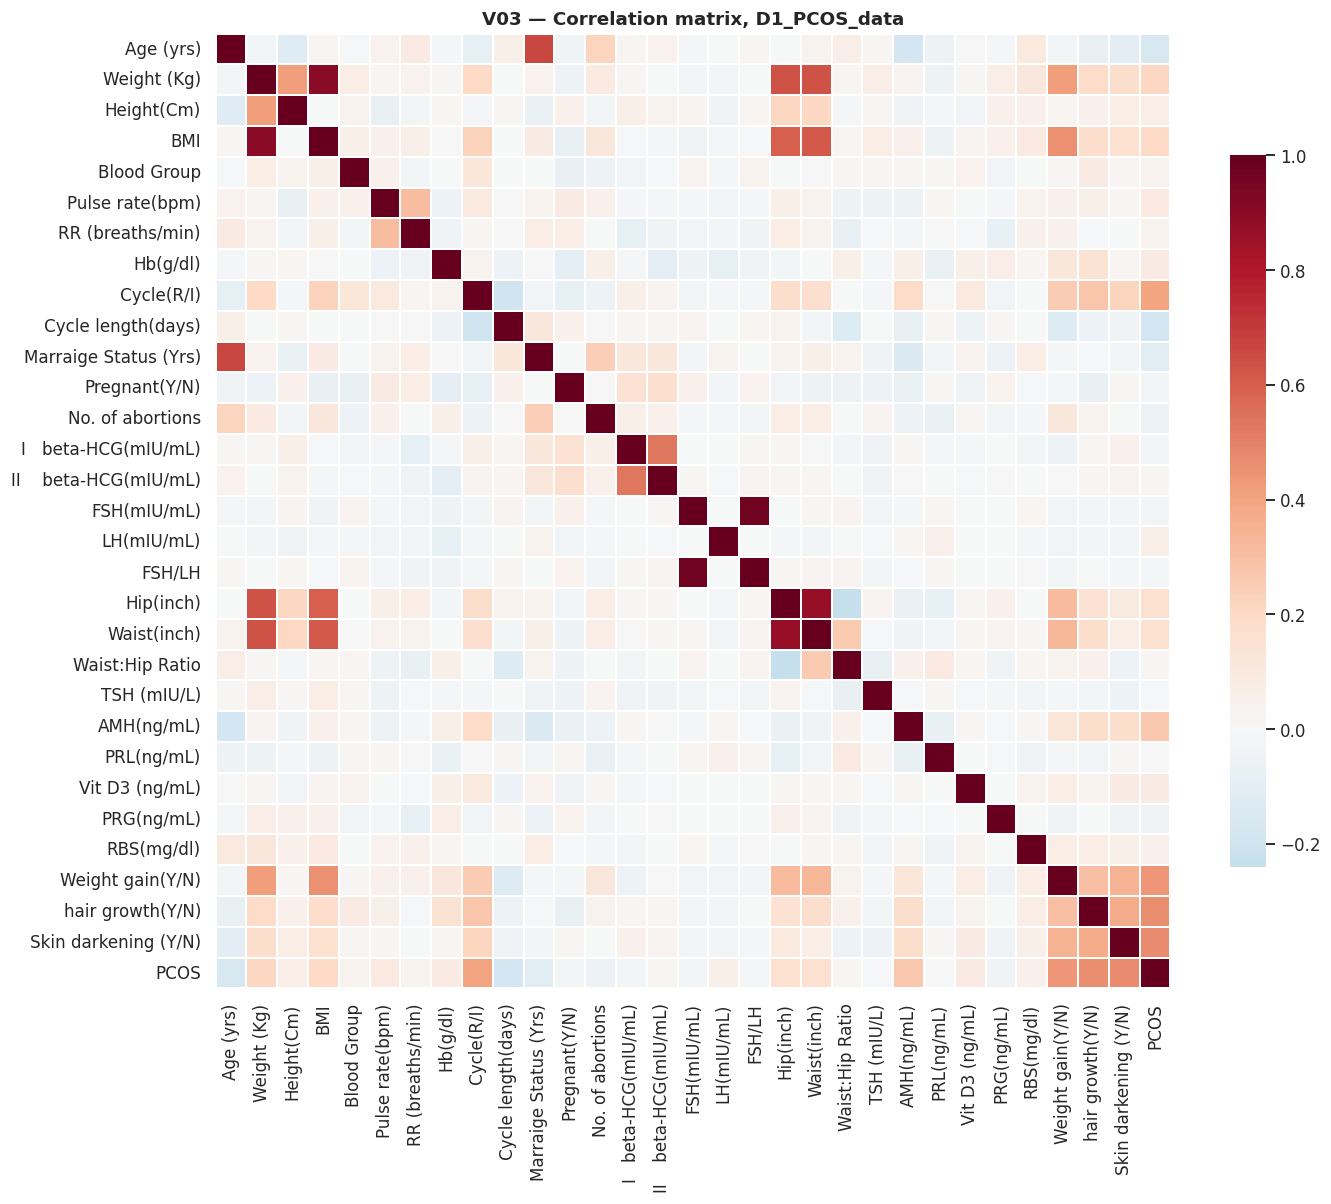

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V03_correlation_D2_PCOS_data2.png


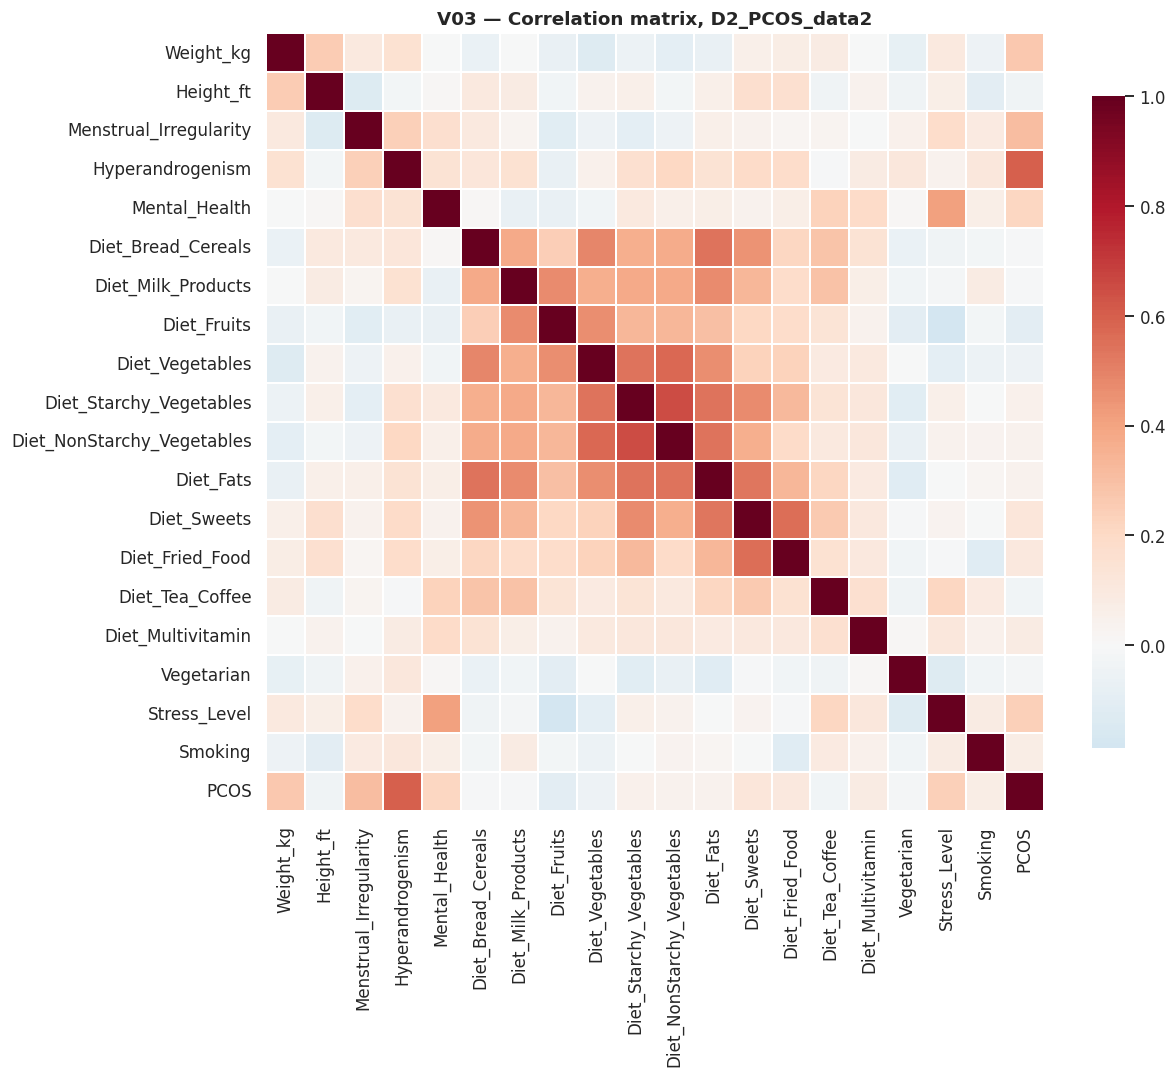

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V03_correlation_D3_PCOSdata1.png


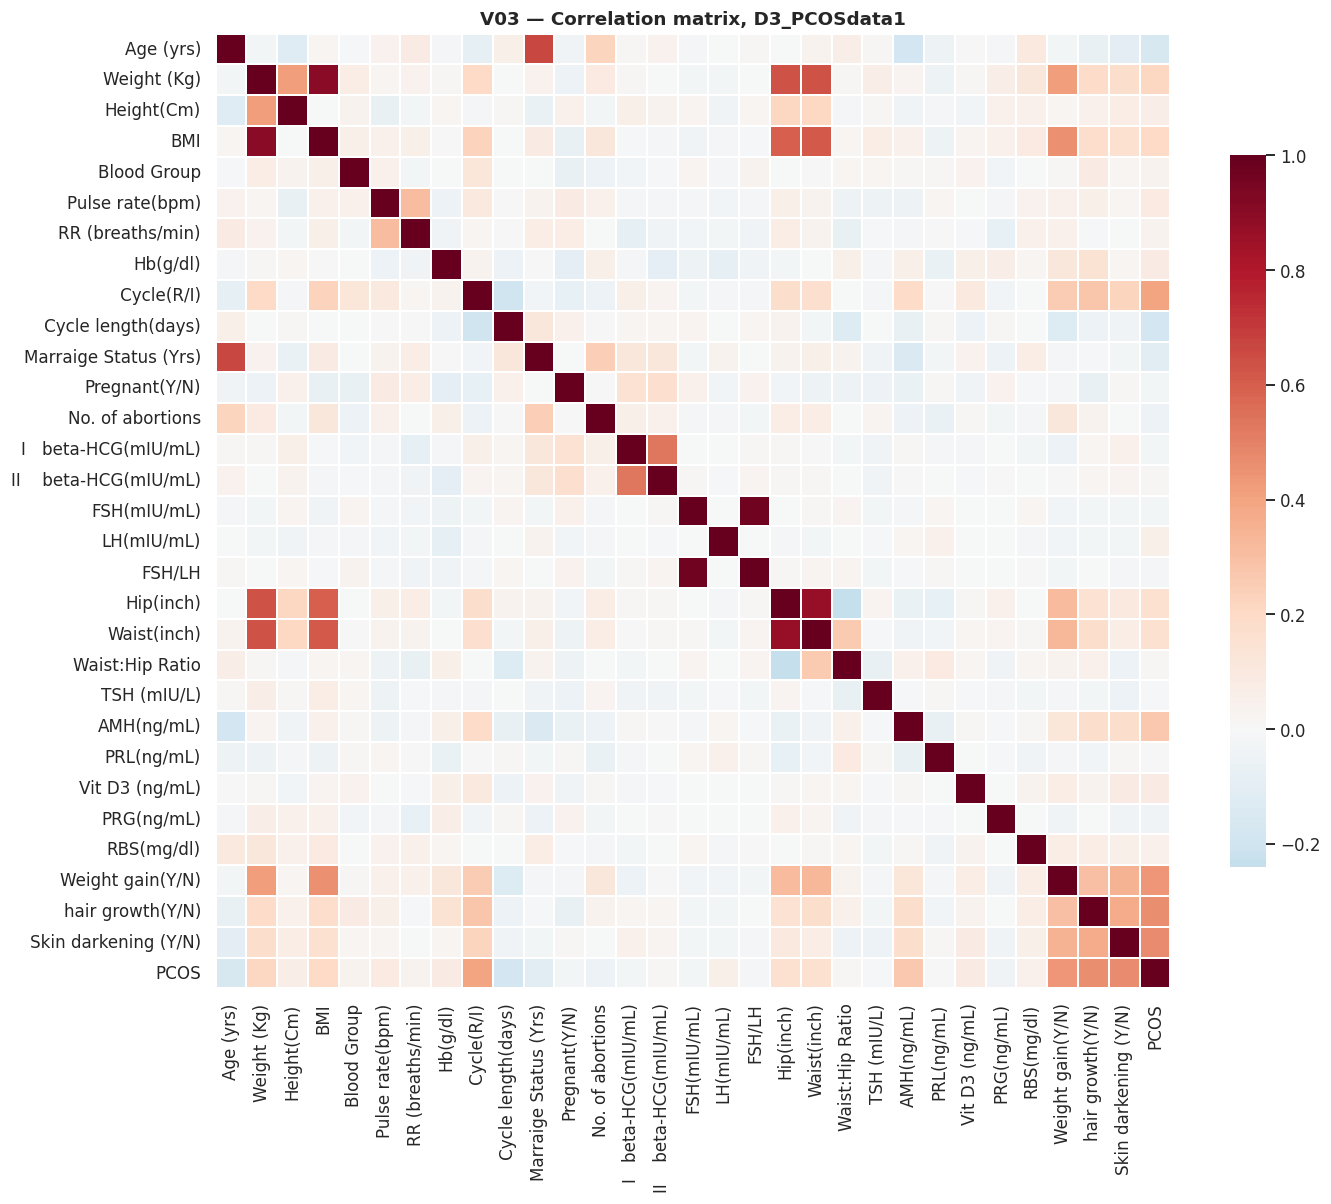

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V04_top_features_D1_PCOS_data.png


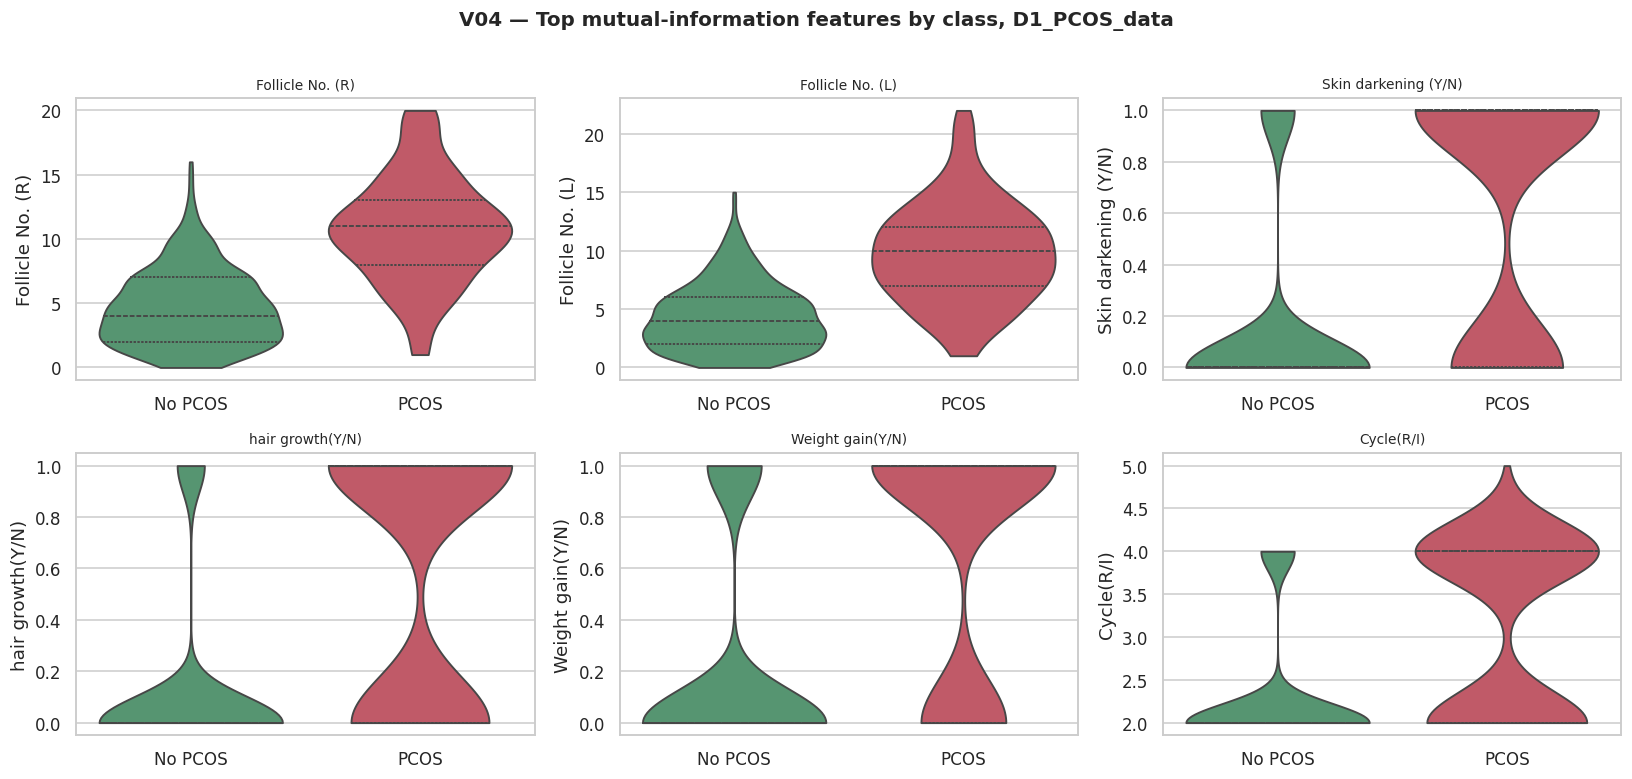

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V04_top_features_D2_PCOS_data2.png


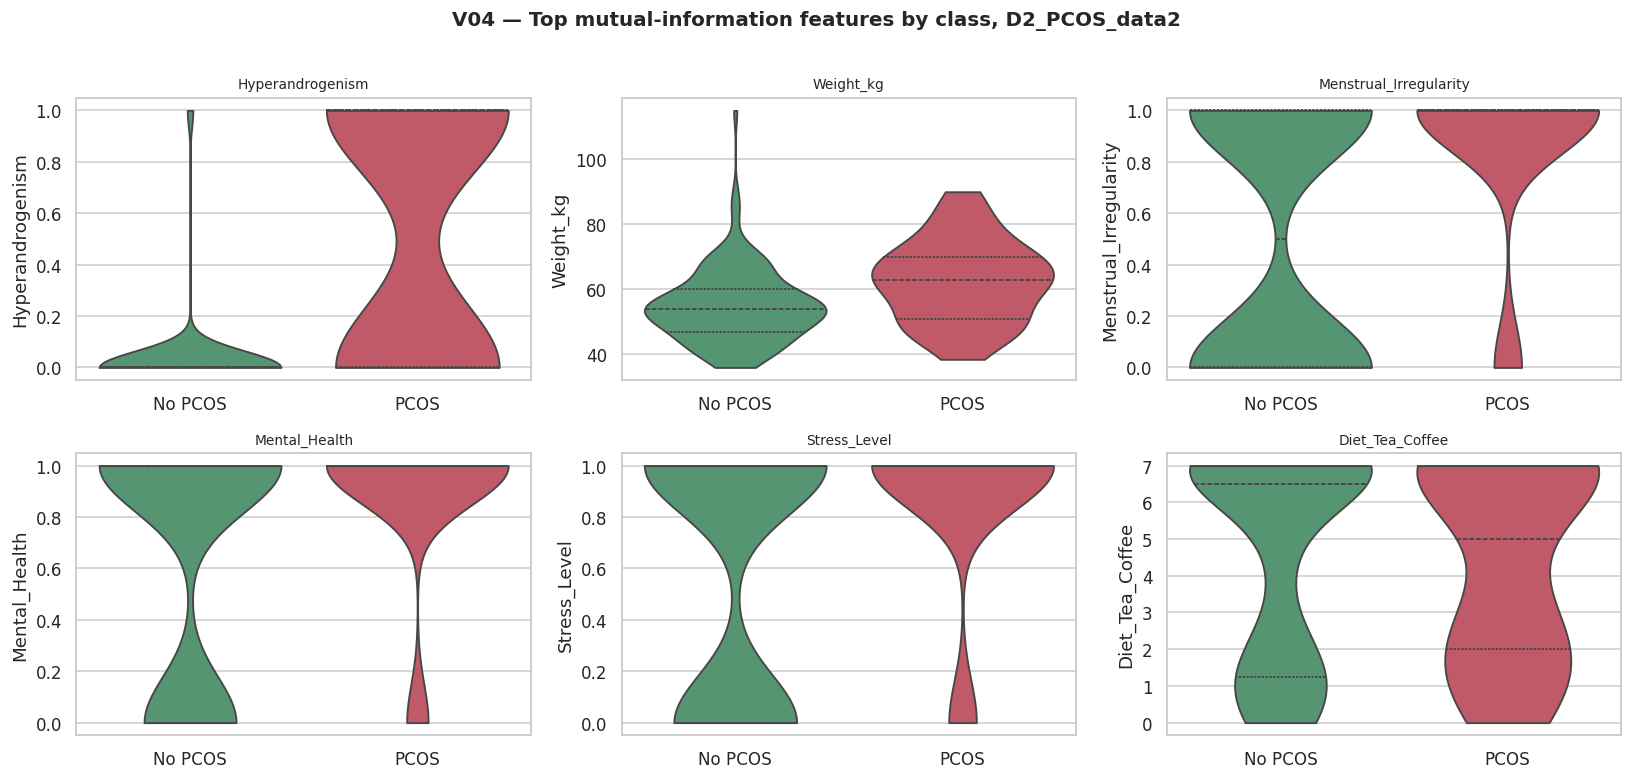

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V04_top_features_D3_PCOSdata1.png


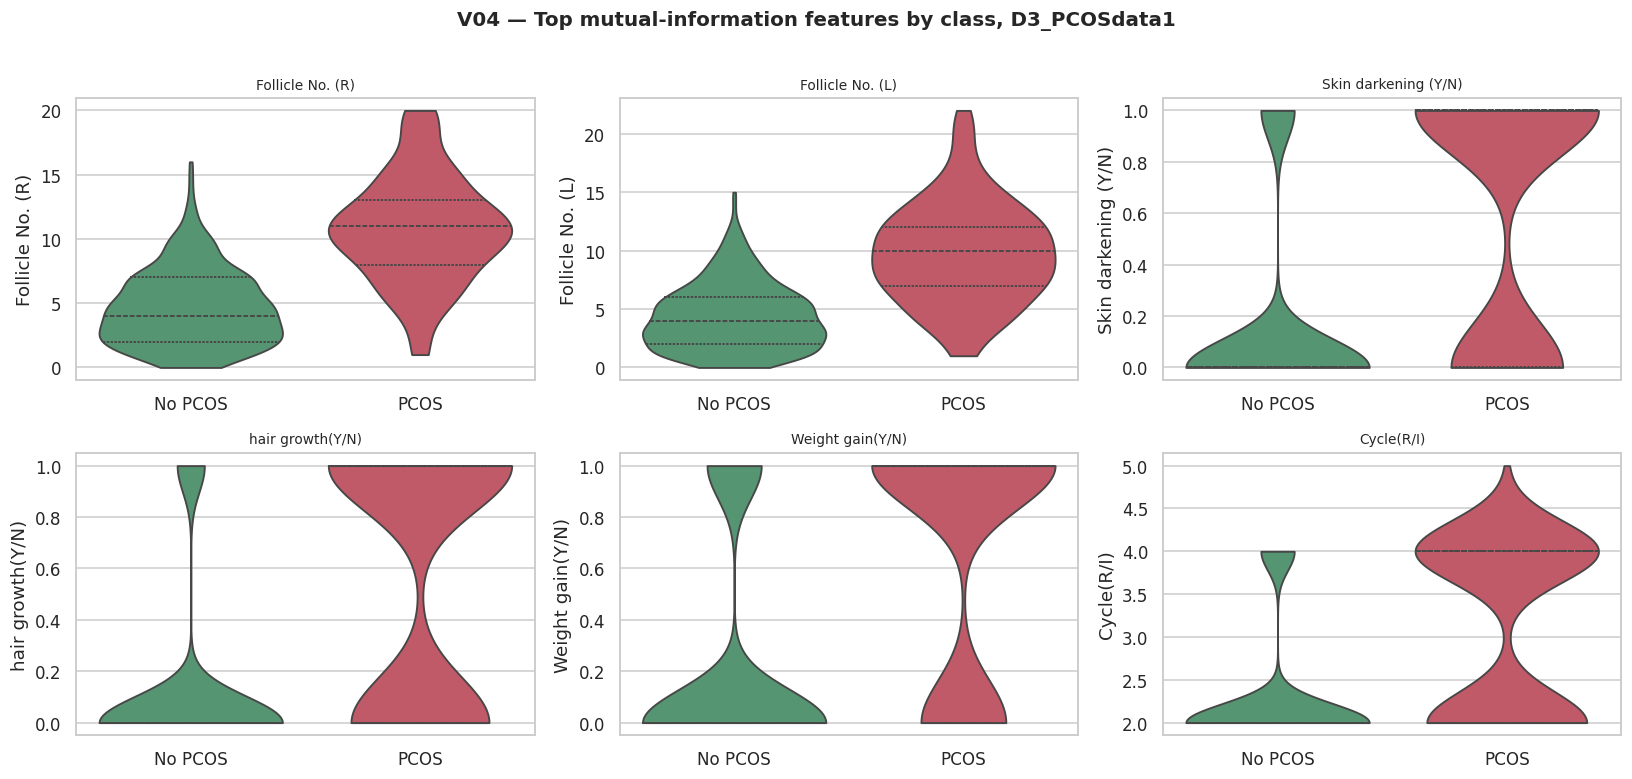

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V05_embeddings_D1_PCOS_data.png


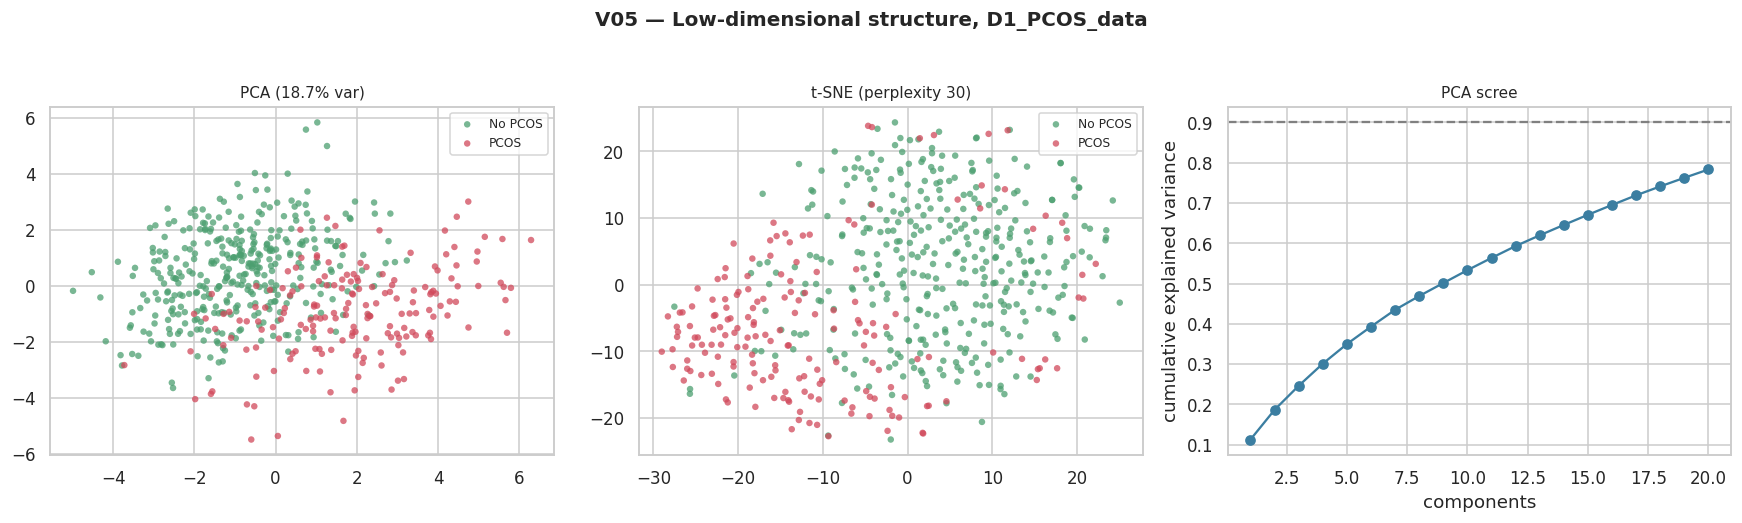

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V05_embeddings_D2_PCOS_data2.png


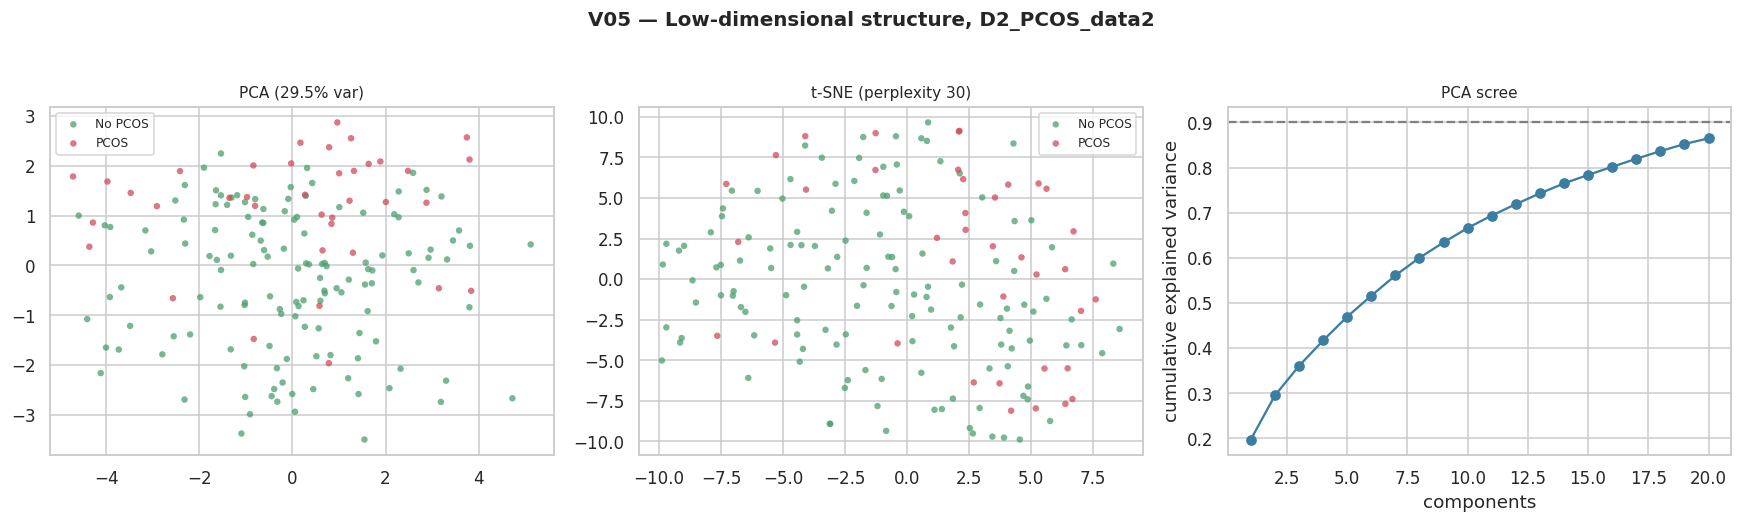

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V05_embeddings_D3_PCOSdata1.png


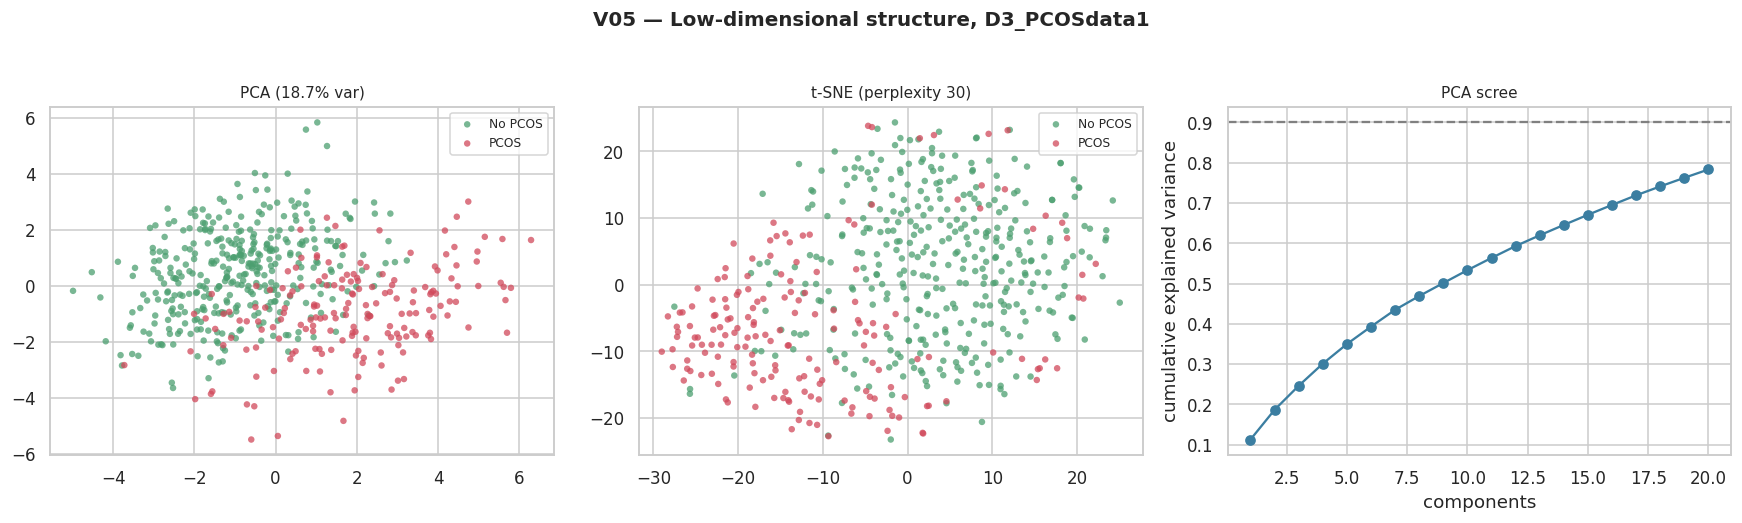

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V06_resampling.png


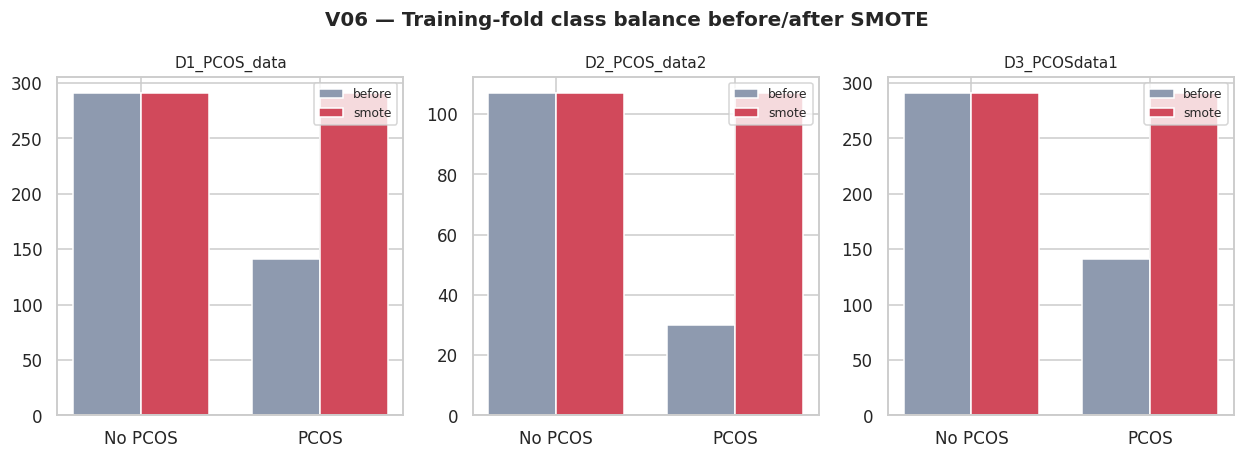

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V07_leaderboard_D1_PCOS_data.png


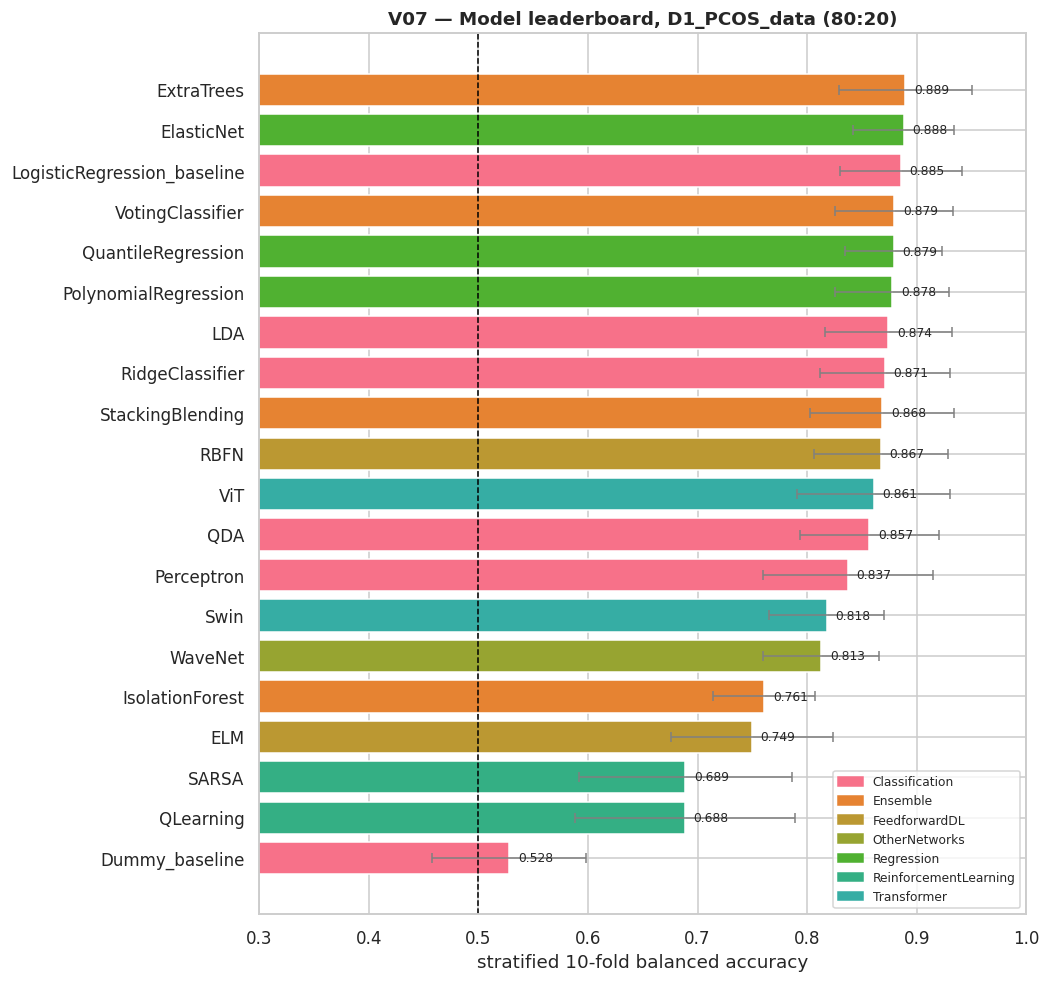

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V07_leaderboard_D2_PCOS_data2.png


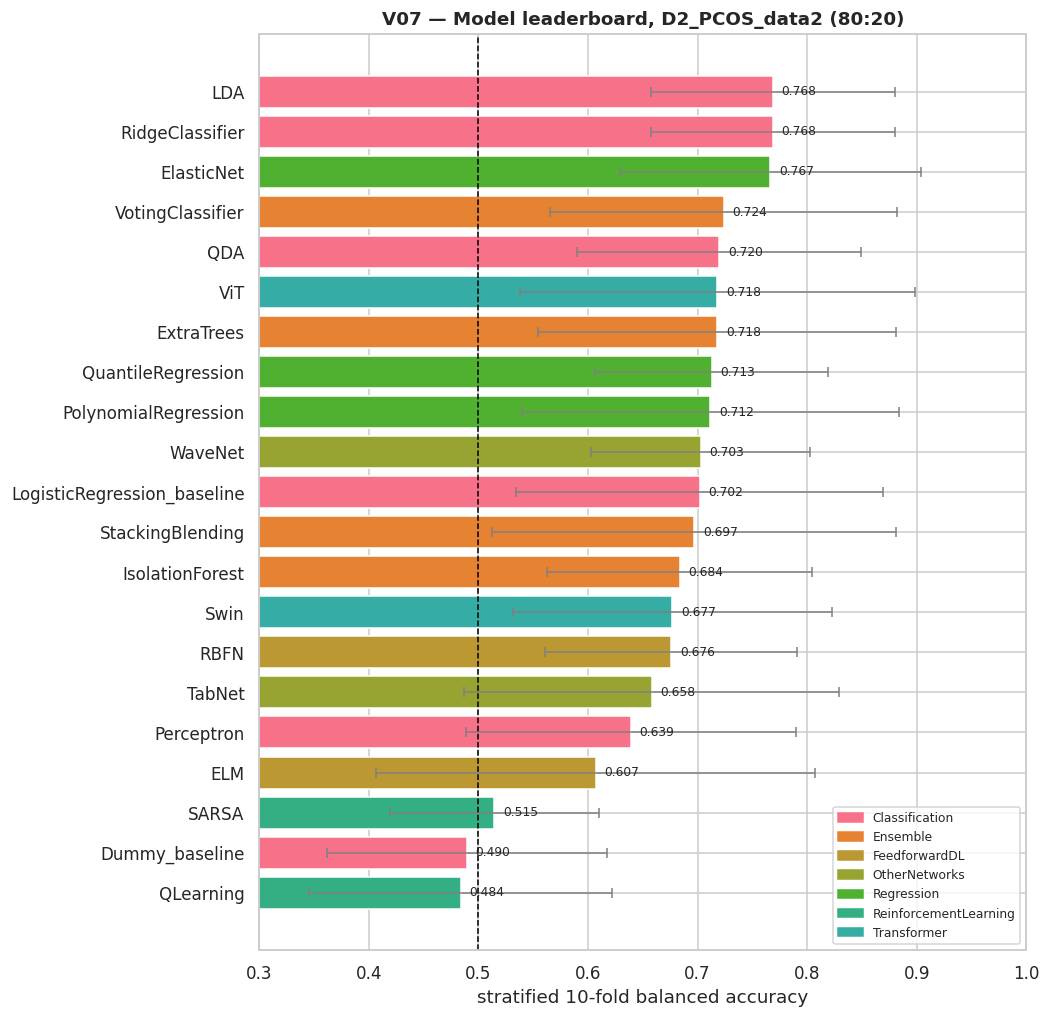

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V07_leaderboard_D3_PCOSdata1.png


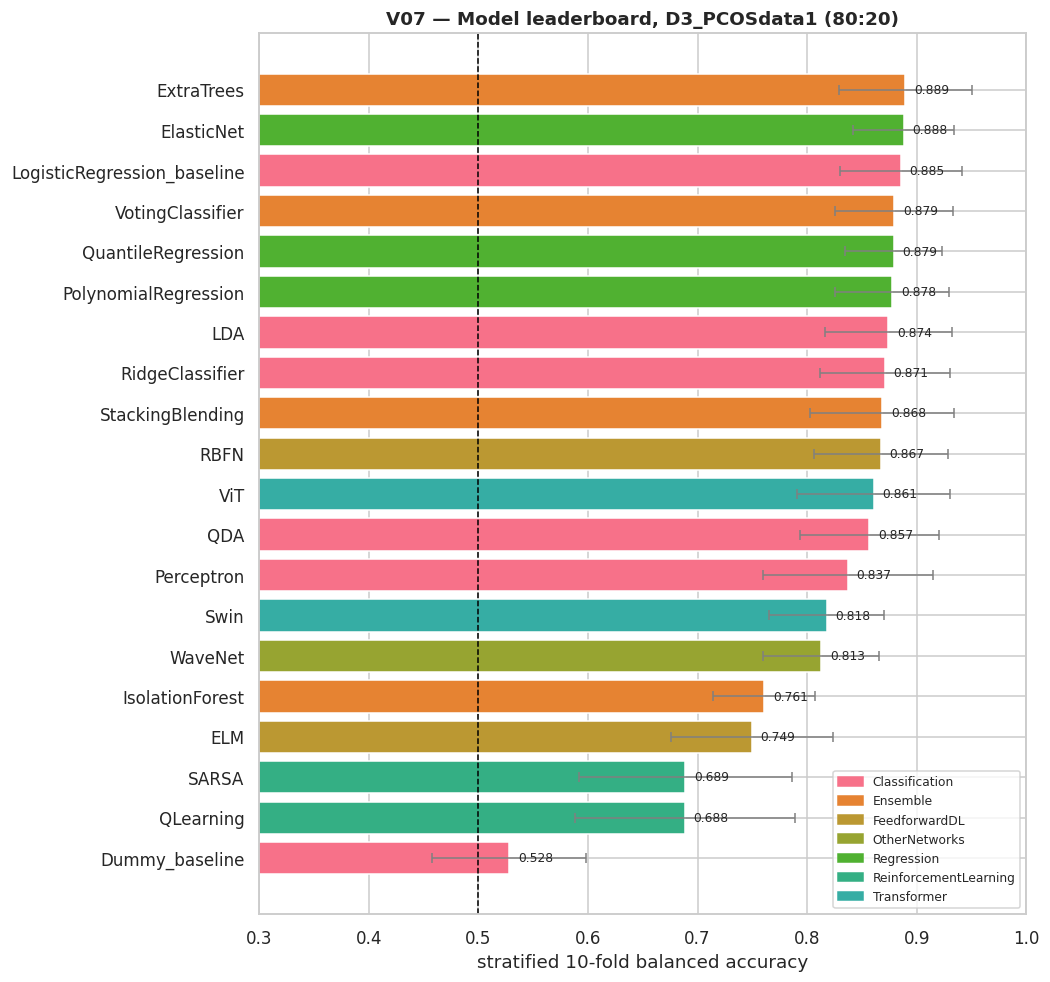

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V08_split_ratio_D1_PCOS_data.png


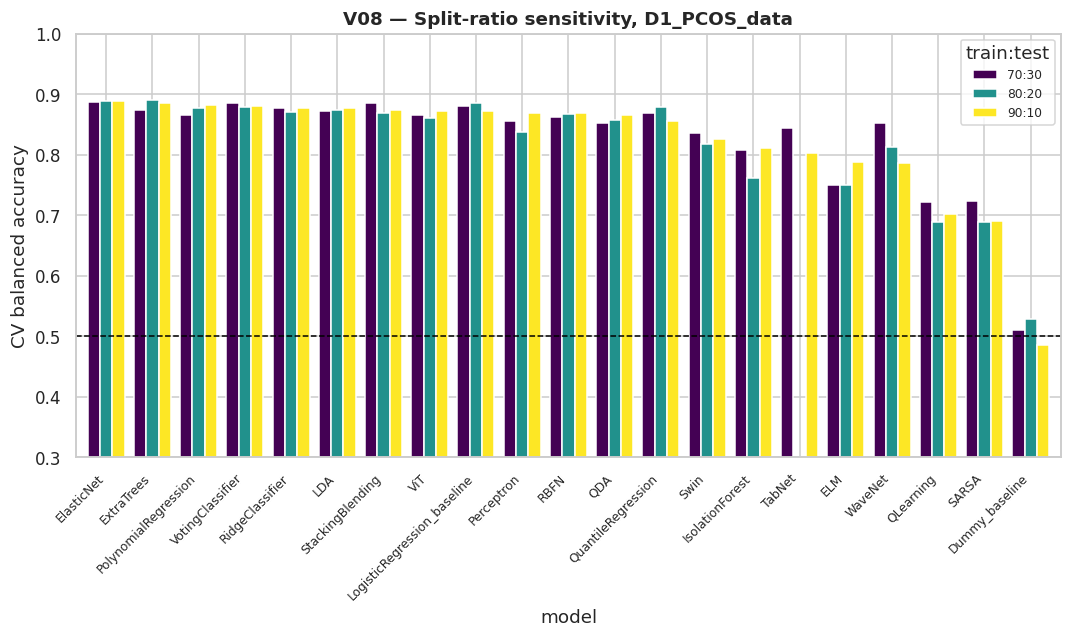

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V08_split_ratio_D2_PCOS_data2.png


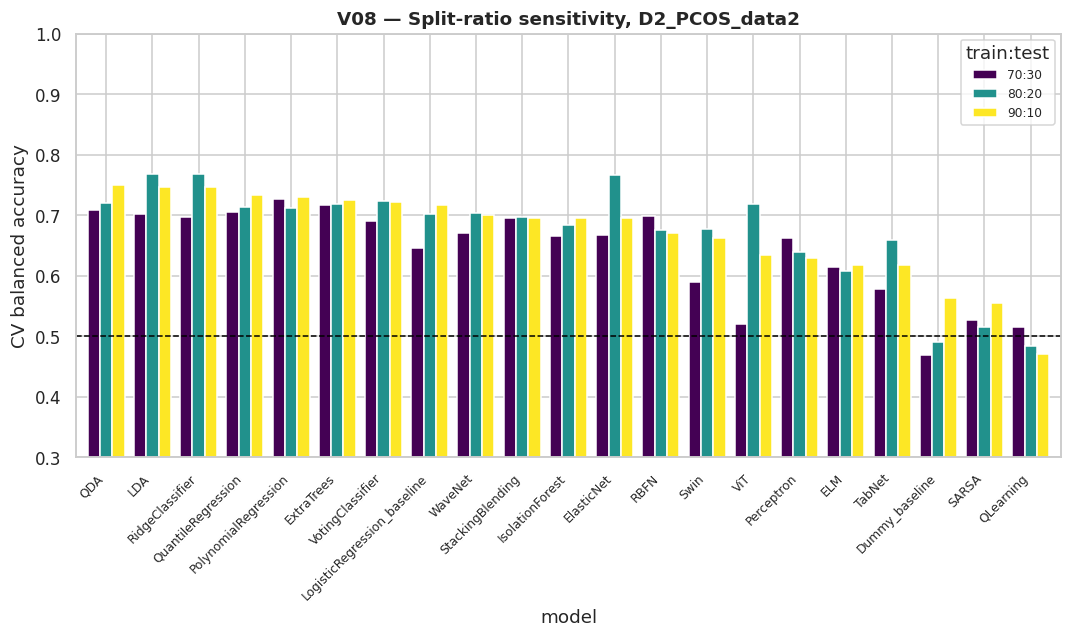

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V08_split_ratio_D3_PCOSdata1.png


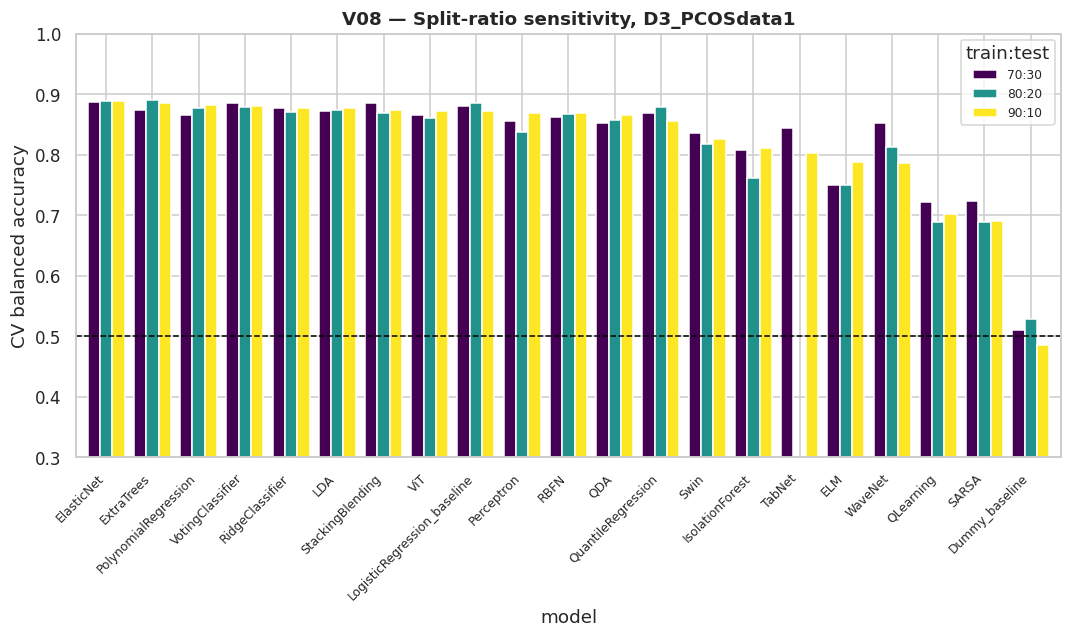

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V09_roc_D1_PCOS_data.png


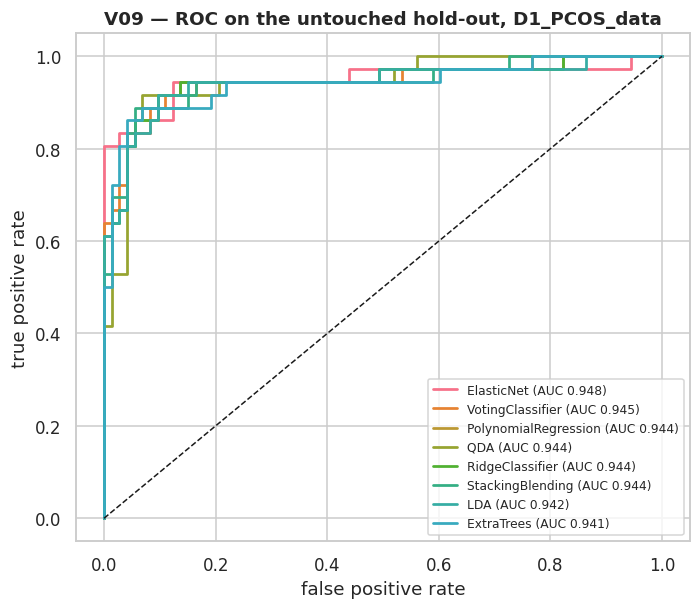

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V10_pr_D1_PCOS_data.png


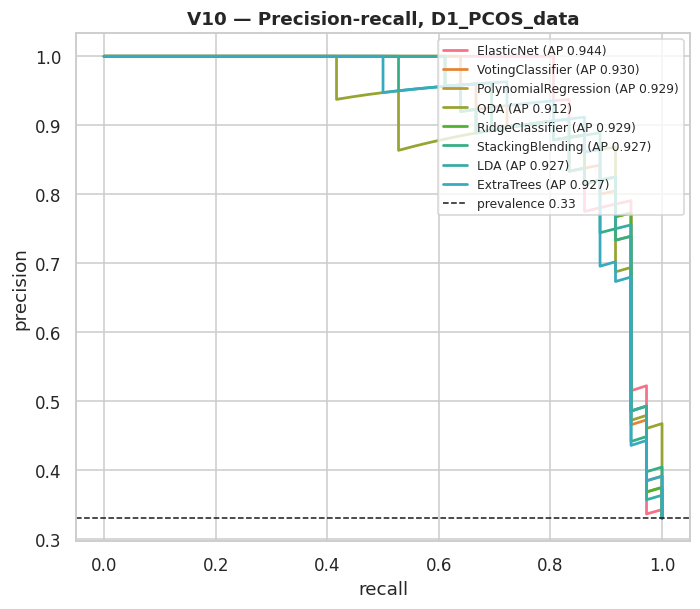

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V09_roc_D2_PCOS_data2.png


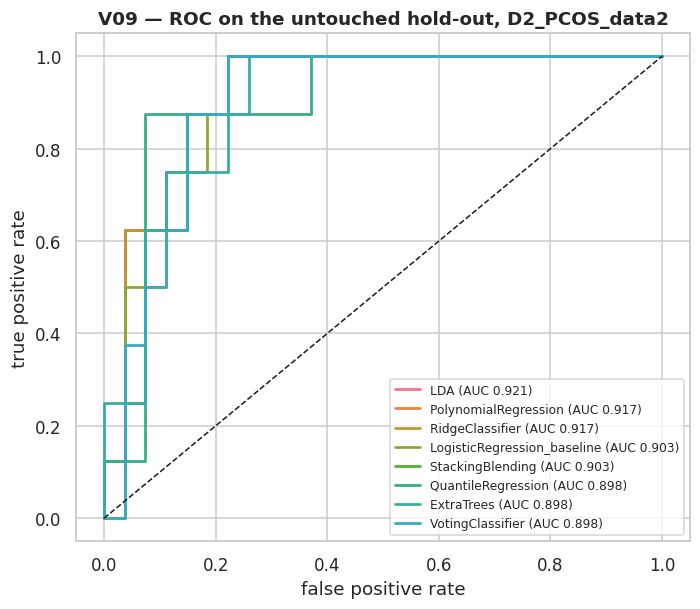

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V10_pr_D2_PCOS_data2.png


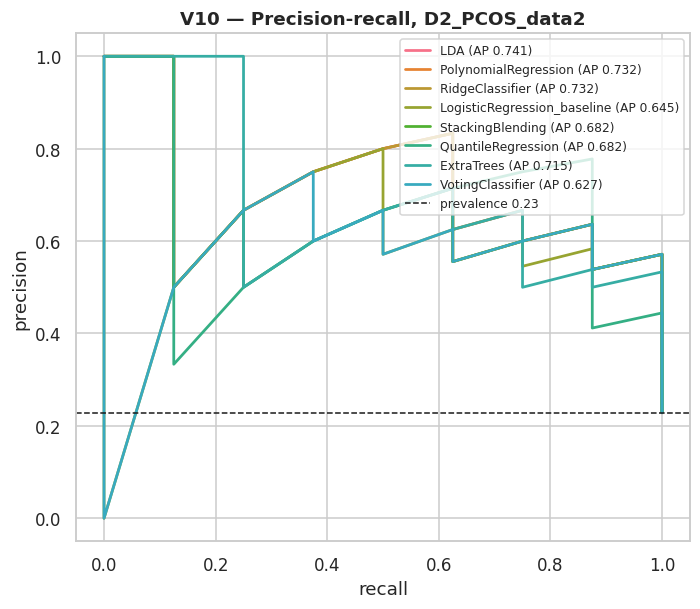

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V09_roc_D3_PCOSdata1.png


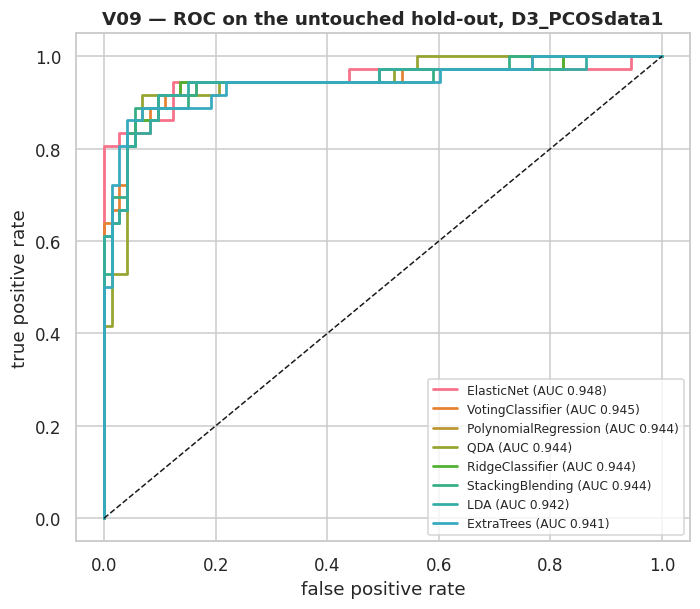

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V10_pr_D3_PCOSdata1.png


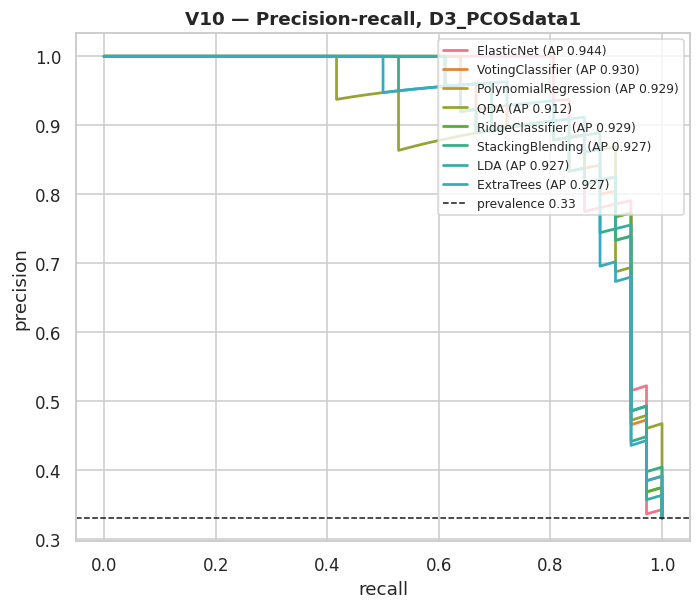

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V11_confusion_D1_PCOS_data.png


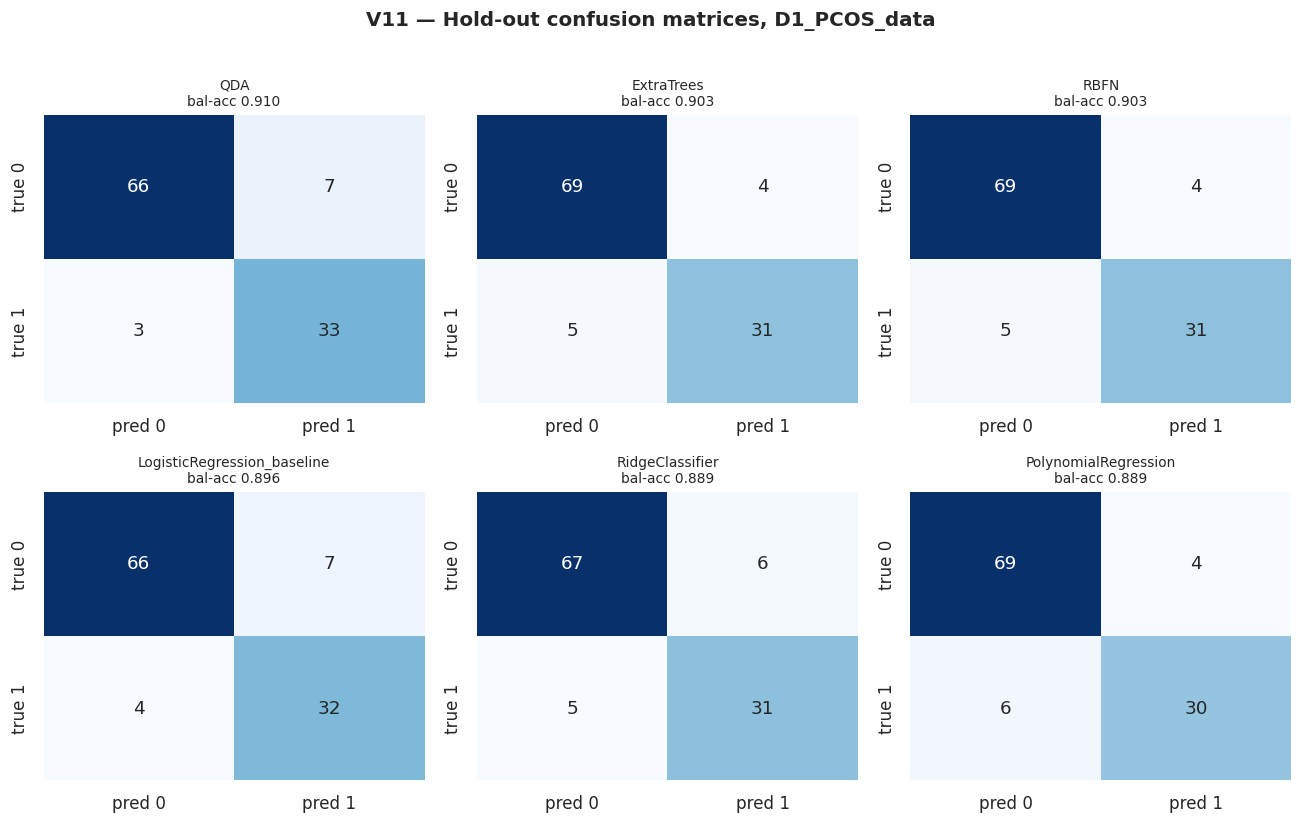

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V11_confusion_D2_PCOS_data2.png


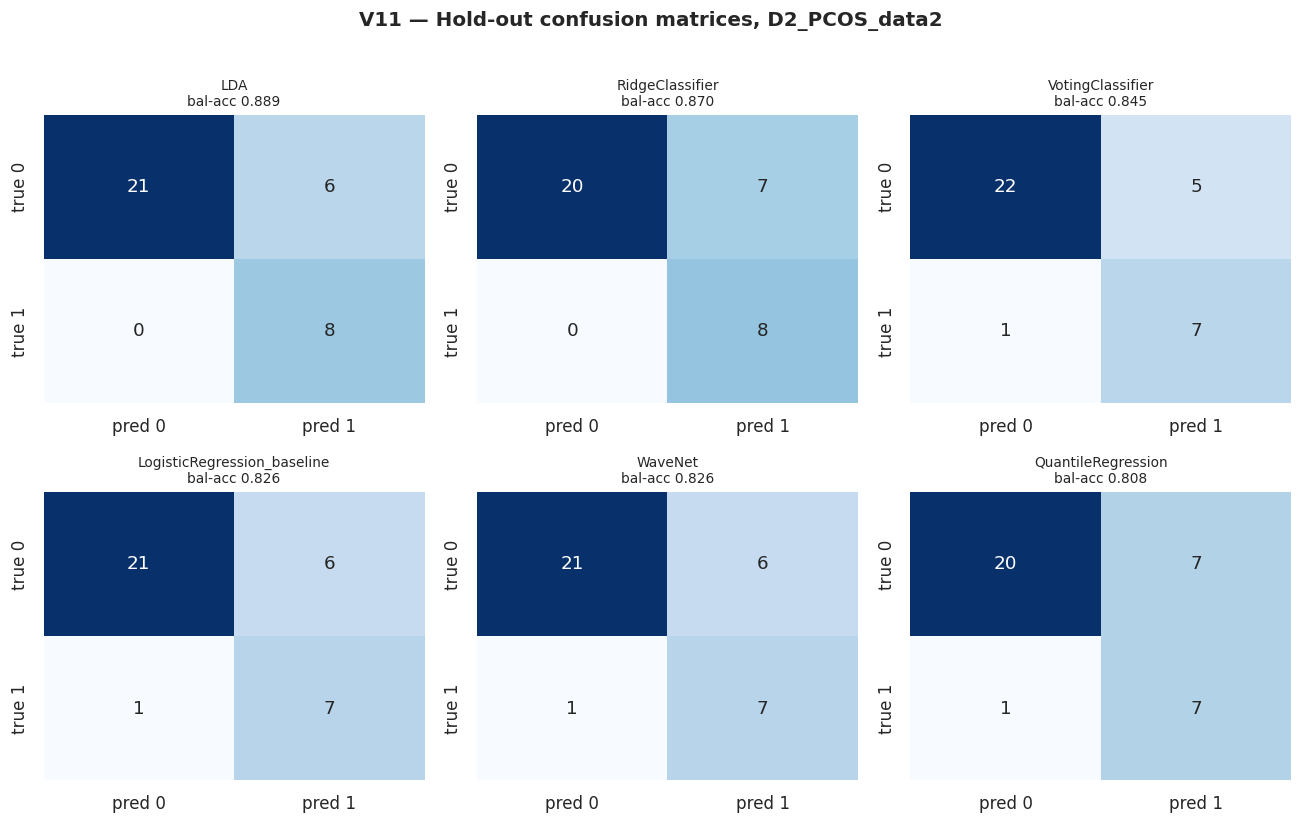

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V11_confusion_D3_PCOSdata1.png


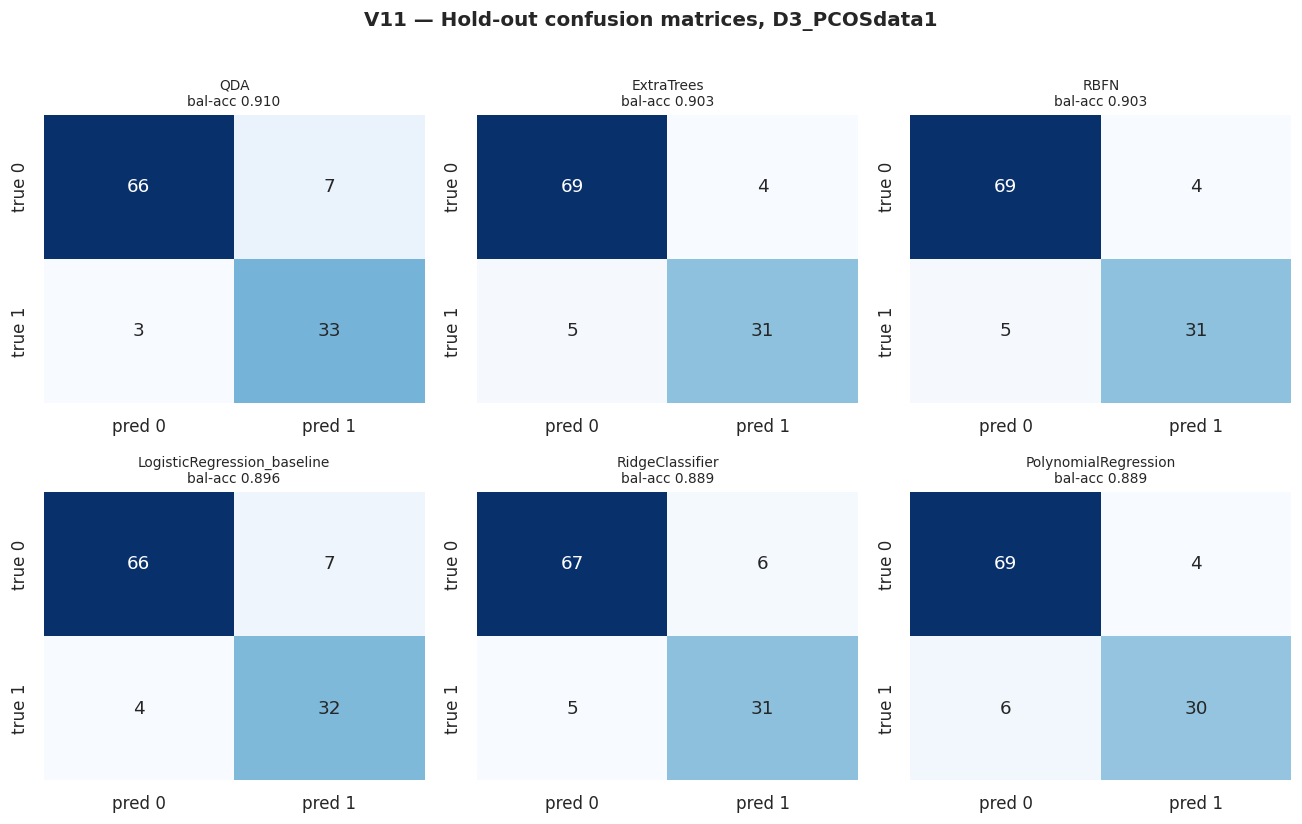

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V12_fold_spread_D1_PCOS_data.png


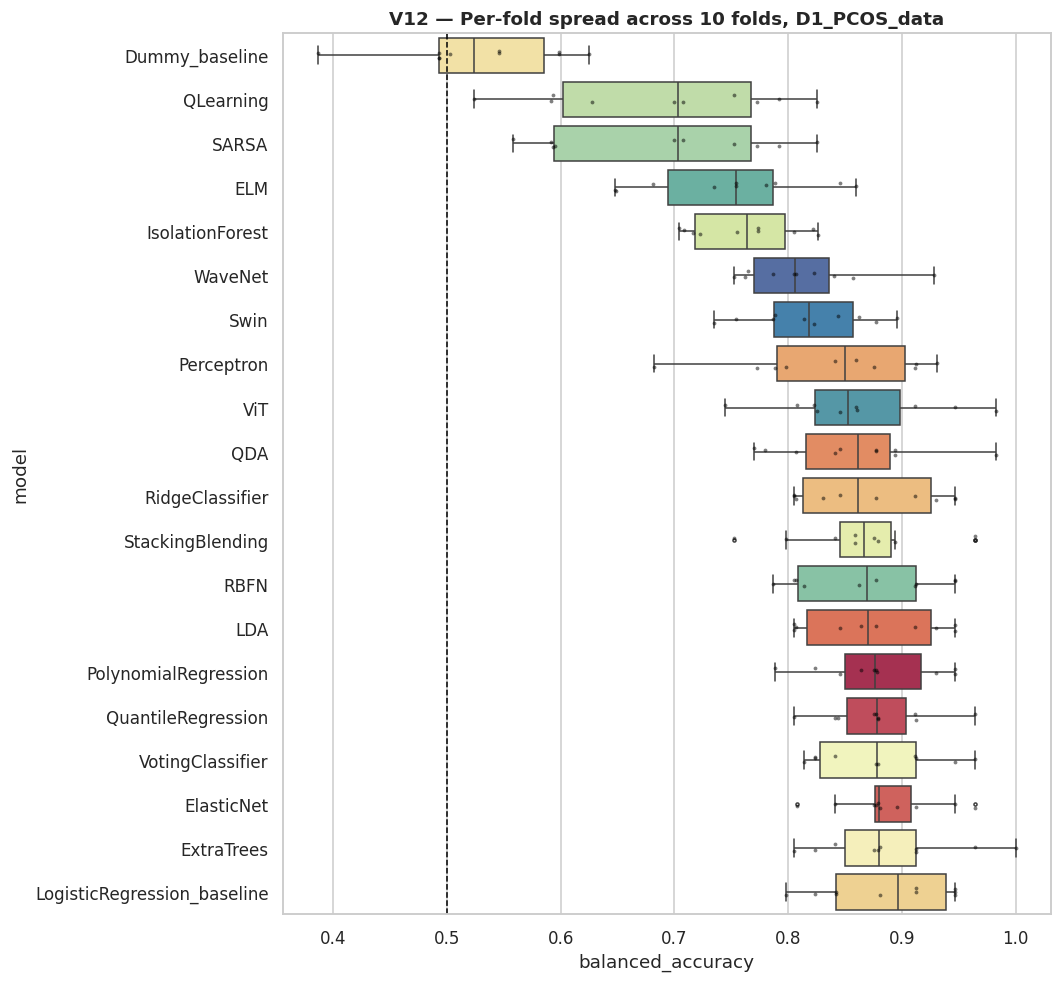

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V12_fold_spread_D2_PCOS_data2.png


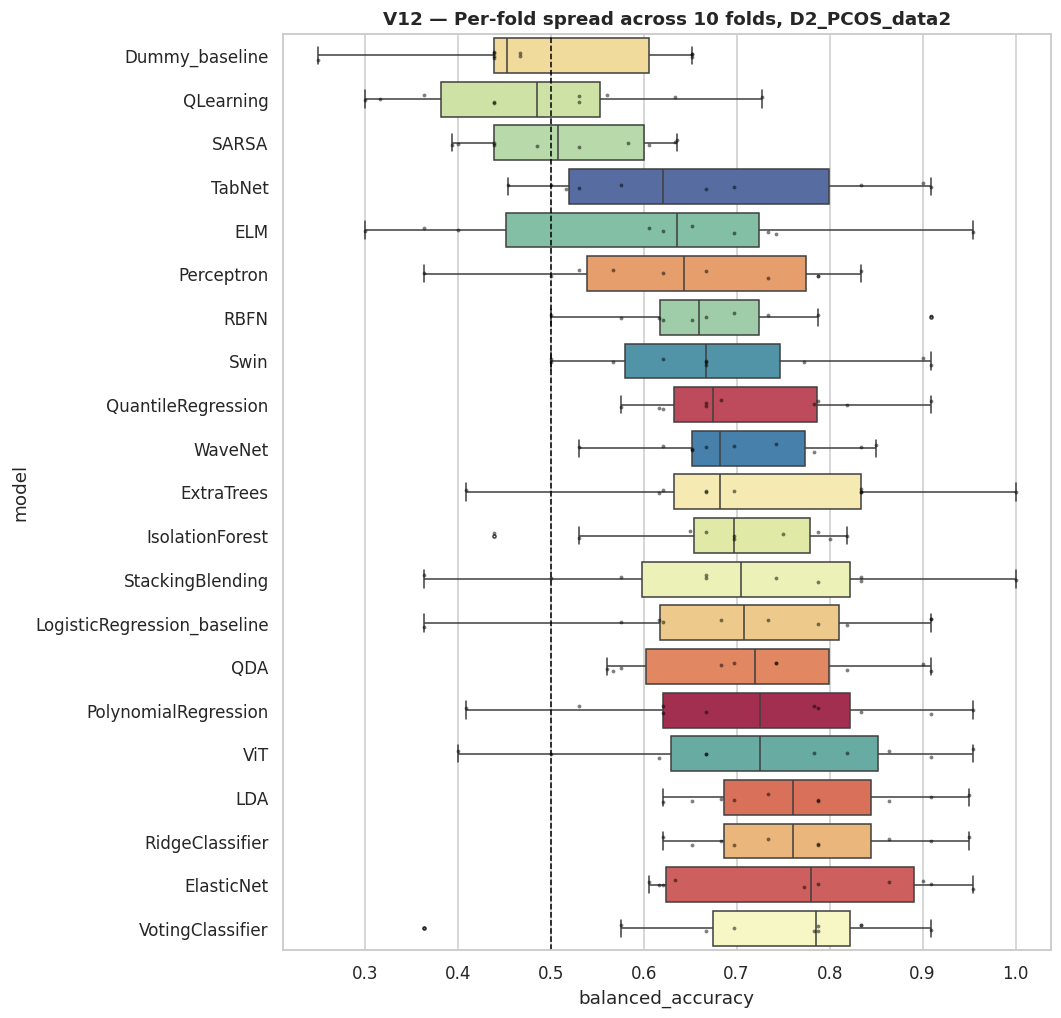

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V12_fold_spread_D3_PCOSdata1.png


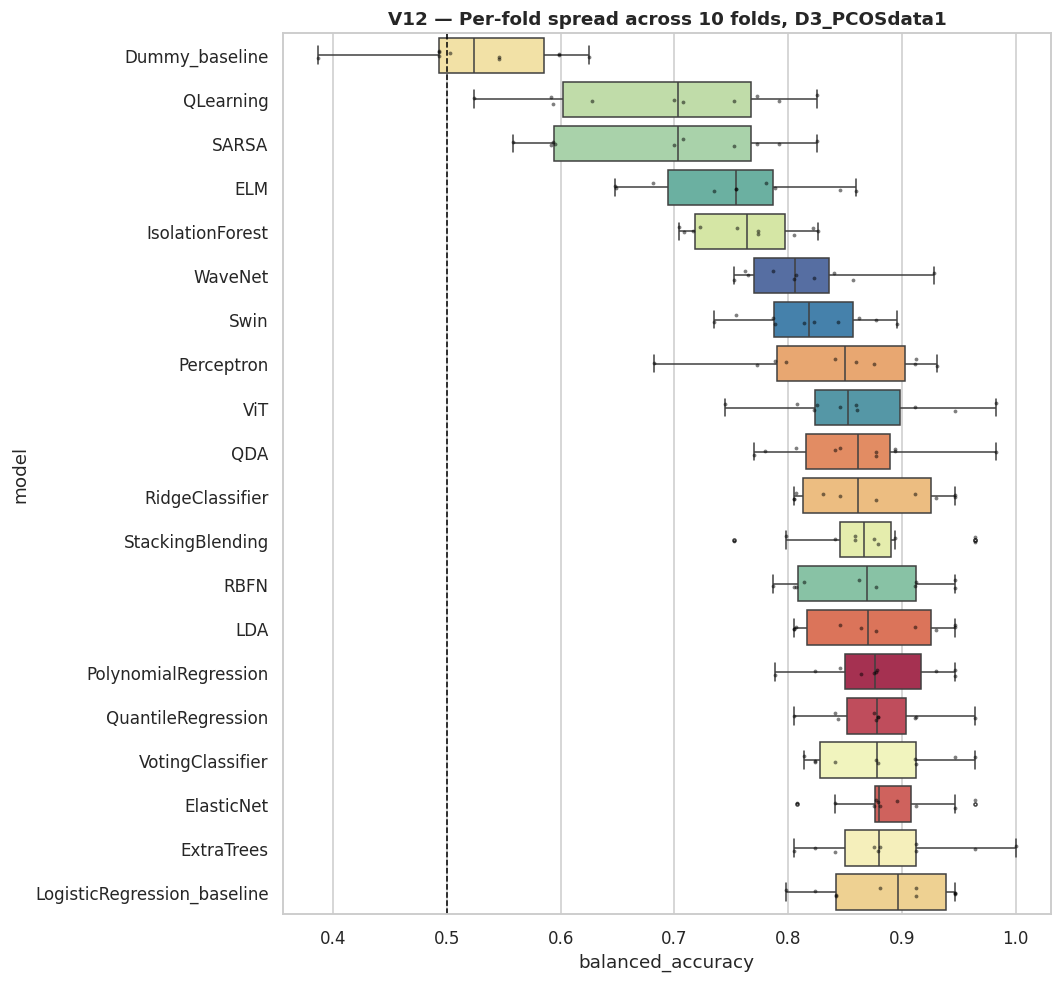

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V13_calibration_D1_PCOS_data.png


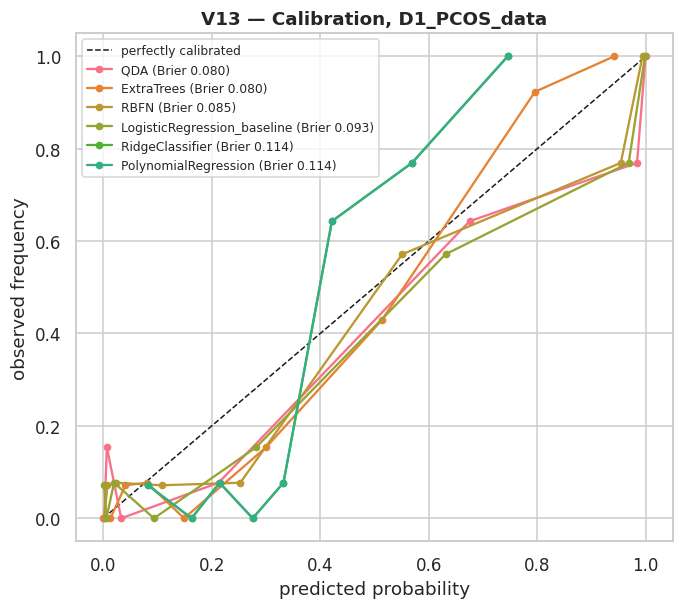

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V13_calibration_D2_PCOS_data2.png


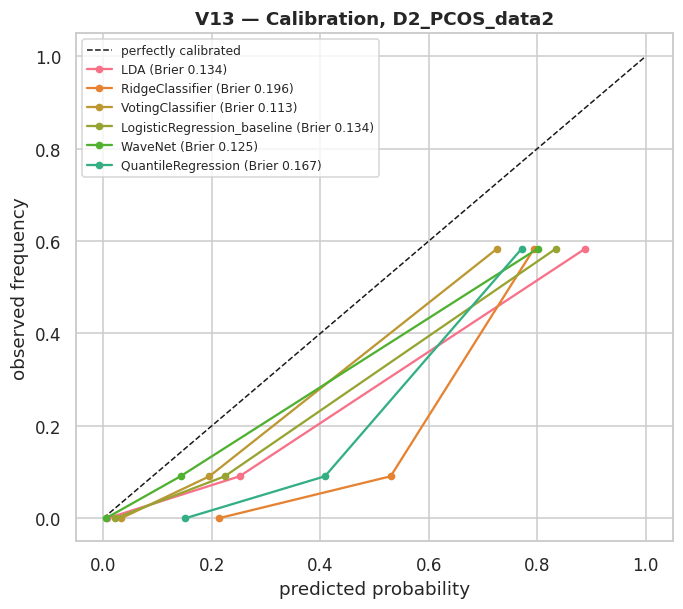

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V13_calibration_D3_PCOSdata1.png


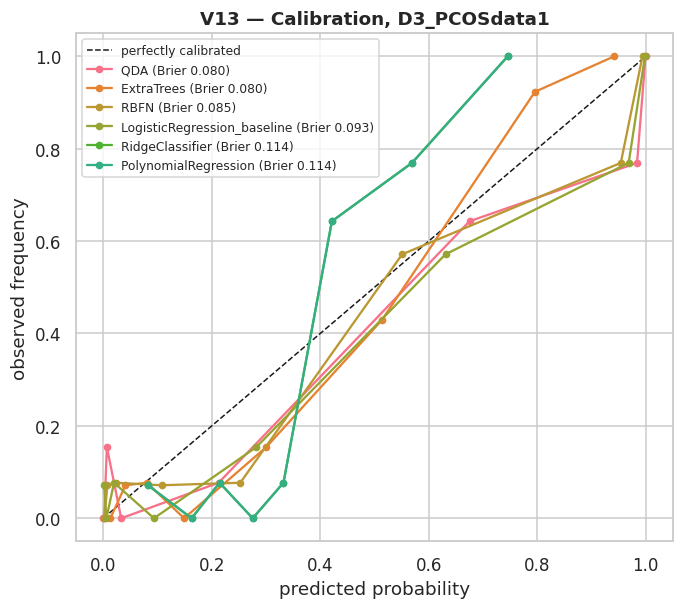

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14_shap_beeswarm_D1_PCOS_data_ExtraTrees.png


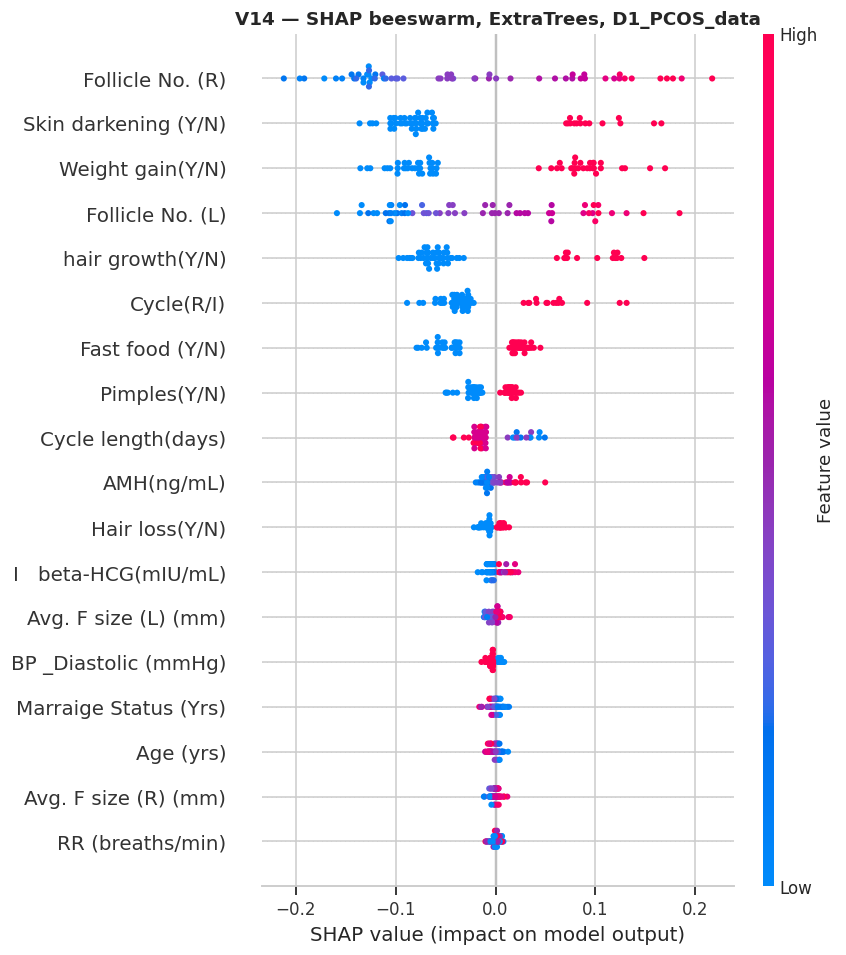

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14b_shap_bar_D1_PCOS_data_ExtraTrees.png


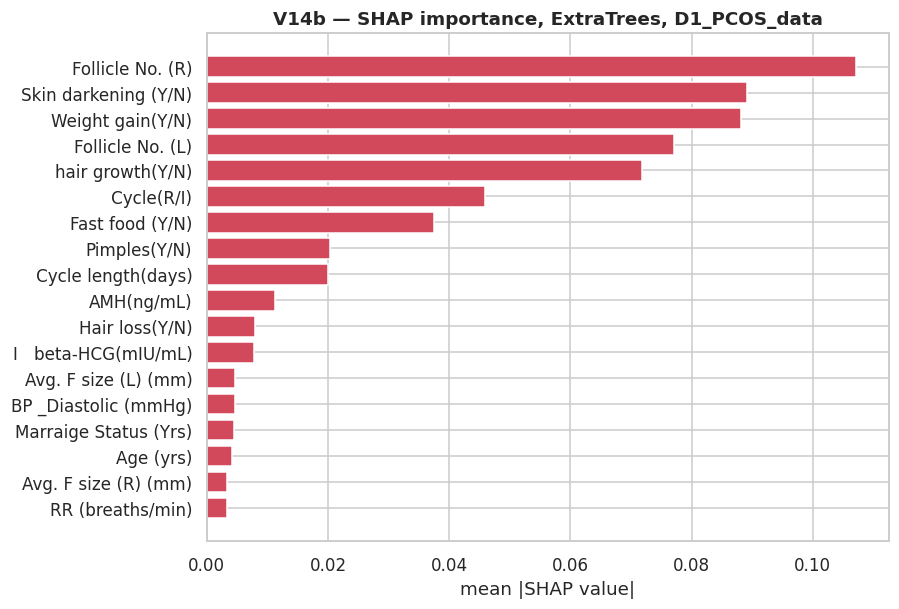

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14_shap_beeswarm_D2_PCOS_data2_ExtraTrees.png


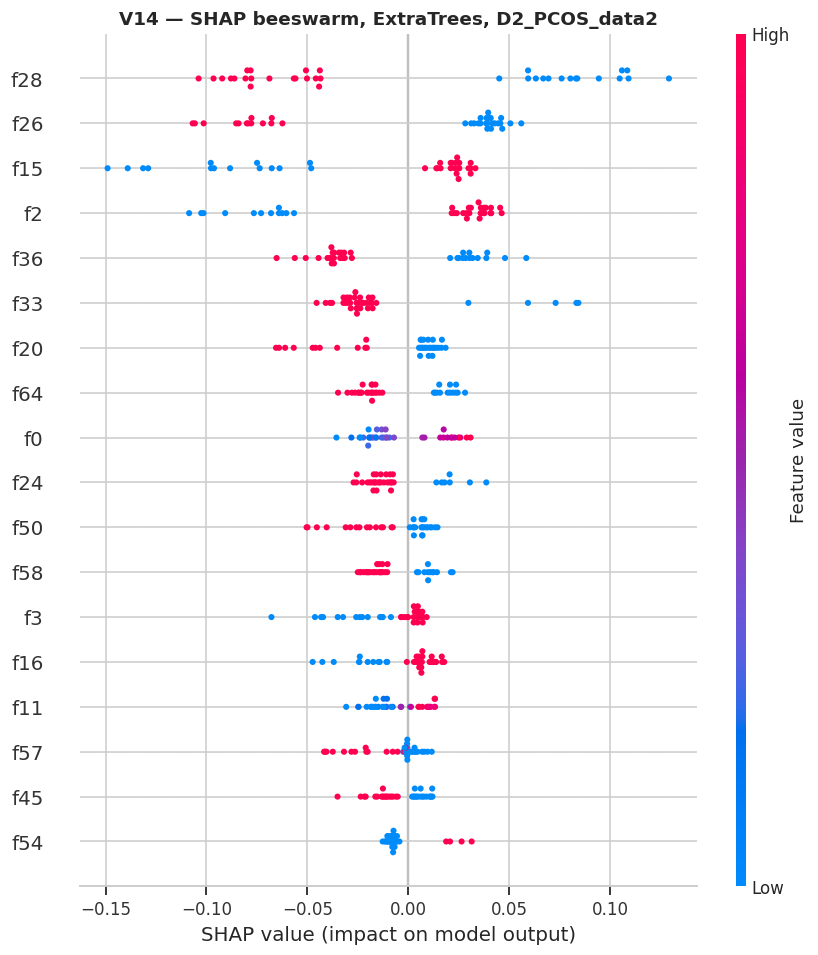

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14b_shap_bar_D2_PCOS_data2_ExtraTrees.png


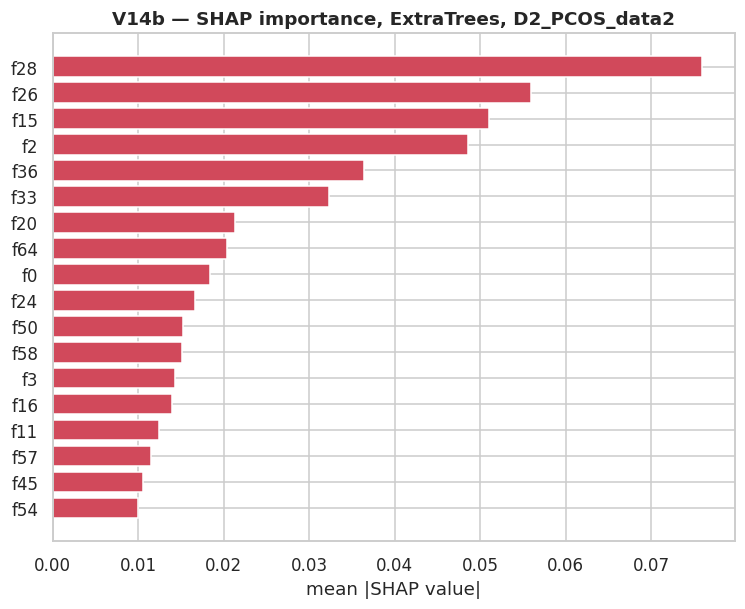

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14_shap_beeswarm_D3_PCOSdata1_ExtraTrees.png


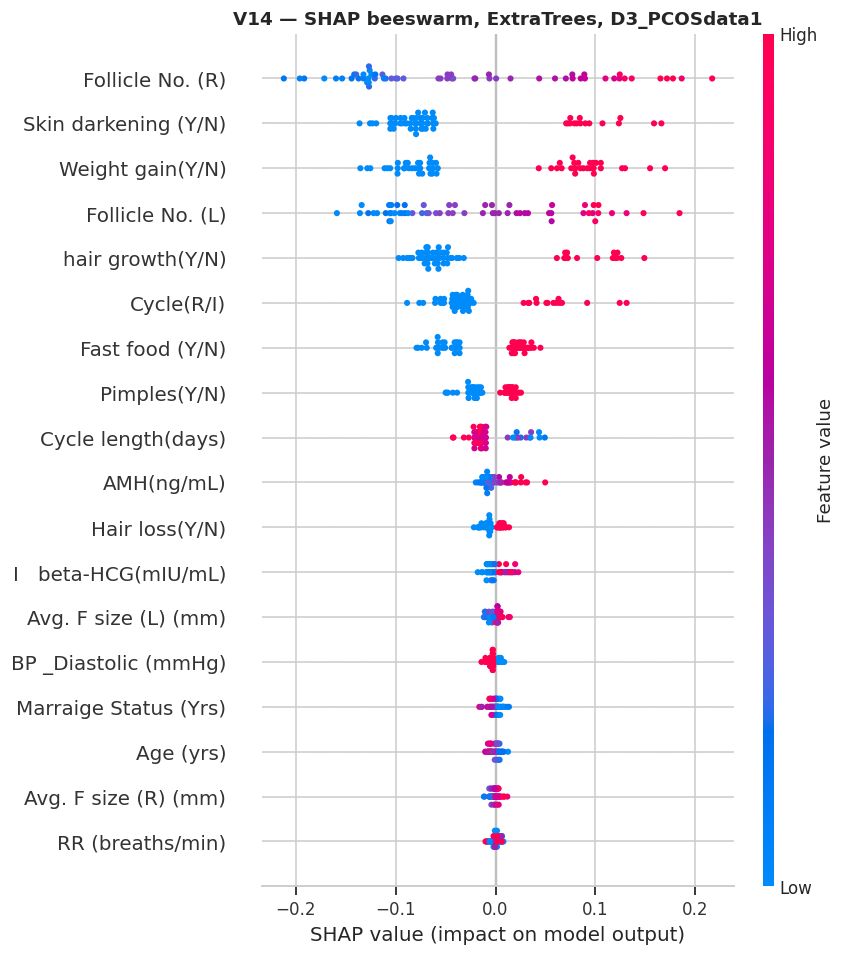

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V14b_shap_bar_D3_PCOSdata1_ExtraTrees.png


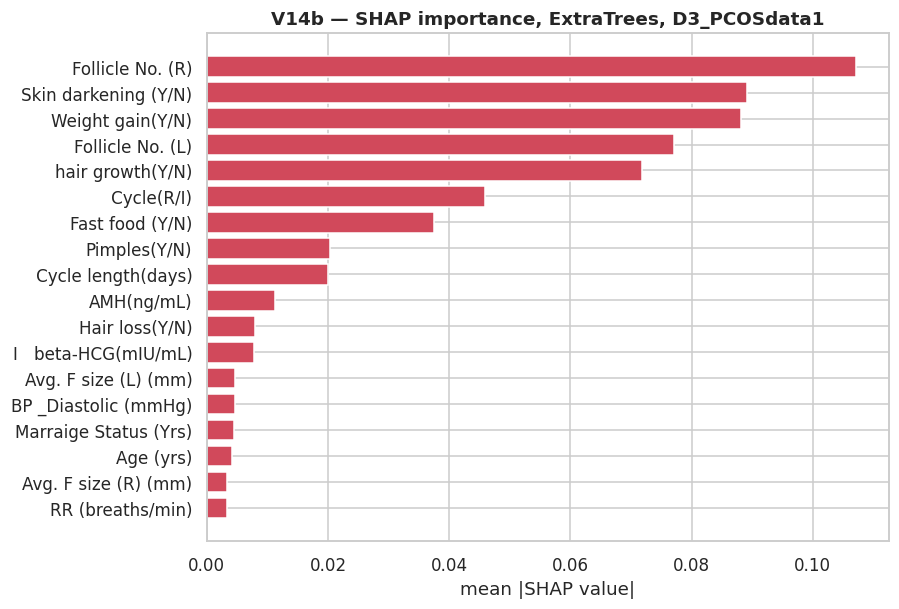

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V15_shap_consensus_D1_PCOS_data.png


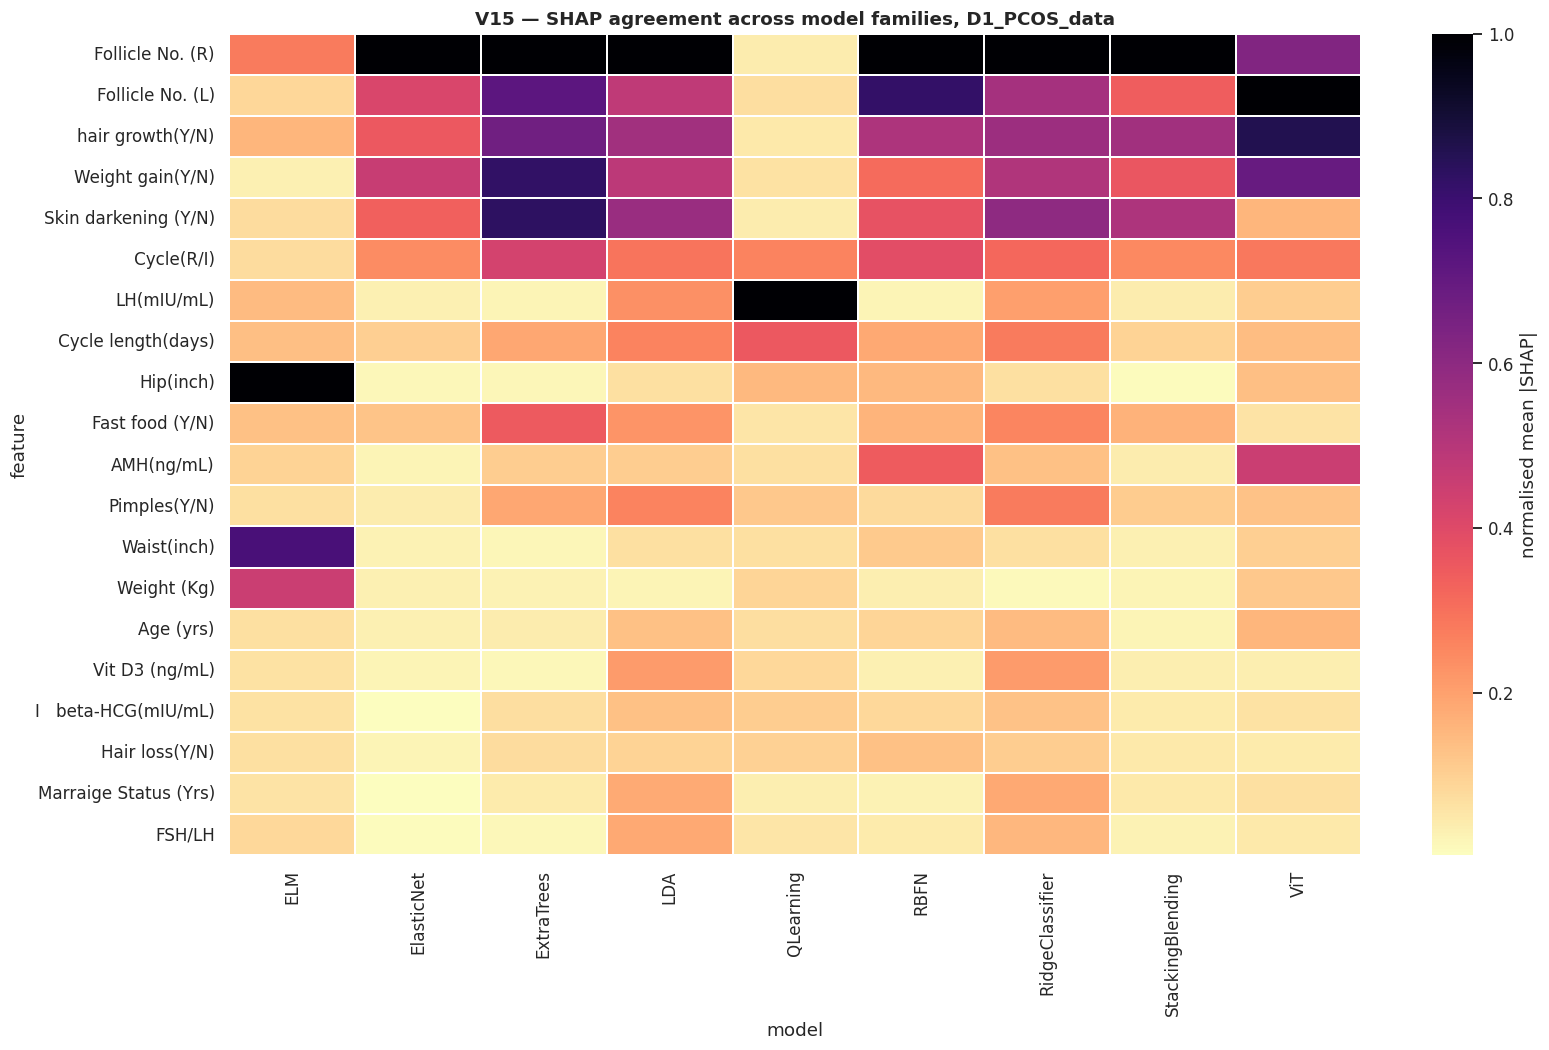

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V15_shap_consensus_D2_PCOS_data2.png


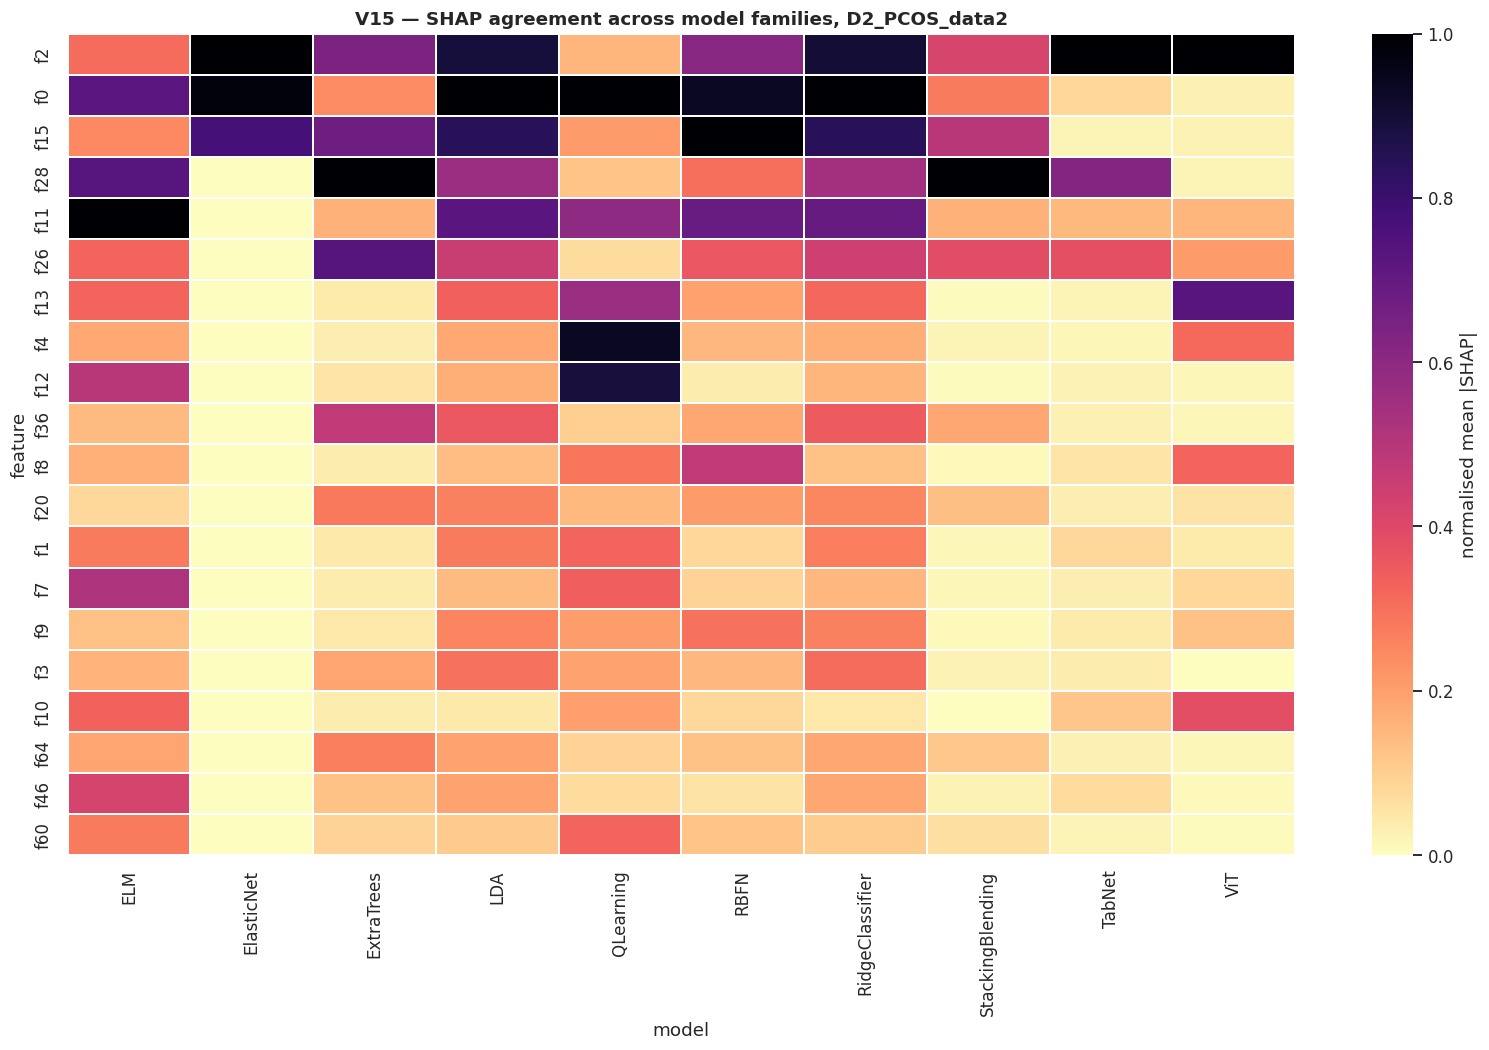

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V15_shap_consensus_D3_PCOSdata1.png


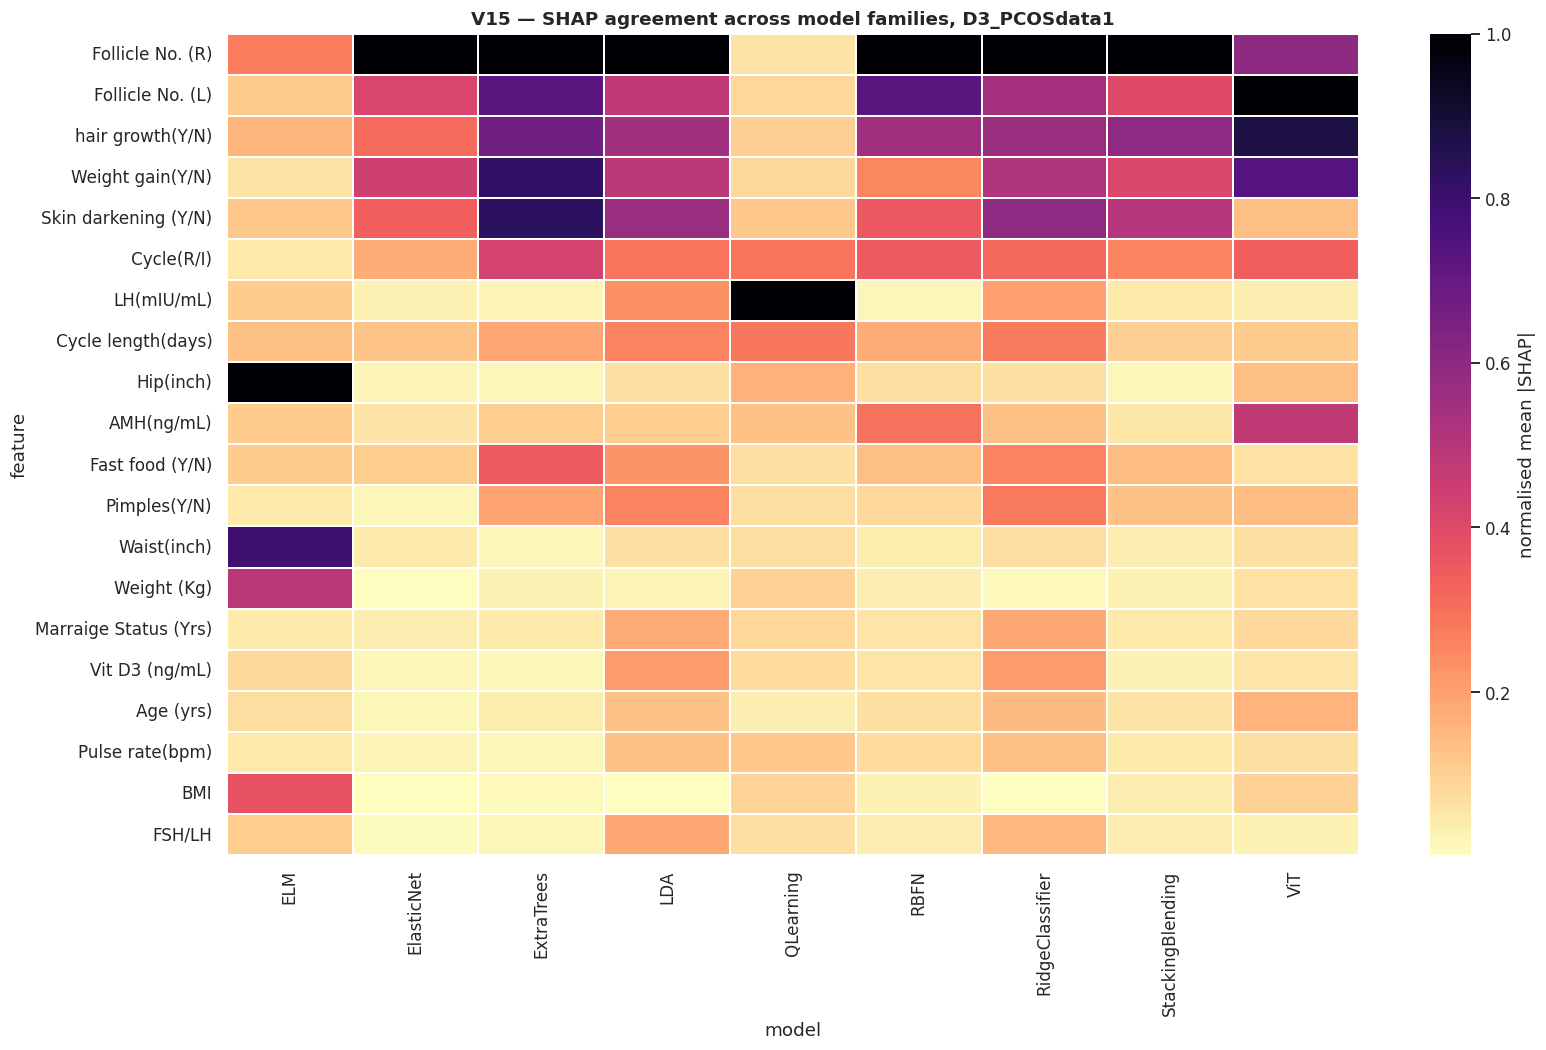

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V16_learning_curve_D1_PCOS_data.png


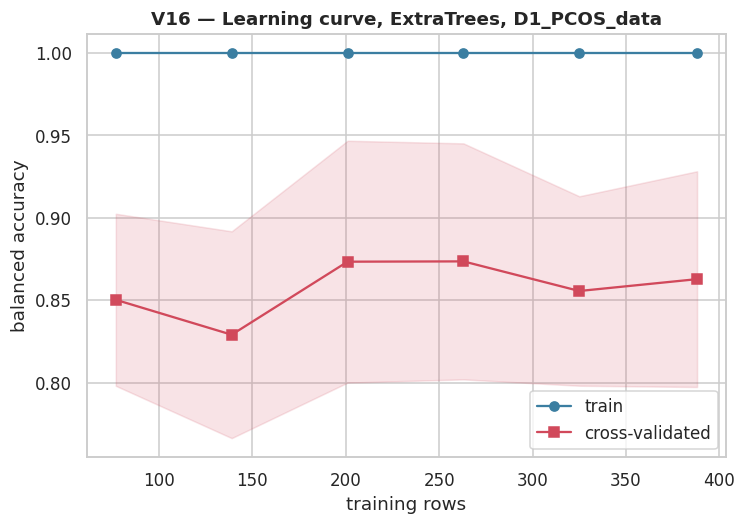

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V16_learning_curve_D2_PCOS_data2.png


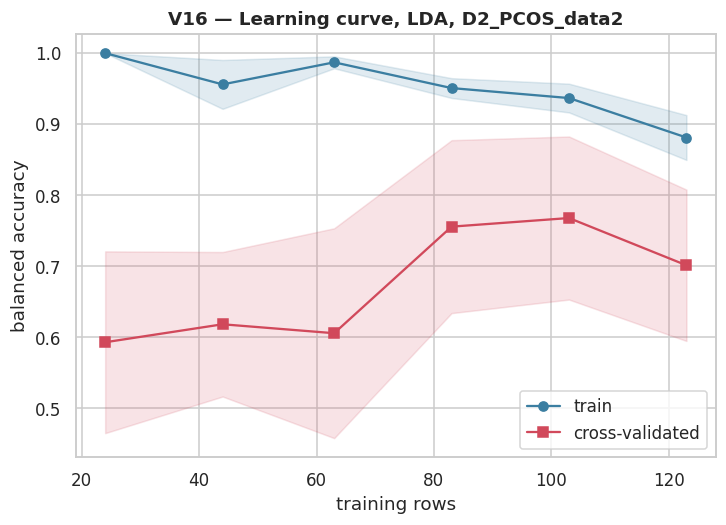

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V16_learning_curve_D3_PCOSdata1.png


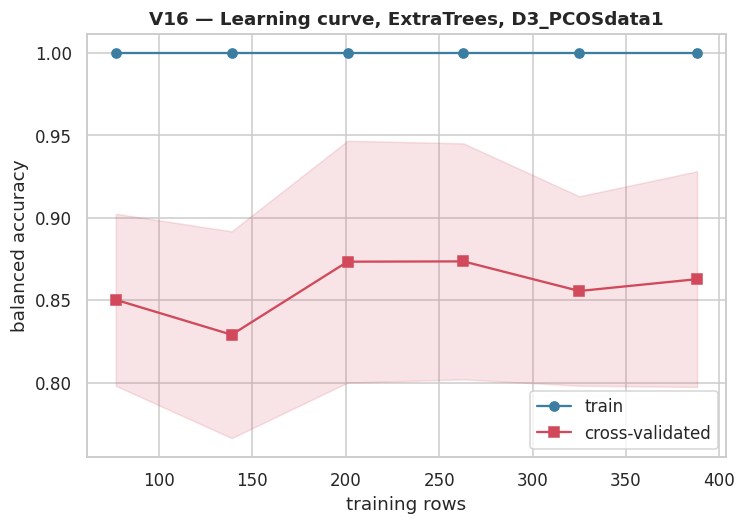

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V17_radar_D1_PCOS_data.png


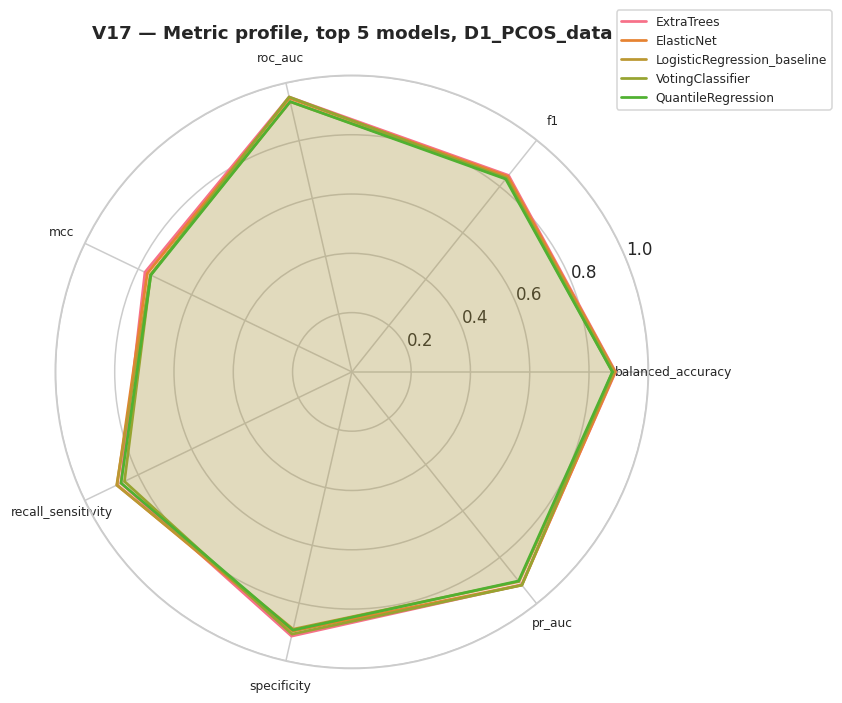

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V17_radar_D2_PCOS_data2.png


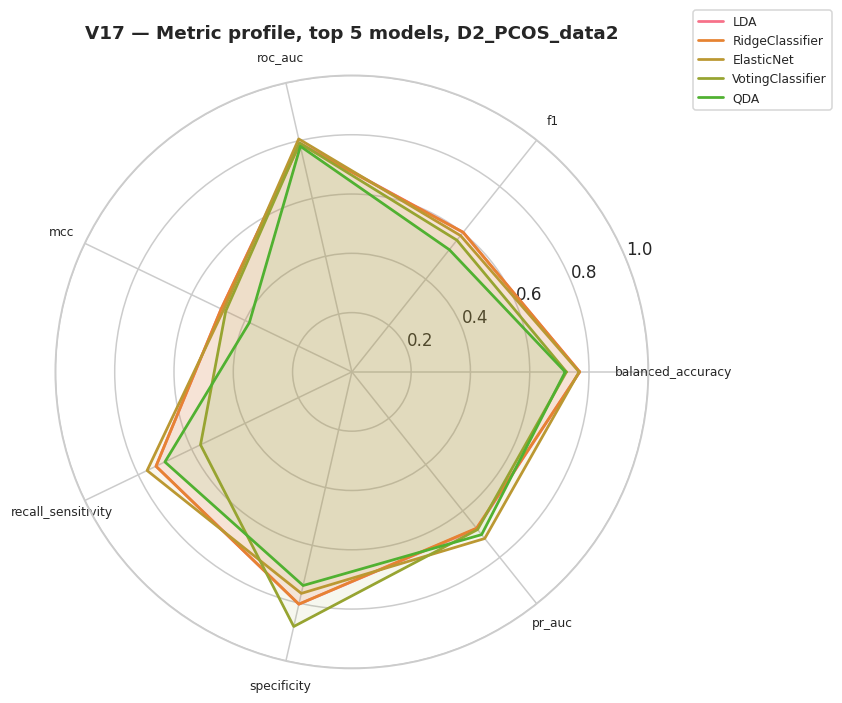

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V17_radar_D3_PCOSdata1.png


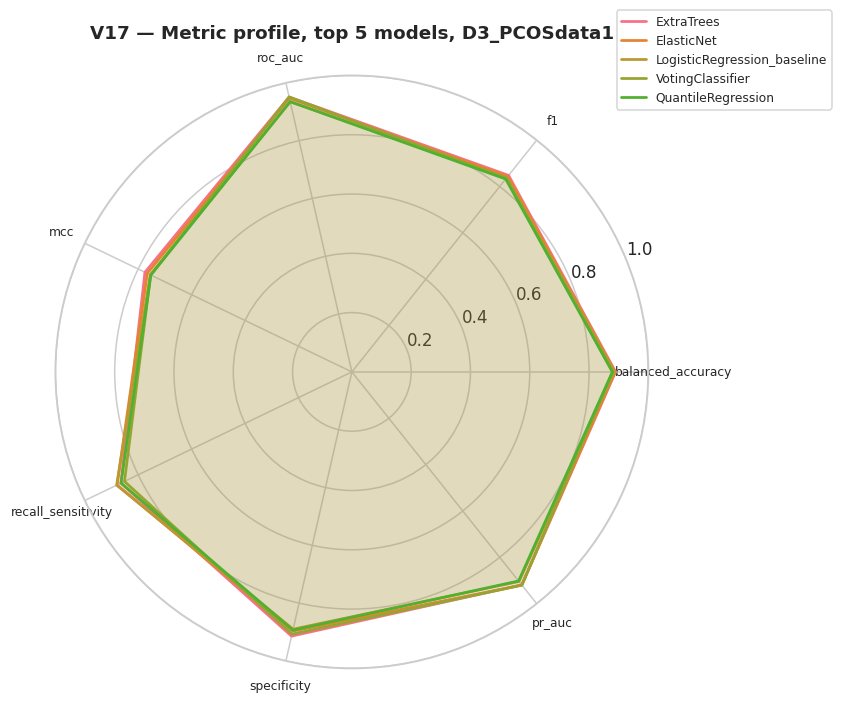

  saved -> /content/drive/MyDrive/PCOD/outputs/figures/V18_accuracy_vs_cost.png


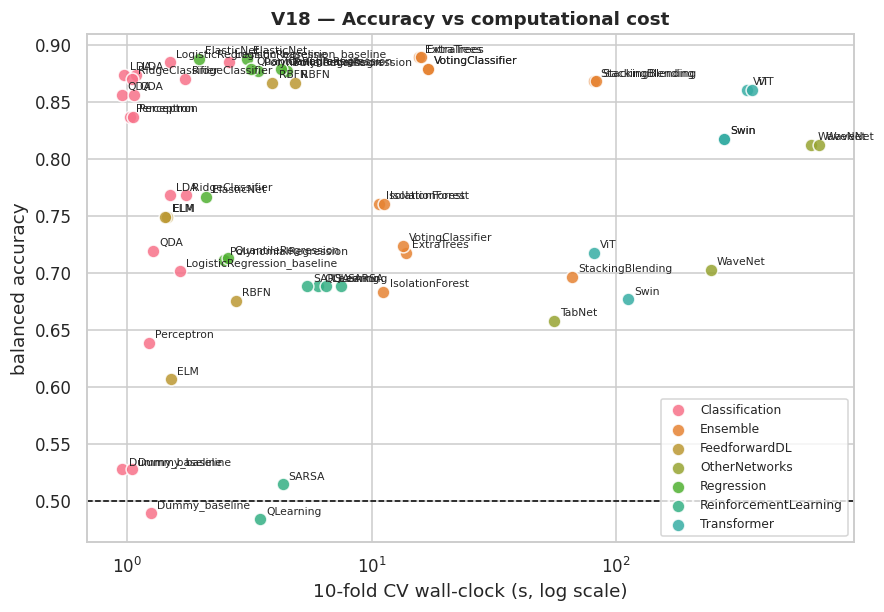


all figures written to: /content/drive/MyDrive/PCOD/outputs/figures


In [33]:


PALETTE = sns.color_palette("husl", 12)


def _top_mi_features(ds, k=6):
    X = ds["X"][ds["num_cols"]].fillna(ds["X"][ds["num_cols"]].median())
    if X.shape[1] == 0:
        return []
    mi = mutual_info_classif(X, ds["y"], random_state=SEED)
    return list(pd.Series(mi, index=X.columns).sort_values(ascending=False).head(k).index)


# ---- V01 ---------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.6 * len(DATASETS), 4), squeeze=False)
for ax, d in zip(axes[0], DATASETS):
    vc = pd.Series(d["y"]).value_counts().sort_index()
    ax.bar(["No PCOS", "PCOS"], vc.values, color=["#4C9F70", "#D1495B"])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v}\n({v/vc.sum()*100:.1f}%)", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{d['name']}\nn={len(d['y'])}, {d['X'].shape[1]} raw features", fontsize=10)
    ax.set_ylabel("patients")
fig.suptitle("V01 — Class balance per dataset", y=1.03, fontsize=13, weight="bold")
savefig(fig, "V01_class_balance")

# ---- V02 ---------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 4.4), squeeze=False)
for ax, d in zip(axes[0], DATASETS):
    miss = d["X"].isna().mean().sort_values(ascending=False).head(25)
    if miss.sum() == 0:
        ax.text(.5, .5, "no missing values", ha="center", va="center"); ax.set_axis_off()
    else:
        sns.barplot(x=miss.values * 100, y=miss.index, ax=ax, color="#3B7EA1")
        ax.set_xlabel("% missing")
    ax.set_title(d["name"], fontsize=10)
fig.suptitle("V02 — Missing-value profile (top 25 columns)", y=1.02, fontsize=13, weight="bold")
savefig(fig, "V02_missingness")

# ---- V03 ---------------------------------------------------------------------------------
for d in DATASETS:
    num = d["X"][d["num_cols"]]
    if num.shape[1] < 3:
        continue
    keep = num.columns[:30]
    C = pd.concat([num[keep], pd.Series(d["y"], name="PCOS")], axis=1).corr()
    fig, ax = plt.subplots(figsize=(min(14, 0.42 * len(C) + 3), min(12, 0.40 * len(C) + 3)))
    sns.heatmap(C, cmap="RdBu_r", center=0, square=True, linewidths=.3,
                cbar_kws=dict(shrink=.7), ax=ax,
                annot=len(C) <= 14, fmt=".2f", annot_kws=dict(size=7))
    ax.set_title(f"V03 — Correlation matrix, {d['name']}", fontsize=12, weight="bold")
    savefig(fig, f"V03_correlation_{d['name']}")

# ---- V04 ---------------------------------------------------------------------------------
for d in DATASETS:
    top = _top_mi_features(d, 6)
    if not top:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, c in zip(axes.ravel(), top):
        sub = pd.DataFrame({c: d["X"][c], "PCOS": np.where(np.asarray(d["y"]) == 1, "PCOS", "No PCOS")})
        sns.violinplot(data=sub, x="PCOS", y=c, ax=ax, hue="PCOS", legend=False,
                       palette=["#4C9F70", "#D1495B"], cut=0, inner="quart")
        ax.set_title(c[:38], fontsize=9); ax.set_xlabel("")
    for ax in axes.ravel()[len(top):]:
        ax.set_axis_off()
    fig.suptitle(f"V04 — Top mutual-information features by class, {d['name']}",
                 y=1.01, fontsize=13, weight="bold")
    fig.tight_layout()
    savefig(fig, f"V04_top_features_{d['name']}")

# ---- V05 ---------------------------------------------------------------------------------
for d in DATASETS:
    prep = Pipeline([("prep", build_preprocessor(d["num_cols"], d["cat_cols"])),
                     ("var", VarianceThreshold(1e-8))])
    M = prep.fit_transform(d["X"], d["y"])
    pca = PCA(n_components=2, random_state=SEED).fit(M)
    P = pca.transform(M)
    perp = max(5, min(30, len(M) // 4))
    T = TSNE(n_components=2, perplexity=perp, random_state=SEED, init="pca").fit_transform(M)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for ax, E, ttl in [(axes[0], P, f"PCA ({pca.explained_variance_ratio_.sum()*100:.1f}% var)"),
                       (axes[1], T, f"t-SNE (perplexity {perp})")]:
        for cls, col, lab in [(0, "#4C9F70", "No PCOS"), (1, "#D1495B", "PCOS")]:
            m = np.asarray(d["y"]) == cls
            ax.scatter(E[m, 0], E[m, 1], s=18, alpha=.75, c=col, label=lab, edgecolor="none")
        ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
    full = PCA(n_components=min(20, M.shape[1]), random_state=SEED).fit(M)
    axes[2].plot(np.arange(1, len(full.explained_variance_ratio_) + 1),
                 np.cumsum(full.explained_variance_ratio_), "o-", color="#3B7EA1")
    axes[2].axhline(.90, ls="--", c="grey"); axes[2].set_xlabel("components")
    axes[2].set_ylabel("cumulative explained variance"); axes[2].set_title("PCA scree", fontsize=10)
    fig.suptitle(f"V05 — Low-dimensional structure, {d['name']}", y=1.03, fontsize=13, weight="bold")
    fig.tight_layout()
    savefig(fig, f"V05_embeddings_{d['name']}")

# ---- V06 ---------------------------------------------------------------------------------
if HAS_IMBLEARN and CFG["RESAMPLER"] not in (None, "none"):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.6 * len(DATASETS), 4), squeeze=False)
    for ax, d in zip(axes[0], DATASETS):
        sp = d["splits"][PRIMARY_TAG]
        Xtr, ytr, _, _ = fit_transform_matrix(d, sp["X_train"], sp["y_train"], sp["X_test"], True)
        before = pd.Series(sp["y_train"]).value_counts().sort_index()
        after = pd.Series(ytr).value_counts().sort_index()
        w, x = 0.38, np.arange(2)
        ax.bar(x - w/2, before.reindex([0, 1]).fillna(0), w, label="before", color="#8E9AAF")
        ax.bar(x + w/2, after.reindex([0, 1]).fillna(0), w, label=CFG["RESAMPLER"], color="#D1495B")
        ax.set_xticks(x); ax.set_xticklabels(["No PCOS", "PCOS"]); ax.legend(fontsize=8)
        ax.set_title(d["name"], fontsize=10)
    fig.suptitle(f"V06 — Training-fold class balance before/after {CFG['RESAMPLER'].upper()}",
                 y=1.03, fontsize=13, weight="bold")
    savefig(fig, "V06_resampling")

# ---- V07 ---------------------------------------------------------------------------------
if "cv_balanced_accuracy_mean" in RES.columns:
    sub = RES[(RES.split == PRIMARY_TAG) & RES.cv_balanced_accuracy_mean.notna()]
    for dname, g in sub.groupby("dataset"):
        g = g.sort_values("cv_balanced_accuracy_mean")
        fig, ax = plt.subplots(figsize=(9, 0.42 * len(g) + 2))
        fams = sorted(g.family.unique())
        cmap = {f: PALETTE[i % len(PALETTE)] for i, f in enumerate(fams)}
        ax.barh(g.model, g.cv_balanced_accuracy_mean,
                xerr=g.cv_balanced_accuracy_std, color=[cmap[f] for f in g.family],
                error_kw=dict(ecolor="grey", lw=1, capsize=3))
        ax.axvline(0.5, ls="--", c="black", lw=1, label="chance")
        for y_, v in zip(range(len(g)), g.cv_balanced_accuracy_mean):
            ax.text(v + .008, y_, f"{v:.3f}", va="center", fontsize=8)
        handles = [plt.Rectangle((0, 0), 1, 1, color=cmap[f]) for f in fams]
        ax.legend(handles, fams, fontsize=8, loc="lower right")
        ax.set_xlim(0.3, 1.0); ax.set_xlabel("stratified 10-fold balanced accuracy")
        ax.set_title(f"V07 — Model leaderboard, {dname} ({PRIMARY_TAG})", fontsize=12, weight="bold")
        savefig(fig, f"V07_leaderboard_{dname}")

# ---- V08 ---------------------------------------------------------------------------------
if "cv_balanced_accuracy_mean" in RES.columns:
    for dname, g in RES[RES.cv_balanced_accuracy_mean.notna()].groupby("dataset"):
        piv = g.pivot_table(index="model", columns="split", values="cv_balanced_accuracy_mean")
        order = [c for c in ["70:30", "80:20", "90:10"] if c in piv.columns]
        piv = piv[order].sort_values(order[-1] if order else piv.columns[0], ascending=False)
        fig, ax = plt.subplots(figsize=(max(9, 0.55 * len(piv)), 5))
        piv.plot(kind="bar", ax=ax, width=.8, colormap="viridis")
        ax.axhline(.5, ls="--", c="black", lw=1)
        ax.set_ylabel("CV balanced accuracy"); ax.set_ylim(0.3, 1.0)
        ax.set_title(f"V08 — Split-ratio sensitivity, {dname}", fontsize=12, weight="bold")
        ax.legend(title="train:test", fontsize=8)
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
        savefig(fig, f"V08_split_ratio_{dname}")

# ---- V09 / V10 ----------------------------------------------------------------------------
def curve_panel(dname, kind="roc", topn=8):
    keys = [k for k in ARTIFACTS if k[0] == dname and k[1] == PRIMARY_TAG]
    if not keys:
        return
    sc = {k: roc_auc_score(ARTIFACTS[k]["y_test"], ARTIFACTS[k]["test_score"])
          if len(np.unique(ARTIFACTS[k]["y_test"])) > 1 else .5 for k in keys}
    keys = sorted(keys, key=lambda k: -sc[k])[:topn]
    fig, ax = plt.subplots(figsize=(7.2, 6))
    for i, k in enumerate(keys):
        a = ARTIFACTS[k]
        if kind == "roc":
            fpr, tpr, _ = roc_curve(a["y_test"], a["test_score"])
            ax.plot(fpr, tpr, lw=1.8, color=PALETTE[i % len(PALETTE)],
                    label=f"{k[2]} (AUC {sc[k]:.3f})")
        else:
            pr, rc, _ = precision_recall_curve(a["y_test"], a["test_score"])
            ap = average_precision_score(a["y_test"], a["test_score"])
            ax.plot(rc, pr, lw=1.8, color=PALETTE[i % len(PALETTE)], label=f"{k[2]} (AP {ap:.3f})")
    if kind == "roc":
        ax.plot([0, 1], [0, 1], "k--", lw=1)
        ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
        ax.set_title(f"V09 — ROC on the untouched hold-out, {dname}", fontsize=12, weight="bold")
    else:
        base = np.mean(ARTIFACTS[keys[0]]["y_test"])
        ax.axhline(base, ls="--", c="k", lw=1, label=f"prevalence {base:.2f}")
        ax.set_xlabel("recall"); ax.set_ylabel("precision")
        ax.set_title(f"V10 — Precision-recall, {dname}", fontsize=12, weight="bold")
    ax.legend(fontsize=8, loc="lower right" if kind == "roc" else "upper right")
    savefig(fig, f"{'V09_roc' if kind=='roc' else 'V10_pr'}_{dname}")


for d in DATASETS:
    curve_panel(d["name"], "roc")
    curve_panel(d["name"], "pr")

# ---- V11 ---------------------------------------------------------------------------------
for d in DATASETS:
    keys = [k for k in ARTIFACTS if k[0] == d["name"] and k[1] == PRIMARY_TAG]
    keys = sorted(keys, key=lambda k: -balanced_accuracy_score(ARTIFACTS[k]["y_test"],
                                                               ARTIFACTS[k]["test_pred"]))[:6]
    if not keys:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.4))
    for ax, k in zip(axes.ravel(), keys):
        a = ARTIFACTS[k]
        cm = confusion_matrix(a["y_test"], a["test_pred"], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
        ax.set_title(f"{k[2]}\nbal-acc {balanced_accuracy_score(a['y_test'], a['test_pred']):.3f}",
                     fontsize=9)
    for ax in axes.ravel()[len(keys):]:
        ax.set_axis_off()
    fig.suptitle(f"V11 — Hold-out confusion matrices, {d['name']}", y=1.01, fontsize=13, weight="bold")
    fig.tight_layout()
    savefig(fig, f"V11_confusion_{d['name']}")

# ---- V12 ---------------------------------------------------------------------------------
if len(FOLDS):
    for dname, g in FOLDS[FOLDS.split == PRIMARY_TAG].groupby("dataset"):
        order = g.groupby("model").balanced_accuracy.median().sort_values().index
        fig, ax = plt.subplots(figsize=(9, 0.42 * g.model.nunique() + 2))
        sns.boxplot(data=g, y="model", x="balanced_accuracy", order=order, ax=ax,
                    hue="model", legend=False, palette="Spectral", fliersize=2)
        sns.stripplot(data=g, y="model", x="balanced_accuracy", order=order, ax=ax,
                      color="black", size=2.5, alpha=.5)
        ax.axvline(.5, ls="--", c="black", lw=1)
        ax.set_title(f"V12 — Per-fold spread across {CFG['CV_FOLDS']} folds, {dname}",
                     fontsize=12, weight="bold")
        savefig(fig, f"V12_fold_spread_{dname}")

# ---- V13 ---------------------------------------------------------------------------------
for d in DATASETS:
    keys = [k for k in ARTIFACTS if k[0] == d["name"] and k[1] == PRIMARY_TAG]
    keys = sorted(keys, key=lambda k: -balanced_accuracy_score(ARTIFACTS[k]["y_test"],
                                                               ARTIFACTS[k]["test_pred"]))[:6]
    if not keys:
        continue
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly calibrated")
    for i, k in enumerate(keys):
        a = ARTIFACTS[k]
        p = minmax_prob(a["test_score"])
        nb = max(3, min(8, len(p) // 12))
        try:
            fr, mp = calibration_curve(a["y_test"], p, n_bins=nb, strategy="quantile")
            ax.plot(mp, fr, "o-", ms=4, lw=1.5, color=PALETTE[i % len(PALETTE)],
                    label=f"{k[2]} (Brier {brier_score_loss(a['y_test'], p):.3f})")
        except Exception:
            pass
    ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency")
    ax.set_title(f"V13 — Calibration, {d['name']}", fontsize=12, weight="bold")
    ax.legend(fontsize=8)
    savefig(fig, f"V13_calibration_{d['name']}")

# ---- V14 / V15 -----------------------------------------------------------------------------
if SHAP_STORE:
    for (dname, tag, mname), v in SHAP_STORE.items():
        if mname != "ExtraTrees":
            continue
        fig = plt.figure(figsize=(9, 6))
        shap.summary_plot(v["values"], v["X"], feature_names=v["names"], show=False, max_display=18)
        plt.title(f"V14 — SHAP beeswarm, {mname}, {dname}", fontsize=12, weight="bold")
        savefig(plt.gcf(), f"V14_shap_beeswarm_{dname}_{mname}")

        fig, ax = plt.subplots(figsize=(8, 6))
        imp = v["importance"].head(18).iloc[::-1]
        ax.barh(imp.feature, imp.mean_abs_shap, color="#D1495B")
        ax.set_xlabel("mean |SHAP value|")
        ax.set_title(f"V14b — SHAP importance, {mname}, {dname}", fontsize=12, weight="bold")
        savefig(fig, f"V14b_shap_bar_{dname}_{mname}")

if len(SHAP_IMPORTANCE):
    for dname, g in SHAP_IMPORTANCE.groupby("dataset"):
        piv = g.pivot_table(index="feature", columns="model", values="mean_abs_shap", aggfunc="mean")
        piv = piv.div(piv.max(axis=0), axis=1).fillna(0)          # per-model min-max for comparability
        piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).head(20).index]
        fig, ax = plt.subplots(figsize=(1.4 * piv.shape[1] + 4, 0.36 * len(piv) + 2.5))
        sns.heatmap(piv, cmap="magma_r", annot=False, linewidths=.3, ax=ax,
                    cbar_kws=dict(label="normalised mean |SHAP|"))
        ax.set_title(f"V15 — SHAP agreement across model families, {dname}", fontsize=12, weight="bold")
        savefig(fig, f"V15_shap_consensus_{dname}")

# ---- V16 -----------------------------------------------------------------------------------
if "cv_balanced_accuracy_mean" in RES.columns and RES.cv_balanced_accuracy_mean.notna().any():
    for dname, g in RES[(RES.split == PRIMARY_TAG) & RES.cv_balanced_accuracy_mean.notna()].groupby("dataset"):
        bm = g.sort_values("cv_balanced_accuracy_mean", ascending=False).iloc[0]["model"]
        d = next(x for x in DATASETS if x["name"] == dname)
        sp = d["splits"][PRIMARY_TAG]
        pipe = build_full_pipeline(clone(MODEL_REGISTRY[bm]["estimator"]),
                                   d["num_cols"], d["cat_cols"], sp["y_train"])
        try:
            sizes, tr, te = learning_curve(
                pipe, sp["X_train"], sp["y_train"], cv=cv_iter(sp["y_train"]),
                train_sizes=np.linspace(.2, 1.0, 6), scoring="balanced_accuracy",
                n_jobs=1 if bm in DL_MODELS else -1, random_state=SEED)
            fig, ax = plt.subplots(figsize=(7.5, 5))
            ax.plot(sizes, tr.mean(1), "o-", color="#3B7EA1", label="train")
            ax.fill_between(sizes, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), alpha=.15, color="#3B7EA1")
            ax.plot(sizes, te.mean(1), "s-", color="#D1495B", label="cross-validated")
            ax.fill_between(sizes, te.mean(1) - te.std(1), te.mean(1) + te.std(1), alpha=.15, color="#D1495B")
            ax.set_xlabel("training rows"); ax.set_ylabel("balanced accuracy")
            ax.set_title(f"V16 — Learning curve, {bm}, {dname}", fontsize=12, weight="bold")
            ax.legend()
            savefig(fig, f"V16_learning_curve_{dname}")
        except Exception as e:
            print("  learning curve skipped:", e)

# ---- V17 -----------------------------------------------------------------------------------
RADAR = ["cv_balanced_accuracy_mean", "cv_f1_mean", "cv_roc_auc_mean", "cv_mcc_mean",
         "cv_recall_sensitivity_mean", "cv_specificity_mean", "cv_pr_auc_mean"]
if all(c in RES.columns for c in RADAR):
    for dname, g in RES[(RES.split == PRIMARY_TAG)].dropna(subset=RADAR).groupby("dataset"):
        top = g.sort_values("cv_balanced_accuracy_mean", ascending=False).head(5)
        labels = [c.replace("cv_", "").replace("_mean", "") for c in RADAR]
        ang = np.linspace(0, 2 * np.pi, len(RADAR), endpoint=False).tolist(); ang += ang[:1]
        fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
        for i, (_, r) in enumerate(top.iterrows()):
            vals = [max(0, float(r[c])) for c in RADAR]; vals += vals[:1]
            ax.plot(ang, vals, lw=1.8, color=PALETTE[i], label=r["model"])
            ax.fill(ang, vals, alpha=.08, color=PALETTE[i])
        ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(f"V17 — Metric profile, top 5 models, {dname}", fontsize=12, weight="bold", pad=24)
        ax.legend(loc="upper right", bbox_to_anchor=(1.32, 1.12), fontsize=8)
        savefig(fig, f"V17_radar_{dname}")

# ---- V18 -----------------------------------------------------------------------------------
if {"cv_seconds", "cv_balanced_accuracy_mean"} <= set(RES.columns):
    sub = RES[(RES.split == PRIMARY_TAG)].dropna(subset=["cv_seconds", "cv_balanced_accuracy_mean"])
    if len(sub):
        fig, ax = plt.subplots(figsize=(9, 6))
        fams = sorted(sub.family.unique())
        for i, f in enumerate(fams):
            s = sub[sub.family == f]
            ax.scatter(s.cv_seconds, s.cv_balanced_accuracy_mean, s=70, alpha=.85,
                       color=PALETTE[i % len(PALETTE)], label=f, edgecolor="white")
        for _, r in sub.iterrows():
            ax.annotate(r.model, (r.cv_seconds, r.cv_balanced_accuracy_mean),
                        fontsize=7, xytext=(4, 3), textcoords="offset points")
        ax.set_xscale("log"); ax.set_xlabel("10-fold CV wall-clock (s, log scale)")
        ax.set_ylabel("balanced accuracy"); ax.axhline(.5, ls="--", c="black", lw=1)
        ax.set_title("V18 — Accuracy vs computational cost", fontsize=12, weight="bold")
        ax.legend(fontsize=8)
        savefig(fig, "V18_accuracy_vs_cost")

print(f"\nall figures written to: {FIGS}")



## Cell 17

In [34]:
# ==========================================================================================
# CELL 17 — BEST MODEL SELECTION + FINAL VERIFICATION ON THE RESERVED TEST DATASET
# ==========================================================================================
# Selection rule (fixed in advance, so it is not cherry-picking):
#     rank by mean stratified 10-fold balanced accuracy on the training portion,
#     break ties by ROC-AUC, then by the CV/hold-out gap (smaller = less memorisation).
# The reserved dataset (CFG['TEST_DATASET']) is only used here, at the very end.
# ------------------------------------------------------------------------------------------

reserved test dataset: D3_PCOSdata1  (X=(541, 41))

PER-DATASET WINNERS
D1_PCOS_data                 -> ExtraTrees             (Ensemble)  CV bal-acc 0.8894 +/- 0.0605  AUC 0.9511  hold-out 0.9032  gap 0.0137
D2_PCOS_data2                -> LDA                    (Classification)  CV bal-acc 0.7685 +/- 0.1113  AUC 0.7918  hold-out 0.8889  gap 0.1204
D3_PCOSdata1                 -> ExtraTrees             (Ensemble)  CV bal-acc 0.8894 +/- 0.0605  AUC 0.9511  hold-out 0.9032  gap 0.0137

global best : ExtraTrees (Ensemble) on D1_PCOS_data at split 80:20
              CV bal-acc 0.8894, hold-out 0.9032

FINAL VERIFICATION ON D3_PCOSdata1
schemas differ -> verifying on the reserved dataset's own untouched hold-out
[final fit] 1.8s

model        : ExtraTrees  (Ensemble)
protocol     : internal hold-out (never seen during CV or tuning)
train / test : 432 / 109

------------------------------------------------------------
  accuracy               0.9174
  balanced_accuracy      0.9032
  precis

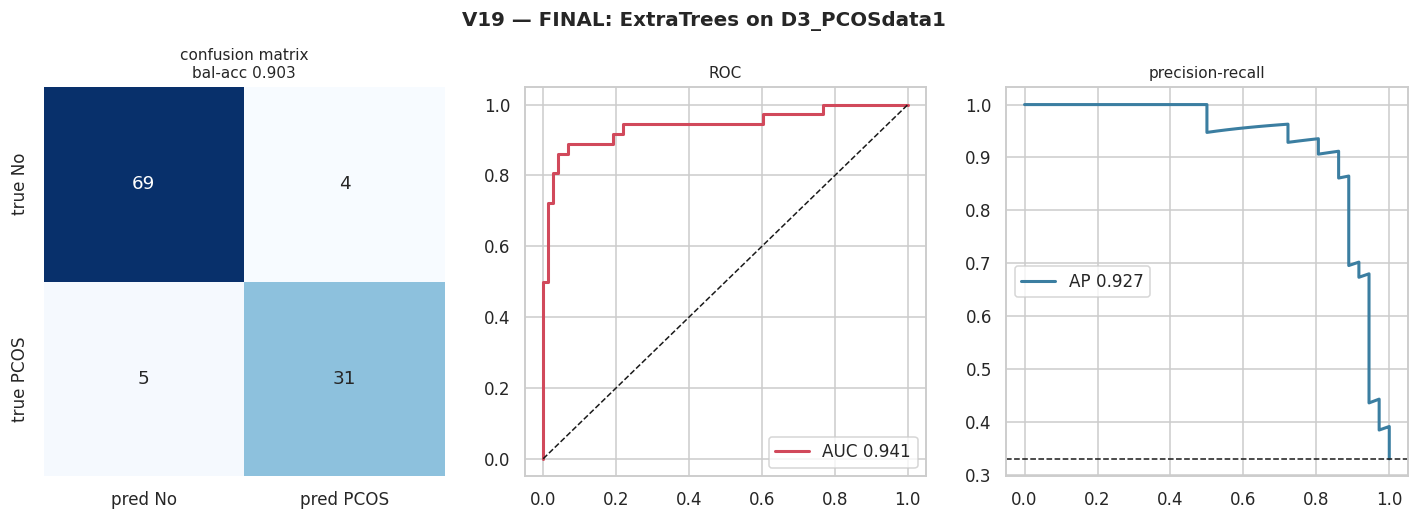


model saved -> /content/drive/MyDrive/PCOD/outputs/models/best_ExtraTrees_D3_PCOSdata1_20260814_030459.joblib
  saved -> /content/drive/MyDrive/PCOD/outputs/tables/05_final_metrics_20260814_030459.csv
  saved -> /content/drive/MyDrive/PCOD/outputs/tables/06_dataset_winners_20260814_030459.csv
summary saved -> /content/drive/MyDrive/PCOD/outputs/run_summary_20260814_030459.json

DONE
  figures : /content/drive/MyDrive/PCOD/outputs/figures
  tables  : /content/drive/MyDrive/PCOD/outputs/tables
  models  : /content/drive/MyDrive/PCOD/outputs/models

  Reality check before you write this up:
   * compare every deep model against LogisticRegression_baseline on the SAME folds. At a few
     hundred rows a linear model frequently matches ViT / Swin / TabNet. If it does, that is
     the finding — report it.
   * Dummy_baseline shows what chance looks like given this class balance. Anything close to
     it is not learning.
   * the CV/hold-out gap column is the memorisation check. A gap abov

In [37]:
import joblib

TEST_DS = DATASETS[CFG["TEST_DATASET"]]
print(f"reserved test dataset: {TEST_DS['name']}  (X={TEST_DS['X'].shape})")

valid = RES[RES.get("cv_balanced_accuracy_mean").notna()] if "cv_balanced_accuracy_mean" in RES else pd.DataFrame()
if len(valid) == 0:
    raise SystemExit("nothing to select from — every model failed, check the logs above")

valid = valid.copy()
valid["gap"] = (valid["cv_balanced_accuracy_mean"] - valid["holdout_balanced_accuracy"]).abs()

print(f"\n{'='*90}\nPER-DATASET WINNERS\n{'='*90}")
winners = {}
for dname, g in valid.groupby("dataset"):
    g = g[g.split == PRIMARY_TAG].sort_values(
        ["cv_balanced_accuracy_mean", "cv_roc_auc_mean", "gap"], ascending=[False, False, True])
    w = g.iloc[0]
    winners[dname] = w
    print(f"{dname:28s} -> {w['model']:22s} ({w['family']})  "
          f"CV bal-acc {w['cv_balanced_accuracy_mean']:.4f} +/- {w['cv_balanced_accuracy_std']:.4f}  "
          f"AUC {w['cv_roc_auc_mean']:.4f}  hold-out {w['holdout_balanced_accuracy']:.4f}  "
          f"gap {w['gap']:.4f}")

# ---- the global best across all datasets and split ratios ---------------------------------
gbest = valid.sort_values(["cv_balanced_accuracy_mean", "cv_roc_auc_mean", "gap"],
                          ascending=[False, False, True]).iloc[0]
print(f"\nglobal best : {gbest['model']} ({gbest['family']}) on {gbest['dataset']} at split {gbest['split']}")
print(f"              CV bal-acc {gbest['cv_balanced_accuracy_mean']:.4f}, "
      f"hold-out {gbest['holdout_balanced_accuracy']:.4f}")

# ---- final verification on the reserved dataset ---------------------------------------------
print(f"\n{'='*90}\nFINAL VERIFICATION ON {TEST_DS['name']}\n{'='*90}")

best_for_test = winners.get(TEST_DS["name"], gbest)["model"]
# Check for actual shared features between the target test dataset and all other datasets that would be used for training.
_potential_training_datasets_for_external_val = [d for d in DATASETS if d["name"] != TEST_DS["name"]]
_all_cols_involved_in_external_val = [set(d["X"].columns) for d in _potential_training_datasets_for_external_val] + [set(TEST_DS["X"].columns)]
actual_shared_features_for_external_val = sorted(set.intersection(*_all_cols_involved_in_external_val))

# Condition for external validation: CROSS_DATASET_OK is True, the global best model was found on a different dataset than the test dataset, AND there are actually shared features between all datasets involved in the external validation.
if CROSS_DATASET_OK and gbest["dataset"] != TEST_DS["name"] and len(actual_shared_features_for_external_val) > 0:
    # schemas align -> genuine external validation: train on the other datasets, test on this one
    print("schemas align -> training on the remaining datasets and testing on the reserved one")
    others = _potential_training_datasets_for_external_val
    shared = actual_shared_features_for_external_val
    Xtr = pd.concat([d["X"][shared] for d in others], ignore_index=True)
    ytr = np.concatenate([np.asarray(d["y"]) for d in others])
    Xte, yte = TEST_DS["X"][shared].reset_index(drop=True), np.asarray(TEST_DS["y"])

    # Dynamically determine numeric and categorical columns from the concatenated training data
    _Xtr_temp = pd.concat([d["X"][shared] for d in others], ignore_index=True)
    _num_shared = _Xtr_temp.select_dtypes(include=[np.number]).columns.tolist()
    _cat_shared = [c for c in shared if c not in _num_shared]

    final_pipe = build_full_pipeline(clone(MODEL_REGISTRY[gbest["model"]]["estimator"]), _num_shared, _cat_shared, ytr)
    mode = "external validation (trained on other datasets)"
else:
    # schemas differ -> the honest option is the reserved dataset's own untouched hold-out
    print("schemas differ -> verifying on the reserved dataset's own untouched hold-out")
    sp = TEST_DS["splits"][PRIMARY_TAG]
    Xtr, ytr, Xte, yte = sp["X_train"], sp["y_train"], sp["X_test"], sp["y_test"]
    final_pipe = build_full_pipeline(clone(MODEL_REGISTRY[best_for_test]["estimator"]),
                                     TEST_DS["num_cols"], TEST_DS["cat_cols"], ytr)
    prm = winners.get(TEST_DS["name"], {}).get("best_params", "{}")
    try:
        prm = {f"clf__{k}": v for k, v in json.loads(prm).items()}
        if prm:
            final_pipe.set_params(**prm)
    except Exception:
        pass
    gbest = winners.get(TEST_DS["name"], gbest)
    mode = "internal hold-out (never seen during CV or tuning)"

with Timer("final fit"):
    final_pipe.fit(Xtr, ytr)

s = get_scores(final_pipe, Xte)
p = final_pipe.predict(Xte)
final_metrics = classification_metrics(yte, p, s)

print(f"\nmodel        : {gbest['model']}  ({gbest['family']})")
print(f"protocol     : {mode}")
print(f"train / test : {len(ytr)} / {len(yte)}")
print(f"\n{'-'*60}")
for k, v in final_metrics.items():
    print(f"  {k:22s} {v:.4f}" if isinstance(v, float) else f"  {k:22s} {v}")
print(f"{'-'*60}")
print("\n" + classification_report(yte, p, target_names=["No PCOS", "PCOS"], zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
cm = confusion_matrix(yte, p, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred No", "pred PCOS"], yticklabels=["true No", "true PCOS"])
axes[0].set_title(f"confusion matrix\nbal-acc {final_metrics['balanced_accuracy']:.3f}", fontsize=10)
if len(np.unique(yte)) > 1:
    fpr, tpr, _ = roc_curve(yte, s)
    axes[1].plot(fpr, tpr, lw=2, color="#D1495B", label=f"AUC {final_metrics['roc_auc']:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].legend(); axes[1].set_title("ROC", fontsize=10)
    pr, rc, _ = precision_recall_curve(yte, s)
    axes[2].plot(rc, pr, lw=2, color="#3B7EA1", label=f"AP {final_metrics['pr_auc']:.3f}")
    axes[2].axhline(np.mean(yte), ls="--", c="k", lw=1); axes[2].legend()
    axes[2].set_title("precision-recall", fontsize=10)
fig.suptitle(f"V19 — FINAL: {gbest['model']} on {TEST_DS['name']}", y=1.03, fontsize=13, weight="bold")
savefig(fig, f"V19_final_{TEST_DS['name']}_{gbest['model']}")

# ---- persist everything ----------------------------------------------------------------------
model_path = MODELS / f"best_{gbest['model']}_{TEST_DS['name']}_{RUN_ID}.joblib"
joblib.dump(dict(pipeline=final_pipe, model_name=gbest["model"], family=gbest["family"],
                 dataset=TEST_DS["name"], protocol=mode, feature_names=list(Xtr.columns),
                 metrics=final_metrics, config=CFG, run_id=RUN_ID), model_path)
print(f"\nmodel saved -> {model_path}")

savetable(pd.DataFrame([final_metrics]).assign(model=gbest["model"], dataset=TEST_DS["name"],
                                               protocol=mode), f"05_final_metrics_{RUN_ID}")
savetable(pd.DataFrame(winners).T.reset_index(drop=True), f"06_dataset_winners_{RUN_ID}")

summary = dict(run_id=RUN_ID, timestamp=datetime.now().isoformat(),
               datasets={d["name"]: dict(shape=list(d["X"].shape), positives=int(np.sum(d["y"])),
                                         features=len(d["feat_names"])) for d in DATASETS},
               config={k: (str(v) if not isinstance(v, (int, float, bool, str, list, type(None))) else v)
                       for k, v in CFG.items()},
               models_run=list(MODEL_REGISTRY.keys()),
               global_best=dict(model=str(gbest["model"]), dataset=str(gbest["dataset"]),
                                split=str(gbest["split"]),
                                cv_balanced_accuracy=float(gbest["cv_balanced_accuracy_mean"])),
               final=dict(dataset=TEST_DS["name"], model=str(gbest["model"]), protocol=mode,
                          metrics={k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                                   for k, v in final_metrics.items()}))
with open(OUT / f"run_summary_{RUN_ID}.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"summary saved -> {OUT / f'run_summary_{RUN_ID}.json'}")

print(f"""
{'='*90}
DONE
{'='*90}
  figures : {FIGS}
  tables  : {TABS}
  models  : {MODELS}

  Reality check before you write this up:
   * compare every deep model against LogisticRegression_baseline on the SAME folds. At a few
     hundred rows a linear model frequently matches ViT / Swin / TabNet. If it does, that is
     the finding — report it.
   * Dummy_baseline shows what chance looks like given this class balance. Anything close to
     it is not learning.
   * the CV/hold-out gap column is the memorisation check. A gap above ~0.05 with a small
     hold-out means the number is not stable; report the CV mean with its standard deviation,
     not the single best fold.
   * the regression models produce regression metrics too (cv_reg_* / holdout_reg_* columns)
     because thresholding a linear-probability model hides how poorly it fits a 0/1 target.
""")